# SECURITY NOTE

The uploaded notebook contained hard-coded API credentials in its original cells.
This revision removes exposed credentials and uses Colab Secrets for the YouTube API
key where the original collection cell requires it.

Set these in **Colab → Secrets** before running:
- `YOUTUBE_API_KEY`
- `GEMINI_API_KEY`

Never paste the secret values into the notebook or into chat.


In [1]:
#[REDACTED_SECRET]
#[REDACTED_SECRET]

In [2]:
!pip install google-api-python-client
!pip install youtube-transcript-api openai

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 485.2/485.2 kB 35.8 MB/s eta 0:00:00


In [3]:
from googleapiclient.discovery import build
import pandas as pd

# 🔐 Read the YouTube API key from Google Colab Secrets.
from google.colab import userdata
API_KEY = userdata.get("YOUTUBE_API_KEY")
if not API_KEY:
    raise RuntimeError("YOUTUBE_API_KEY is missing from Colab Secrets.")

youtube = build("youtube", "v3", developerKey=API_KEY)

QUERY = "Full Python Course"
MAX_VIDEOS = 20
MAX_COMMENTS = 100

videos_data = []
comments_data = []

# 🔍 Search videos
search_response = youtube.search().list(
    q=QUERY,
    part="id,snippet",
    type="video",
    maxResults=MAX_VIDEOS
).execute()

for item in search_response["items"]:
    video_id = item["id"]["videoId"]
    title = item["snippet"]["title"]
    channel = item["snippet"]["channelTitle"]

    # 📊 Video metadata
    video_response = youtube.videos().list(
        part="statistics,contentDetails,snippet",
        id=video_id
    ).execute()

    video_info = video_response["items"][0]
    stats = video_info["statistics"]
    details = video_info["contentDetails"]
    snippet = video_info["snippet"]

    videos_data.append({
    "video_id": video_id,
    "video_title": title,
    "description": snippet.get("description", ""),
    "channel_name": channel,
    "views": int(stats.get("viewCount", 0)),
    "likes": int(stats.get("likeCount", 0)),
    "duration": details["duration"],
    "publish_date": snippet["publishedAt"],
    "video_url": f"https://www.youtube.com/watch?v={video_id}"
})

    # 💬 Comments
    try:
        comment_response = youtube.commentThreads().list(
            part="snippet",
            videoId=video_id,
            maxResults=MAX_COMMENTS,
            textFormat="plainText"
        ).execute()

        for c in comment_response.get("items", []):
            comment = c["snippet"]["topLevelComment"]["snippet"]
            comments_data.append({
                "video_id": video_id,
                "comment_id": c["id"],
                "comment_text": comment["textDisplay"],
                "timestamp": comment["publishedAt"]
            })

    except:
        print(f"Comments disabled for video {video_id}")

# 💾 Save data
videos_df = pd.DataFrame(videos_data)
comments_df = pd.DataFrame(comments_data)

videos_df.to_csv("youtube_videos.csv", index=False)
comments_df.to_csv("youtube_comments.csv", index=False)

print("Phase 1 completed")
print("Videos collected:", len(videos_df))
print("Comments collected:", len(comments_df))


Phase 1 completed
Videos collected: 20
Comments collected: 1781


In [4]:
import pandas as pd
import re

# Load raw comments
comments_df = pd.read_csv("youtube_comments.csv")

# Text cleaning function
def clean_text(text):
    text = text.lower()
    text = re.sub(r"http\S+", "", text)           # remove URLs
    text = re.sub(r"[^a-z0-9\s]", " ", text)      # remove special chars
    text = re.sub(r"\s+", " ", text).strip()      # normalize spaces
    return text

comments_df["clean_comment"] = comments_df["comment_text"].astype(str).apply(clean_text)
comments_df["comment_length"] = comments_df["clean_comment"].apply(lambda x: len(x.split()))

# Save cleaned comments
comments_df.to_csv("youtube_comments_cleaned.csv", index=False)

print("Phase 2 completed")
print("Total cleaned comments:", len(comments_df))
comments_df.head()


Phase 2 completed
Total cleaned comments: 1781


,video_id,comment_id,comment_text,timestamp,clean_comment,comment_length
0,K5KVEU3aaeQ,Ugyz70nN7eD2hYKS4Rt4AaABAg,🔥Want to master Python? Get my Python mastery ...,2025-02-12T18:50:18Z,want to master python get my python mastery co...,26
1,K5KVEU3aaeQ,UgwaABJZU6wdh8kERat4AaABAg,The production quality is exactly what I neede...,2026-09-27T08:57:17Z,the production quality is exactly what i neede...,14
2,K5KVEU3aaeQ,Ugys7f6uJLnsok-BBfJ4AaABAg,I m sending this to my friends.,2026-09-27T04:59:56Z,i m sending this to my friends,7
3,K5KVEU3aaeQ,Ugx5Mcn-A9B2nBIL1bd4AaABAg,This video is outstanding I really appreciate ...,2026-09-27T02:11:45Z,this video is outstanding i really appreciate ...,9
4,K5KVEU3aaeQ,UgzSOtkFuZQrrZfzUe54AaABAg,The way you present is top notch I will defini...,2026-09-26T15:31:27Z,the way you present is top notch i will defini...,12


In [5]:
import pandas as pd
import numpy as np
from sentence_transformers import SentenceTransformer


In [6]:
comments_df = pd.read_csv("/content/youtube_comments_cleaned.csv")

# Sanity check
assert "clean_comment" in comments_df.columns
semantic_query = "Complete Python programming tutorial explaining concepts and problem solving"
model = SentenceTransformer("intfloat/e5-base-v2")
comments = comments_df["clean_comment"].fillna("").tolist()

comment_embeddings = model.encode(
    ["passage: " + c for c in comments],
    normalize_embeddings=True,
    batch_size=32,
    show_progress_bar=True
)
query_embedding = model.encode(
    ["query: " + semantic_query],
    normalize_embeddings=True
)
relevance_scores = np.dot(
    comment_embeddings,
    query_embedding.T
).squeeze()


modules.json:   0%|          | 0.00/387 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/67.6k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/57.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/650 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  438MB            

...

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/711k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/125 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/200 [00:00<?, ?B/s]

Batches:   0%|          | 0/56 [00:00<?, ?it/s]

In [7]:
comments_df["relevance_score"] = relevance_scores
comments_df = comments_df.sort_values(
    by="relevance_score",
    ascending=False
)
comments_df.to_csv(
    "phase3_comments_relevance.csv",
    index=False
)


In [8]:
phase3_df = pd.read_csv("phase3_comments_relevance.csv")
TOP_K = 1000  # justified as top-K semantic filtering

relevant_df = (
    phase3_df
    .sort_values("relevance_score", ascending=False)
    .head(TOP_K)
    .copy()
)

print("Selected relevant comments:", len(relevant_df))


Selected relevant comments: 1000


In [9]:
from transformers import pipeline

sentiment_model = pipeline(
    "sentiment-analysis",
    model="cardiffnlp/twitter-roberta-base-sentiment-latest",
    truncation=True,
    max_length=512
)

print("Sentiment model loaded successfully")


config.json:   0%|          | 0.00/929 [00:00<?, ?B/s]

pytorch_model.bin: reconstructing file:   0%|          |  0.00B /  501MB            

pytorch_model.bin: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

[transformers] RobertaForSequenceClassification LOAD REPORT from: cardiffnlp/twitter-roberta-base-sentiment-latest
Key                         | Status     |  | 
----------------------------+------------+--+-
roberta.pooler.dense.bias   | UNEXPECTED |  | 
roberta.pooler.dense.weight | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


...

model.safetensors: reconstructing file:   0%|          |  0.00B /  501MB            

model.safetensors: downloading bytes:           |  0.00B            

merges.txt:   0%|          | 0.00/456k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/239 [00:00<?, ?B/s]

Sentiment model loaded successfully


In [10]:
sentiment_model("This course is absolutely amazing!")


[{'label': 'positive', 'score': 0.9776747822761536}]

In [11]:
def sentiment_score(text):
    result = sentiment_model(text)[0]

    label = result["label"].lower()
    score = result["score"]

    if label == "positive":
        return score
    elif label == "negative":
        return -score
    else:
        return 0.0


In [12]:
print(sentiment_score("This course is amazing"))
print(sentiment_score("This tutorial is terrible"))
print(sentiment_score("This is a Python video"))


0.9751406908035278
-0.9413253664970398
0.0


In [13]:
# Ensure clean_comment is string and not null
relevant_df = relevant_df.dropna(subset=["clean_comment"])
relevant_df["clean_comment"] = relevant_df["clean_comment"].astype(str)

print("Remaining relevant comments:", len(relevant_df))


Remaining relevant comments: 965


In [14]:
def safe_sentiment_score(text):
    try:
        return sentiment_score(text)
    except:
        return 0.0   # neutral fallback


In [15]:
relevant_df["sentiment_score"] = relevant_df["clean_comment"].apply(safe_sentiment_score)

relevant_df[["clean_comment", "relevance_score", "sentiment_score"]].head()


[transformers] You seem to be using the pipelines sequentially on GPU. In order to maximize efficiency please use a dataset


,clean_comment,relevance_score,sentiment_score
0,this is one of the best python tutorials i hav...,0.870045,0.981422
1,bro thank you really for this masterpiece this...,0.860903,0.984348
2,hi nana wow what a wonderful tutorial i refres...,0.859634,0.986517
3,this python course is helpfull,0.857422,0.929597
4,this is most probably the best python tutorial...,0.857342,0.986081


In [16]:
relevant_df["sentiment_score"].describe()


,sentiment_score
count,965.000000
mean,0.308913
std,0.556623
min,-0.955068
25%,0.000000
50%,0.000000
75%,0.938786
max,0.990350


In [17]:
relevant_df = relevant_df.copy()
relevant_df.loc[:, "sentiment_score"] = relevant_df["clean_comment"].apply(safe_sentiment_score)


In [18]:
# Finalize Phase 4 output
relevant_df.to_csv(
    "phase4_relevant_comments_sentiment.csv",
    index=False
)

print("✅ Phase 4 finalized and saved successfully")
print("Rows saved:", len(relevant_df))


✅ Phase 4 finalized and saved successfully
Rows saved: 965


PHASE 5 – Emotion-Weighted Engagement Formulation (CORE NOVELTY)

In [19]:
import numpy as np
import pandas as pd
relevant_df = pd.read_csv("/content/phase4_relevant_comments_sentiment.csv")

relevant_df.head()
relevant_df["emotion_weighted_score"] = (
    relevant_df["relevance_score"] * relevant_df["sentiment_score"]
)


In [20]:
relevant_df["emotion_weighted_score"] = (
    relevant_df["relevance_score"] * relevant_df["sentiment_score"]
)


In [21]:
video_emotion_df = (
    relevant_df
    .groupby("video_id")
    .agg(
        emotional_engagement=("emotion_weighted_score", "mean"),
        emotional_variance=("emotion_weighted_score", "var"),
        relevant_comment_count=("emotion_weighted_score", "count")
    )
    .reset_index()
)


In [22]:
video_emotion_df.head()


,video_id,emotional_engagement,emotional_variance,relevant_comment_count
0,8DvywoWv6fI,0.160016,0.169494,43
1,H2EJuAcrZYU,0.192639,0.263203,66
2,K5KVEU3aaeQ,0.268249,0.185922,59
3,KorR0O7kiEk,0.203809,0.111889,25
4,Lc5LKDqhyzs,0.224133,0.191884,56


In [23]:
video_emotion_df.to_csv("phase5_video_emotional_engagement.csv", index=False)
print("✅ Phase 5 completed successfully")


✅ Phase 5 completed successfully


PHASE 6: FINAL ENGAGEMENT SCORE & VIDEO RANKING

In [24]:
import pandas as pd
from sklearn.preprocessing import MinMaxScaler

# Load Phase 5 data
phase5 = pd.read_csv("/content/phase5_video_emotional_engagement.csv")

# Load video metadata
videos = pd.read_csv("youtube_videos.csv")

# Merge on video_id
df = phase5.merge(videos, on="video_id", how="inner")

# Select columns for normalization
scaler = MinMaxScaler()

df[["likes_norm", "comment_count_norm"]] = scaler.fit_transform(
    df[["likes", "relevant_comment_count"]]
)

# Compute Final Engagement Score
df["final_engagement_score"] = (
    0.4 * df["emotional_engagement"] +
    0.2 * (1 - df["emotional_variance"]) +
    0.2 * df["likes_norm"] +
    0.2 * df["comment_count_norm"]
)

# Rank videos
df["rank"] = df["final_engagement_score"].rank(
    ascending=False, method="dense"
)

# Sort by rank
df = df.sort_values("rank")

# Save Phase 6 output
df[["video_id", "final_engagement_score", "rank"]].to_csv(
    "phase6_final_video_ranking.csv", index=False
)

df.head()
df.to_csv("phase6_full.csv", index=False)


PHASE 7 – Public Transcript Only Pipeline

single new phase 7

In [25]:
!pip install -q -U google-genai

from google import genai
from google.colab import userdata

GEMINI_API_KEY = userdata.get("GEMINI_API_KEY")

client = genai.Client(api_key=GEMINI_API_KEY)

print("Gemini client initialized successfully.")

response = client.models.generate_content(
    model="gemini-3.6-flash",
    contents="Explain Python variables in one simple sentence."
)

print(response.text)

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 56.3/56.3 kB 463.5 kB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.2/1.2 MB 4.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 262.5/262.5 kB 13.8 MB/s eta 0:00:00
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
google-colab 1.0.0 requires google-auth==2.49.0, but you have google-auth 2.58.1 which is incompatible.


Gemini client initialized successfully.
A Python variable is like a labeled box that holds information so you can easily use and change it throughout your program.


In [26]:
# ==========================================================
# PHASE 7 (FINAL - 20-VIDEO COHORT ALIGNED WITH PHASE 6)
# Intrinsic Teaching Quality Score (ITQS)
# ==========================================================

!pip install -q isodate google-genai

import pandas as pd
import numpy as np
import re
import isodate
import json
import time

from sentence_transformers import SentenceTransformer
from sklearn.preprocessing import MinMaxScaler


# ==========================================================
# 1️⃣ Load Phase 6 Full Dataset
# ==========================================================

phase6_full = pd.read_csv(
    "phase6_full.csv"
)

print("Phase 6 Full rows:", len(phase6_full))
print(
    "Phase 6 Full unique videos:",
    phase6_full["video_id"].nunique()
)

if len(phase6_full) != 20:
    raise RuntimeError(
        f"Expected 20 videos in phase6_full.csv, "
        f"but found {len(phase6_full)}."
    )

if phase6_full["video_id"].nunique() != 20:
    raise RuntimeError(
        "Duplicate video IDs detected in phase6_full.csv."
    )


# ==========================================================
# 2️⃣ Create Phase 7 Dataset
# ==========================================================

videos_df = phase6_full[
    [
        "video_id",
        "video_title",
        "description",
        "duration"
    ]
].copy()

videos_df = videos_df.reset_index(drop=True)

print("\nTotal videos for Phase 7:", len(videos_df))

print("\nPhase 7 cohort:")
print(
    videos_df[
        ["video_id", "video_title"]
    ].to_string(index=False)
)


# ==========================================================
# 3️⃣ Combine Title + Description
# ==========================================================

videos_df["content_text"] = (
    videos_df["video_title"].fillna("") + " " +
    videos_df["description"].fillna("")
)


# ==========================================================
# 4️⃣ Semantic Alignment (E5)
# ==========================================================

print("\n========================================")
print("Loading E5 model")
print("========================================")

model_embed = SentenceTransformer(
    "intfloat/e5-base-v2"
)

semantic_query = (
    "Complete Python programming tutorial "
    "explaining concepts and problem solving"
)

query_embedding = model_embed.encode(
    ["query: " + semantic_query],
    normalize_embeddings=True
)

content_embeddings = model_embed.encode(
    [
        "passage: " + t
        for t in videos_df["content_text"]
    ],
    normalize_embeddings=True
)

videos_df["semantic_alignment"] = np.dot(
    content_embeddings,
    query_embedding.T
).squeeze()

print("✅ Semantic alignment calculated.")


# ==========================================================
# 5️⃣ Depth Score (Duration-based)
# ==========================================================

videos_df["duration_minutes"] = (
    videos_df["duration"].apply(
        lambda x:
        isodate.parse_duration(x)
        .total_seconds() / 60
    )
)

scaler = MinMaxScaler()

videos_df["depth_score"] = (
    scaler.fit_transform(
        videos_df[["duration_minutes"]]
    )
)

print("✅ Depth scores calculated.")


# ==========================================================
# 6️⃣ Lexical Diversity
# ==========================================================

def lexical_diversity(text):

    words = re.findall(
        r'\w+',
        text.lower()
    )

    if len(words) == 0:
        return 0

    return len(set(words)) / len(words)


videos_df["lexical_diversity"] = (
    videos_df["content_text"]
    .apply(lexical_diversity)
)

videos_df["lexical_diversity"] = (
    scaler.fit_transform(
        videos_df[["lexical_diversity"]]
    )
)

print("✅ Lexical diversity calculated.")


# ==========================================================
# 7️⃣ Gemini API
# ==========================================================

from google import genai
from google.colab import userdata


# ----------------------------------------------------------
# Load API key securely
# ----------------------------------------------------------

GEMINI_API_KEY = userdata.get(
    "GEMINI_API_KEY"
)

if not GEMINI_API_KEY:
    raise RuntimeError(
        "GEMINI_API_KEY not found in Colab Secrets."
    )


client = genai.Client(
    api_key=GEMINI_API_KEY
)


# ==========================================================
# 8️⃣ Batch LLM Teaching Score
# ==========================================================

BATCH_SIZE = 5
MAX_RETRIES = 5

all_scores = {}


print("\n========================================")
print("Starting LLM Teaching Score Evaluation")
print("========================================")

print(
    "Model: gemini-3.5-flash-lite"
)

print(
    "Total videos:",
    len(videos_df)
)


# ==========================================================
# Process videos in batches
# ==========================================================

for batch_start in range(
    0,
    len(videos_df),
    BATCH_SIZE
):

    batch_end = min(
        batch_start + BATCH_SIZE,
        len(videos_df)
    )

    batch_df = videos_df.iloc[
        batch_start:batch_end
    ]

    print(
        f"\nEvaluating videos "
        f"{batch_start} to {batch_end - 1}"
    )


    # ------------------------------------------------------
    # Build video information
    # ------------------------------------------------------

    video_blocks = ""

    for i, row in batch_df.iterrows():

        video_blocks += f"""
Video {i}
Title: {row['video_title']}
Description: {row['description']}
"""


    # ------------------------------------------------------
    # Prompt
    # ------------------------------------------------------

    prompt = f"""
Return ONLY valid JSON.
Do NOT include explanations.
Do NOT include markdown.
Do NOT include text before or after JSON.

Format:
{{ "0": number, "1": number, ... }}

Each number must be between 0 and 10.

Evaluate educational teaching quality using
the following six criteria:

1. Clear learning objective
2. Structured explanation
3. Logical concept progression
4. Example usage
5. Beginner friendliness
6. Practical problem solving

Give ONE overall teaching-quality score
from 0 to 10 for each video.

Videos:
{video_blocks}
"""


    # ------------------------------------------------------
    # Gemini Interactions API
    # ------------------------------------------------------

    raw_text = None

    for attempt in range(
        MAX_RETRIES
    ):

        try:

            print(
                f"Gemini request attempt "
                f"{attempt + 1}/{MAX_RETRIES}..."
            )

            interaction = (
                client.interactions.create(
                    model="gemini-3.5-flash-lite",
                    input=prompt
                )
            )

            raw_text = (
                interaction.output_text
                .strip()
            )

            print(
                "✅ Gemini response received."
            )

            break


        except Exception as e:

            print(
                f"⚠ Gemini error: {e}"
            )

            if attempt < MAX_RETRIES - 1:

                wait_time = min(
                    30,
                    2 ** attempt
                )

                print(
                    f"Waiting {wait_time} seconds "
                    f"before retry..."
                )

                time.sleep(
                    wait_time
                )

            else:

                raise RuntimeError(
                    f"Gemini failed for batch "
                    f"{batch_start}-{batch_end - 1} "
                    f"after {MAX_RETRIES} attempts."
                )


    # ------------------------------------------------------
    # Display response
    # ------------------------------------------------------

    print("\nRaw Gemini response:")
    print(raw_text[:1000])


    # ------------------------------------------------------
    # Extract JSON
    # ------------------------------------------------------

    json_match = re.search(
        r'\{.*\}',
        raw_text,
        re.DOTALL
    )

    if not json_match:

        raise RuntimeError(
            f"Valid JSON was not returned "
            f"for batch "
            f"{batch_start}-{batch_end - 1}."
        )


    json_text = json_match.group(0)


    # ------------------------------------------------------
    # Parse JSON
    # ------------------------------------------------------

    try:

        batch_scores = json.loads(
            json_text
        )

        print(
            "✅ JSON parsed successfully."
        )

    except json.JSONDecodeError as e:

        raise RuntimeError(
            f"JSON parsing failed for "
            f"batch "
            f"{batch_start}-{batch_end - 1}: "
            f"{e}"
        )


    # ------------------------------------------------------
    # Validate scores
    # ------------------------------------------------------

    expected_indices = list(
        batch_df.index
    )

    for idx in expected_indices:

        score = batch_scores.get(
            str(idx)
        )

        if score is None:

            raise RuntimeError(
                f"Missing teaching score "
                f"for video index {idx}."
            )


        try:

            score = float(score)

        except Exception:

            raise RuntimeError(
                f"Invalid teaching score "
                f"for video index {idx}: "
                f"{score}"
            )


        if not 0 <= score <= 10:

            raise RuntimeError(
                f"Teaching score must be "
                f"between 0 and 10. "
                f"Video {idx} received "
                f"{score}."
            )


        all_scores[str(idx)] = score


# ==========================================================
# 9️⃣ Assign Teaching Scores
# ==========================================================

videos_df["teaching_score_raw"] = (
    videos_df.index.map(
        lambda x:
        all_scores[str(x)]
    )
)


# ----------------------------------------------------------
# Normalize to 0–1
# ----------------------------------------------------------

videos_df["teaching_score"] = (
    videos_df["teaching_score_raw"] / 10
)


print("\n========================================")
print("TEACHING SCORES")
print("========================================")

print(
    videos_df[
        [
            "video_id",
            "video_title",
            "teaching_score_raw"
        ]
    ].to_string(index=False)
)

print(
    "\n✅ All 20 videos received valid "
    "LLM teaching scores."
)


# ==========================================================
# 🔟 Final Intrinsic Teaching Quality Score
# ==========================================================

videos_df["ITQS"] = (
    0.30 * videos_df["semantic_alignment"] +
    0.20 * videos_df["depth_score"] +
    0.20 * videos_df["lexical_diversity"] +
    0.30 * videos_df["teaching_score"]
)


# ==========================================================
# 1️⃣1️⃣ Final Validation
# ==========================================================

print("\n========================================")
print("FINAL PHASE 7 VALIDATION")
print("========================================")

print(
    "Phase 7 videos:",
    len(videos_df)
)

print(
    "Unique video IDs:",
    videos_df["video_id"].nunique()
)

print(
    "Missing teaching scores:",
    videos_df["teaching_score_raw"].isna().sum()
)

print(
    "Missing ITQS:",
    videos_df["ITQS"].isna().sum()
)


if (
    len(videos_df) != 20
    or videos_df["video_id"].nunique() != 20
    or videos_df["ITQS"].isna().any()
):

    raise RuntimeError(
        "Phase 7 validation failed."
    )


print(
    "✅ Phase 7 validation passed."
)


# ==========================================================
# 1️⃣2️⃣ Save Output
# ==========================================================

videos_df.to_csv(
    "phase7_intrinsic_teaching_quality.csv",
    index=False
)

print(
    "\n✅ PHASE 7 FINAL VERSION COMPLETED"
)

print(
    videos_df[
        ["video_id", "ITQS"]
    ].to_string(index=False)
)

Phase 6 Full rows: 20
Phase 6 Full unique videos: 20

Total videos for Phase 7: 20

Phase 7 cohort:
   video_id                                                                                       video_title
rfscVS0vtbw                                               Learn Python - Full Course for Beginners [Tutorial]
_uQrJ0TkZlc                                                                  Python Full Course for Beginners
XKHEtdqhLK8                                                                     Python Full Course for free 🐍
Rq5gJVxz55Q                                   Python Full Course for Beginners (13 Hours) – From Zero to Hero
t8pPdKYpowI                             Python Tutorial for Beginners - Learn Python in 5 Hours [FULL COURSE]
UrsmFxEIp5k                                 Python Tutorial For Beginners in Hindi | Complete Python Course 🔥
kqtD5dpn9C8                                         Python for Beginners - Learn Coding with Python in 1 Hour
nLRL_NcnK-4         

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

✅ Semantic alignment calculated.
✅ Depth scores calculated.
✅ Lexical diversity calculated.

Starting LLM Teaching Score Evaluation
Model: gemini-3.5-flash-lite
Total videos: 20

Evaluating videos 0 to 4
Gemini request attempt 1/5...
✅ Gemini response received.

Raw Gemini response:
{
  "0": 9,
  "1": 9,
  "2": 8,
  "3": 9,
  "4": 9
}
✅ JSON parsed successfully.

Evaluating videos 5 to 9
Gemini request attempt 1/5...
✅ Gemini response received.

Raw Gemini response:
{
  "5": 8,
  "6": 9,
  "7": 10,
  "8": 6,
  "9": 9
}
✅ JSON parsed successfully.

Evaluating videos 10 to 14
Gemini request attempt 1/5...
✅ Gemini response received.

Raw Gemini response:
{
  "10": 9,
  "11": 9,
  "12": 8,
  "13": 8,
  "14": 10
}
✅ JSON parsed successfully.

Evaluating videos 15 to 19
Gemini request attempt 1/5...
✅ Gemini response received.

Raw Gemini response:
{
  "15": 8,
  "16": 9,
  "17": 7,
  "18": 9,
  "19": 6
}
✅ JSON parsed successfully.

TEACHING SCORES
   video_id                              

PHASE 8 — Adaptive Hybrid Ranking

new pahse 8


In [27]:
# ==========================================================
# PHASE 8 – FINAL BALANCED HYBRID RANKING
# 20-VIDEO COHORT-ALIGNED VERSION
# ==========================================================

import pandas as pd
import numpy as np


# ==========================================================
# 1️⃣ Load Required Phases
# ==========================================================

phase5 = pd.read_csv(
    "phase5_video_emotional_engagement.csv"
)

phase6 = pd.read_csv(
    "phase6_final_video_ranking.csv"
)

phase7 = pd.read_csv(
    "phase7_intrinsic_teaching_quality.csv"
)


# ==========================================================
# 2️⃣ Clean Video IDs
# ==========================================================

for df in [phase5, phase6, phase7]:

    df["video_id"] = (
        df["video_id"]
        .astype(str)
        .str.strip()
    )


# ==========================================================
# 3️⃣ Validate Input Cohorts
# ==========================================================

ids5 = set(phase5["video_id"])
ids6 = set(phase6["video_id"])
ids7 = set(phase7["video_id"])

print("=" * 60)
print("INPUT COHORT VALIDATION")
print("=" * 60)

print("Phase 5 videos:", len(ids5))
print("Phase 6 videos:", len(ids6))
print("Phase 7 videos:", len(ids7))

print(
    "\nPhase 5 ∩ Phase 6:",
    len(ids5 & ids6)
)

print(
    "Phase 6 ∩ Phase 7:",
    len(ids6 & ids7)
)

print(
    "Phase 5 ∩ Phase 7:",
    len(ids5 & ids7)
)


# ----------------------------------------------------------
# Strict 20-video validation
# ----------------------------------------------------------

if len(ids5) != 20:
    raise RuntimeError(
        f"Phase 5 should contain 20 unique videos, "
        f"but contains {len(ids5)}."
    )

if len(ids6) != 20:
    raise RuntimeError(
        f"Phase 6 should contain 20 unique videos, "
        f"but contains {len(ids6)}."
    )

if len(ids7) != 20:
    raise RuntimeError(
        f"Phase 7 should contain 20 unique videos, "
        f"but contains {len(ids7)}."
    )


if not (
    ids5 == ids6 == ids7
):

    print("\n❌ Cohort mismatch detected.")

    print(
        "\nPhase 5 but not Phase 6:",
        sorted(ids5 - ids6)
    )

    print(
        "Phase 6 but not Phase 5:",
        sorted(ids6 - ids5)
    )

    print(
        "\nPhase 6 but not Phase 7:",
        sorted(ids6 - ids7)
    )

    print(
        "Phase 7 but not Phase 6:",
        sorted(ids7 - ids6)
    )

    raise RuntimeError(
        "Phase 5, Phase 6 and Phase 7 "
        "do not contain the same 20-video cohort."
    )


print(
    "\n✅ Phase 5, Phase 6 and Phase 7 "
    "contain the exact same 20 videos."
)


# ==========================================================
# 4️⃣ Merge Data
# ==========================================================

df = phase6[
    [
        "video_id",
        "final_engagement_score",
        "rank"
    ]
].merge(
    phase5[
        [
            "video_id",
            "relevant_comment_count"
        ]
    ],
    on="video_id",
    how="inner"
).merge(
    phase7[
        [
            "video_id",
            "ITQS"
        ]
    ],
    on="video_id",
    how="inner"
)


print(
    "\nMerged videos:",
    len(df)
)


if len(df) != 20:
    raise RuntimeError(
        f"Expected 20 merged videos, "
        f"but obtained {len(df)}."
    )


# ==========================================================
# 5️⃣ Adaptive Alpha
# ==========================================================

df["engagement_strength"] = np.log1p(
    df["relevant_comment_count"]
)

k = 5

df["alpha"] = (
    df["engagement_strength"] /
    (
        df["engagement_strength"] + k
    )
)


# ==========================================================
# 6️⃣ Hybrid Score
# ==========================================================

df["hybrid_score"] = (
    df["alpha"] *
    df["final_engagement_score"]
    +
    (1 - df["alpha"]) *
    df["ITQS"]
)


# ==========================================================
# 7️⃣ Final Ranking
# ==========================================================

df["final_rank"] = (
    df["hybrid_score"]
    .rank(
        ascending=False,
        method="dense"
    )
)

df = (
    df
    .sort_values(
        "final_rank"
    )
    .reset_index(drop=True)
)


# ==========================================================
# 8️⃣ Final Validation
# ==========================================================

print("\n========================================")
print("PHASE 8 FINAL VALIDATION")
print("========================================")

print(
    "Merged videos:",
    len(df)
)

print(
    "Unique video IDs:",
    df["video_id"].nunique()
)

print(
    "Missing hybrid scores:",
    df["hybrid_score"].isna().sum()
)

print(
    "Missing alpha values:",
    df["alpha"].isna().sum()
)

print(
    "ES-dominant:",
    (
        df["alpha"] * df["final_engagement_score"]
        >
        (1 - df["alpha"]) * df["ITQS"]
    ).sum()
)

print(
    "ITQS-dominant:",
    (
        df["alpha"] * df["final_engagement_score"]
        <=
        (1 - df["alpha"]) * df["ITQS"]
    ).sum()
)


if (
    len(df) != 20
    or df["video_id"].nunique() != 20
    or df["hybrid_score"].isna().any()
):

    raise RuntimeError(
        "Phase 8 validation failed."
    )


# ==========================================================
# 9️⃣ Save Final Ranking
# ==========================================================

df.to_csv(
    "phase8_hybrid_final_ranking.csv",
    index=False
)


# ==========================================================
# 🔟 Display Final Ranking
# ==========================================================

print(
    "\n✅ PHASE 8 COMPLETED SUCCESSFULLY"
)

print("\nFINAL TOP 10:")

print(
    df[
        [
            "video_id",
            "final_engagement_score",
            "ITQS",
            "alpha",
            "hybrid_score",
            "final_rank"
        ]
    ]
    .head(10)
    .to_string(index=False)
)

INPUT COHORT VALIDATION
Phase 5 videos: 20
Phase 6 videos: 20
Phase 7 videos: 20

Phase 5 ∩ Phase 6: 20
Phase 6 ∩ Phase 7: 20
Phase 5 ∩ Phase 7: 20

✅ Phase 5, Phase 6 and Phase 7 contain the exact same 20 videos.

Merged videos: 20

PHASE 8 FINAL VALIDATION
Merged videos: 20
Unique video IDs: 20
Missing hybrid scores: 0
Missing alpha values: 0
ES-dominant: 0
ITQS-dominant: 20

✅ PHASE 8 COMPLETED SUCCESSFULLY

FINAL TOP 10:
   video_id  final_engagement_score     ITQS    alpha  hybrid_score  final_rank
rfscVS0vtbw                0.654633 0.718495 0.446005      0.690012         1.0
_uQrJ0TkZlc                0.648880 0.692970 0.443764      0.673405         2.0
nLRL_NcnK-4                0.476468 0.824393 0.451205      0.667407         3.0
XKHEtdqhLK8                0.596088 0.711165 0.437685      0.660798         4.0
Rq5gJVxz55Q                0.541420 0.755442 0.449190      0.659305         5.0
ix9cRaBkVe0                0.462166 0.744445 0.432248      0.622431         6.0
t8pPdKYpowI

In [28]:
# ==========================================================
# PHASE 8 – BALANCED HYBRID RANKING (FINAL VERSION)
# ==========================================================

import pandas as pd
import numpy as np

# -------------------------------
# 1️⃣ Load Required Phases
# -------------------------------
phase5 = pd.read_csv("phase5_video_emotional_engagement.csv")
phase6 = pd.read_csv("phase6_final_video_ranking.csv")
phase7 = pd.read_csv("phase7_intrinsic_teaching_quality.csv")  # NEW ITQS

# -------------------------------
# 2️⃣ Merge Data
# -------------------------------
df = phase6.merge(
    phase5[["video_id", "relevant_comment_count"]],
    on="video_id",
    how="inner"
).merge(
    phase7[["video_id", "ITQS"]],
    on="video_id",
    how="inner"
)

print("Merged videos:", len(df))

# -------------------------------
# 3️⃣ Adaptive Alpha (Non-Linear)
# -------------------------------
# Engagement strength
df["engagement_strength"] = np.log1p(df["relevant_comment_count"])

# Balance tuning parameter
k = 5   # try values between 2–5 for tuning

df["alpha"] = df["engagement_strength"] / (
    df["engagement_strength"] + k
)

# -------------------------------
# 4️⃣ Hybrid Score
# -------------------------------
df["hybrid_score"] = (
    df["alpha"] * df["final_engagement_score"] +
    (1 - df["alpha"]) * df["ITQS"]
)

# -------------------------------
# 5️⃣ Final Ranking
# -------------------------------
df["final_rank"] = df["hybrid_score"].rank(
    ascending=False,
    method="dense"
)

df = df.sort_values("final_rank")

# -------------------------------
# 6️⃣ Save Output
# -------------------------------
df.to_csv("phase8_hybrid_final_ranking.csv", index=False)

print("✅ Phase 8 Completed Successfully")
print(df[["video_id", "hybrid_score", "final_rank"]].head())

Merged videos: 20
✅ Phase 8 Completed Successfully
      video_id  hybrid_score  final_rank
0  rfscVS0vtbw      0.690012         1.0
1  _uQrJ0TkZlc      0.673405         2.0
7  nLRL_NcnK-4      0.667407         3.0
2  XKHEtdqhLK8      0.660798         4.0
3  Rq5gJVxz55Q      0.659305         5.0


In [29]:
# Contribution analysis
df["es_contribution"] = df["alpha"] * df["final_engagement_score"]
df["itqs_contribution"] = (1 - df["alpha"]) * df["ITQS"]

print("ES dominant:", (df["es_contribution"] > df["itqs_contribution"]).sum())
print("ITQS dominant:", (df["itqs_contribution"] > df["es_contribution"]).sum())

print("\nAlpha distribution:")
print(df["alpha"].describe())

ES dominant: 0
ITQS dominant: 20

Alpha distribution:
count    20.000000
mean      0.428517
std       0.042767
min       0.293730
25%       0.431885
50%       0.446547
75%       0.450208
max       0.456799
Name: alpha, dtype: float64


In [30]:
from scipy.stats import spearmanr

hybrid_rank = df["hybrid_score"].rank(ascending=False)
es_rank = df["final_engagement_score"].rank(ascending=False)
itqs_rank = df["ITQS"].rank(ascending=False)

print("Hybrid vs ES:", spearmanr(hybrid_rank, es_rank))
print("Hybrid vs ITQS:", spearmanr(hybrid_rank, itqs_rank))

Hybrid vs ES: SignificanceResult(statistic=np.float64(0.8300751879699247), pvalue=np.float64(5.947594428814412e-06))
Hybrid vs ITQS: SignificanceResult(statistic=np.float64(0.6992481203007518), pvalue=np.float64(0.0006016416290038306))


LLm

In [31]:
import google.generativeai as genai
import os
import pandas as pd

# Set Google API key
genai.configure(api_key="REDACTED_API_KEY")

# Load model
model = genai.GenerativeModel("models/gemini-3.5-flash-lite")

phase5 = pd.read_csv("/content/phase5_video_emotional_engagement.csv")
phase6 = pd.read_csv("/content/phase6_final_video_ranking.csv")
phase7 = pd.read_csv("/content/phase7_intrinsic_teaching_quality.csv")
phase8 = pd.read_csv("/content/phase8_hybrid_final_ranking.csv")

# Merge safely
df = phase8.merge(phase6, on="video_id", how="inner") \
           .merge(phase7, on="video_id", how="inner") \
           .merge(phase5, on="video_id", how="inner")

print(df.columns)
df.head()

Index(['video_id', 'final_engagement_score_x', 'rank_x',
       'relevant_comment_count_x', 'ITQS_x', 'engagement_strength', 'alpha',
       'hybrid_score', 'final_rank', 'final_engagement_score_y', 'rank_y',
       'video_title', 'description', 'duration', 'content_text',
       'semantic_alignment', 'duration_minutes', 'depth_score',
       'lexical_diversity', 'teaching_score_raw', 'teaching_score', 'ITQS_y',
       'emotional_engagement', 'emotional_variance',
       'relevant_comment_count_y'],
      dtype='object')


/usr/local/lib/python3.13/dist-packages/google/colab/_import_hooks/_hook_injector.py:55: FutureWarning: 

All support for the `google.generativeai` package has ended. It will no longer be receiving 
updates or bug fixes. Please switch to the `google.genai` package as soon as possible.
See README for more details:

https://github.com/google-gemini/deprecated-generative-ai-python/blob/main/README.md

  loader.exec_module(module)


,video_id,final_engagement_score_x,rank_x,relevant_comment_count_x,ITQS_x,engagement_strength,alpha,hybrid_score,final_rank,final_engagement_score_y,...,semantic_alignment,duration_minutes,depth_score,lexical_diversity,teaching_score_raw,teaching_score,ITQS_y,emotional_engagement,emotional_variance,relevant_comment_count_y
0,rfscVS0vtbw,0.654633,1.0,55,0.718495,4.025352,0.446005,0.690012,1.0,0.654633,...,0.848276,266.866667,0.278461,0.691599,9.0,0.9,0.718495,0.365729,0.154825,55
1,_uQrJ0TkZlc,0.648880,2.0,53,0.692970,3.988984,0.443764,0.673405,2.0,0.648880,...,0.834812,374.116667,0.390462,0.472172,9.0,0.9,0.692970,0.312081,0.159422,53
2,nLRL_NcnK-4,0.476468,8.0,60,0.824393,4.110874,0.451205,0.667407,3.0,0.476468,...,0.830969,957.800000,1.000000,0.375513,10.0,1.0,0.824393,0.200912,0.104357,60
3,XKHEtdqhLK8,0.596088,3.0,48,0.711165,3.891820,0.437685,0.660798,4.0,0.596088,...,0.836281,720.000000,0.751667,0.349739,8.0,0.8,0.711165,0.330599,0.160795,48
4,Rq5gJVxz55Q,0.541420,4.0,58,0.755442,4.077537,0.449190,0.659305,5.0,0.541420,...,0.824356,782.883333,0.817335,0.373343,9.0,0.9,0.755442,0.481435,0.137358,58


In [32]:
print(df.columns)

Index(['video_id', 'final_engagement_score_x', 'rank_x',
       'relevant_comment_count_x', 'ITQS_x', 'engagement_strength', 'alpha',
       'hybrid_score', 'final_rank', 'final_engagement_score_y', 'rank_y',
       'video_title', 'description', 'duration', 'content_text',
       'semantic_alignment', 'duration_minutes', 'depth_score',
       'lexical_diversity', 'teaching_score_raw', 'teaching_score', 'ITQS_y',
       'emotional_engagement', 'emotional_variance',
       'relevant_comment_count_y'],
      dtype='object')


In [33]:
df_clean = df.copy()

df_clean["final_engagement_score"] = df_clean["final_engagement_score_x"]
df_clean["ITQS"] = df_clean["ITQS_x"]
df_clean["relevant_comment_count"] = df_clean["relevant_comment_count_x"]

df_clean = df_clean[
    [
        "video_id",
        "hybrid_score",
        "final_rank",
        "alpha",  # ← ADD THIS
        "final_engagement_score",
        "ITQS",
        "relevant_comment_count"
    ]
]

df_clean.head()

,video_id,hybrid_score,final_rank,alpha,final_engagement_score,ITQS,relevant_comment_count
0,rfscVS0vtbw,0.690012,1.0,0.446005,0.654633,0.718495,55
1,_uQrJ0TkZlc,0.673405,2.0,0.443764,0.648880,0.692970,53
2,nLRL_NcnK-4,0.667407,3.0,0.451205,0.476468,0.824393,60
3,XKHEtdqhLK8,0.660798,4.0,0.437685,0.596088,0.711165,48
4,Rq5gJVxz55Q,0.659305,5.0,0.449190,0.541420,0.755442,58


In [34]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [35]:
import time

def generate_explanation(row, retries=3):

    # Compute actual contributions
    es_contribution = row["alpha"] * row["final_engagement_score"]
    itqs_contribution = (1 - row["alpha"]) * row["ITQS"]

    dominant = "Engagement Score (ES)" if es_contribution > itqs_contribution else "Intrinsic Teaching Quality Score (ITQS)"

    prompt = f"""
    A hybrid ranking system computed the following:

    Hybrid Score = alpha * ES + (1 - alpha) * ITQS

    alpha: {row['alpha']:.3f}
    ES: {row['final_engagement_score']:.3f}
    ITQS: {row['ITQS']:.3f}

    ES contribution: {es_contribution:.3f}
    ITQS contribution: {itqs_contribution:.3f}

    Relevant Comment Count: {row['relevant_comment_count']}

    The dominant factor is: {dominant}

    Explain analytically why this video received its rank based ONLY on these values.
    Do not invent additional reasons.
    Keep explanation technical and concise.
    """

    for attempt in range(retries):
        try:
            response = model.generate_content(prompt)
            return response.text
        except Exception as e:
            print(f"Retry {attempt+1} due to error: {e}")
            time.sleep(2)

    return "Explanation generation failed."

In [37]:
top5 = df_clean.sort_values("final_rank").head(5).copy()

top5["explanation"] = top5.apply(generate_explanation, axis=1)

top5[["video_id", "final_rank", "explanation"]]

,video_id,final_rank,explanation
0,rfscVS0vtbw,1.0,"Based on the provided values, the hybrid ranki..."
1,_uQrJ0TkZlc,2.0,"Based strictly on the provided values, the vid..."
2,nLRL_NcnK-4,3.0,"Based on the provided values, the hybrid ranki..."
3,XKHEtdqhLK8,4.0,"Based on the provided values, the hybrid ranki..."
4,Rq5gJVxz55Q,5.0,"Based strictly on the provided values, the vid..."


journal

In [38]:
# ============================================================
# PHASE 9A — MULTI-DOMAIN RETRIEVAL VALIDATION
# ============================================================
# Purpose:
#   Validate the framework on multiple educational domains.
#
# IMPORTANT:
#   - Do NOT modify Phase 1–8 cells.
#   - Do NOT overwrite original youtube_videos.csv,
#     youtube_comments.csv, or Phase 5–8 outputs.
#   - All revision data is saved under /content/revision_phase9a/
# ============================================================

!pip install -q google-api-python-client

from googleapiclient.discovery import build
from google.colab import userdata

import pandas as pd
import os
import re
import time
import json

# ------------------------------------------------------------
# 1. LOAD YOUTUBE API KEY FROM COLAB SECRET
# ------------------------------------------------------------

YOUTUBE_API_KEY = userdata.get("YOUTUBE_API_KEY")

if not YOUTUBE_API_KEY:
    raise RuntimeError(
        "YOUTUBE_API_KEY was not found in Colab Secrets. "
        "Add it under the 🔑 Secrets panel and run this cell again."
    )

youtube = build(
    "youtube",
    "v3",
    developerKey=YOUTUBE_API_KEY
)

print("YouTube API client initialized successfully.")


# ------------------------------------------------------------
# 2. EXPERIMENT CONFIGURATION
# ------------------------------------------------------------

QUERY_CONFIG = [
    {
        "query": "Full Python Course",
        "domain": "Programming",
        "slug": "python"
    },
    {
        "query": "Linear Algebra Course",
        "domain": "Mathematics",
        "slug": "linear_algebra"
    },
    {
        "query": "Quantum Mechanics Course",
        "domain": "Physics",
        "slug": "quantum_mechanics"
    },
    {
        "query": "Human Anatomy Course",
        "domain": "Biology",
        "slug": "human_anatomy"
    },
    {
        "query": "Machine Learning Course",
        "domain": "Data Science",
        "slug": "machine_learning"
    }
]

MAX_VIDEOS = 20
MAX_COMMENTS = 100

OUTPUT_ROOT = "/content/revision_phase9a"
os.makedirs(OUTPUT_ROOT, exist_ok=True)


# ------------------------------------------------------------
# 3. HELPER FUNCTIONS
# ------------------------------------------------------------

def parse_duration(duration):
    """
    Convert ISO 8601 YouTube duration into minutes.
    Example:
        PT1H20M30S -> 80.5 minutes
    """
    match = re.match(
        r"PT"
        r"(?:(\d+)H)?"
        r"(?:(\d+)M)?"
        r"(?:(\d+)S)?",
        duration
    )

    if not match:
        return 0.0

    hours = int(match.group(1) or 0)
    minutes = int(match.group(2) or 0)
    seconds = int(match.group(3) or 0)

    return hours * 60 + minutes + seconds / 60


def get_video_metadata(video_id):
    """
    Retrieve detailed metadata for one YouTube video.
    """

    try:
        response = youtube.videos().list(
            part="snippet,statistics,contentDetails",
            id=video_id
        ).execute()

        if not response.get("items"):
            return None

        item = response["items"][0]

        snippet = item.get("snippet", {})
        statistics = item.get("statistics", {})
        content = item.get("contentDetails", {})

        return {
            "video_id": video_id,
            "video_title": snippet.get("title", ""),
            "description": snippet.get("description", ""),
            "channel_name": snippet.get("channelTitle", ""),
            "views": int(statistics.get("viewCount", 0)),
            "likes": int(statistics.get("likeCount", 0)),
            "comment_count": int(statistics.get("commentCount", 0)),
            "duration": content.get("duration", ""),
            "duration_minutes": parse_duration(
                content.get("duration", "")
            ),
            "publish_date": snippet.get("publishedAt", ""),
            "video_url": f"https://www.youtube.com/watch?v={video_id}"
        }

    except Exception as e:
        print(f"Metadata error for {video_id}: {e}")
        return None


def get_comments(video_id, max_comments=100):
    """
    Retrieve top-level comments for one video.

    We intentionally keep this consistent with the original
    experimental design: up to 100 top-level comments/video.
    """

    comments = []

    try:
        response = youtube.commentThreads().list(
            part="snippet",
            videoId=video_id,
            maxResults=max_comments,
            textFormat="plainText"
        ).execute()

        for item in response.get("items", []):

            snippet = (
                item
                .get("snippet", {})
                .get("topLevelComment", {})
                .get("snippet", {})
            )

            comments.append({
                "video_id": video_id,
                "comment_id": (
                    item
                    .get("snippet", {})
                    .get("topLevelComment", {})
                    .get("id", "")
                ),
                "comment_text": snippet.get("textDisplay", ""),
                "comment_like_count": snippet.get("likeCount", 0),
                "comment_published_at": snippet.get(
                    "publishedAt", ""
                )
            })

    except Exception as e:
        # Comments can be disabled for some videos.
        print(
            f"  Comment retrieval skipped for {video_id}: "
            f"{type(e).__name__}"
        )

    return comments


# ------------------------------------------------------------
# 4. RUN RETRIEVAL FOR EACH EDUCATIONAL DOMAIN
# ------------------------------------------------------------

summary_rows = []

for config in QUERY_CONFIG:

    query = config["query"]
    domain = config["domain"]
    slug = config["slug"]

    print("\n" + "=" * 70)
    print(f"DOMAIN : {domain}")
    print(f"QUERY  : {query}")
    print("=" * 70)

    domain_dir = os.path.join(OUTPUT_ROOT, slug)
    os.makedirs(domain_dir, exist_ok=True)

    # --------------------------------------------------------
    # SEARCH FOR VIDEOS
    # --------------------------------------------------------

    search_response = youtube.search().list(
        q=query,
        part="id,snippet",
        type="video",
        maxResults=MAX_VIDEOS
    ).execute()

    search_items = search_response.get("items", [])

    video_ids = []

    for item in search_items:

        video_id = (
            item
            .get("id", {})
            .get("videoId")
        )

        if video_id:
            video_ids.append(video_id)

    # Remove duplicates while preserving order
    video_ids = list(dict.fromkeys(video_ids))

    print(f"Videos retrieved: {len(video_ids)}")

    # --------------------------------------------------------
    # VIDEO METADATA
    # --------------------------------------------------------

    video_rows = []

    for i, video_id in enumerate(video_ids, start=1):

        metadata = get_video_metadata(video_id)

        if metadata is not None:
            metadata["query"] = query
            metadata["domain"] = domain
            video_rows.append(metadata)

        print(
            f"  Metadata: {i}/{len(video_ids)}",
            end="\r"
        )

        time.sleep(0.05)

    print()

    videos_df = pd.DataFrame(video_rows)

    # --------------------------------------------------------
    # COMMENTS
    # --------------------------------------------------------

    comment_rows = []

    for i, video_id in enumerate(video_ids, start=1):

        comments = get_comments(
            video_id,
            max_comments=MAX_COMMENTS
        )

        for comment in comments:
            comment["query"] = query
            comment["domain"] = domain

        comment_rows.extend(comments)

        print(
            f"  Comments: {i}/{len(video_ids)}",
            end="\r"
        )

        time.sleep(0.05)

    print()

    comments_df = pd.DataFrame(comment_rows)

    # --------------------------------------------------------
    # SAVE DOMAIN-SPECIFIC FILES
    # --------------------------------------------------------

    videos_path = os.path.join(
        domain_dir,
        "videos.csv"
    )

    comments_path = os.path.join(
        domain_dir,
        "comments.csv"
    )

    videos_df.to_csv(
        videos_path,
        index=False
    )

    comments_df.to_csv(
        comments_path,
        index=False
    )

    # --------------------------------------------------------
    # VALIDATION
    # --------------------------------------------------------

    unique_video_count = (
        videos_df["video_id"].nunique()
        if not videos_df.empty
        else 0
    )

    total_comments = len(comments_df)

    avg_comments = (
        total_comments / unique_video_count
        if unique_video_count > 0
        else 0
    )

    duplicate_video_ids = (
        len(videos_df) - unique_video_count
        if not videos_df.empty
        else 0
    )

    summary_rows.append({
        "query": query,
        "domain": domain,
        "slug": slug,
        "videos_retrieved": len(videos_df),
        "unique_videos": unique_video_count,
        "duplicate_video_ids": duplicate_video_ids,
        "total_comments": total_comments,
        "average_comments_per_video": avg_comments,
        "videos_file": videos_path,
        "comments_file": comments_path
    })

    print(f"\n{domain} validation:")
    print(f"  Videos              : {len(videos_df)}")
    print(f"  Unique videos       : {unique_video_count}")
    print(f"  Total comments      : {total_comments}")
    print(f"  Avg comments/video  : {avg_comments:.2f}")
    print(f"  Duplicate video IDs : {duplicate_video_ids}")


# ------------------------------------------------------------
# 5. CREATE OVERALL SUMMARY
# ------------------------------------------------------------

summary_df = pd.DataFrame(summary_rows)

summary_path = os.path.join(
    OUTPUT_ROOT,
    "query_summary.csv"
)

summary_df.to_csv(
    summary_path,
    index=False
)

print("\n" + "=" * 70)
print("PHASE 9A COMPLETE")
print("=" * 70)

display(summary_df)


# ------------------------------------------------------------
# 6. STRICT VALIDATION
# ------------------------------------------------------------

print("\nRunning final validation...\n")

validation_passed = True

for _, row in summary_df.iterrows():

    query = row["query"]
    videos = int(row["videos_retrieved"])
    unique_videos = int(row["unique_videos"])
    duplicates = int(row["duplicate_video_ids"])

    print(
        f"{query}: "
        f"{videos} videos | "
        f"{unique_videos} unique | "
        f"{duplicates} duplicates"
    )

    if videos != MAX_VIDEOS:
        validation_passed = False
        print(
            f"  WARNING: Expected {MAX_VIDEOS} videos "
            f"but retrieved {videos}."
        )

    if unique_videos != videos:
        validation_passed = False
        print("  WARNING: Duplicate video IDs detected.")


print("\n" + "=" * 70)

if validation_passed:
    print("✅ PHASE 9A VALIDATION PASSED")
    print("All five domains have the expected 20 unique videos.")
else:
    print("⚠️ PHASE 9A VALIDATION REQUIRES REVIEW")
    print("Check the warnings above before continuing.")

print("=" * 70)

print(f"\nAll Phase 9A files saved under:")
print(OUTPUT_ROOT)

YouTube API client initialized successfully.

DOMAIN : Programming
QUERY  : Full Python Course
Videos retrieved: 20
  Metadata: 20/20


Programming validation:
  Videos              : 20
  Unique videos       : 20
  Total comments      : 1734
  Avg comments/video  : 86.70
  Duplicate video IDs : 0

DOMAIN : Mathematics
QUERY  : Linear Algebra Course
Videos retrieved: 20
  Metadata: 20/20
  Comments: 20/20

Mathematics validation:
  Videos              : 20
  Unique videos       : 20
  Total comments      : 1494
  Avg comments/video  : 74.70
  Duplicate video IDs : 0

DOMAIN : Physics
QUERY  : Quantum Mechanics Course
Videos retrieved: 20



  Comment retrieval skipped for uK2eFv7ne_Q: HttpError
  Comments: 20/20

Physics validation:
  Videos              : 20
  Unique videos       : 20
  Total comments      : 1868
  Avg comments/video  : 93.40
  Duplicate video IDs : 0

DOMAIN : Biology
QUERY  : Human Anatomy Course
Videos retrieved: 20

  Comments: 20/20

Biology validation:
  Videos              : 20
  Unique videos       : 20
  Total comments      : 1905
  Avg comments/video  : 95.25
  Duplicate video IDs : 0

DOMAIN : Data Science
QUERY  : Machine Learning Course
Videos retrieved: 20
  Metadata: 20/20


  Comment retrieval skipped for ZiSc2tMs5fs: HttpError
  Comments: 20/20

Data Science validation:
  Videos              : 20
  Unique videos       : 20
  Total comments      : 1572
  Avg comments/video  : 78.60
  Duplicate video IDs : 0

PHASE 9A COMPLETE


,query,domain,slug,videos_retrieved,unique_videos,duplicate_video_ids,total_comments,average_comments_per_video,videos_file,comments_file
0,Full Python Course,Programming,python,20,20,0,1734,86.70,/content/revision_phase9a/python/videos.csv,/content/revision_phase9a/python/comments.csv
1,Linear Algebra Course,Mathematics,linear_algebra,20,20,0,1494,74.70,/content/revision_phase9a/linear_algebra/video...,/content/revision_phase9a/linear_algebra/comme...
2,Quantum Mechanics Course,Physics,quantum_mechanics,20,20,0,1868,93.40,/content/revision_phase9a/quantum_mechanics/vi...,/content/revision_phase9a/quantum_mechanics/co...
3,Human Anatomy Course,Biology,human_anatomy,20,20,0,1905,95.25,/content/revision_phase9a/human_anatomy/videos...,/content/revision_phase9a/human_anatomy/commen...
4,Machine Learning Course,Data Science,machine_learning,20,20,0,1572,78.60,/content/revision_phase9a/machine_learning/vid...,/content/revision_phase9a/machine_learning/com...



Running final validation...

Full Python Course: 20 videos | 20 unique | 0 duplicates
Linear Algebra Course: 20 videos | 20 unique | 0 duplicates
Quantum Mechanics Course: 20 videos | 20 unique | 0 duplicates
Human Anatomy Course: 20 videos | 20 unique | 0 duplicates
Machine Learning Course: 20 videos | 20 unique | 0 duplicates

✅ PHASE 9A VALIDATION PASSED
All five domains have the expected 20 unique videos.

All Phase 9A files saved under:
/content/revision_phase9a


In [39]:
# ============================================================
# PHASE 9B — MULTI-DOMAIN PREPROCESSING + SEMANTIC RELEVANCE
# ============================================================
#
# Purpose:
#   Apply the same preprocessing + E5 semantic relevance
#   methodology across all five educational domains.
#
# Original experiment:
#   - lowercase text
#   - remove URLs
#   - remove non-alphanumeric characters
#   - normalize whitespace
#   - E5-base-v2 embeddings
#   - normalized embeddings
#   - dot-product similarity
#   - select top relevant comments
#
# IMPORTANT:
#   This does NOT modify Phase 1–8 files.
# ============================================================


# ------------------------------------------------------------
# 1. INSTALL / IMPORT
# ------------------------------------------------------------

!pip install -q sentence-transformers

import os
import re
import numpy as np
import pandas as pd

from sentence_transformers import SentenceTransformer


# ------------------------------------------------------------
# 2. PATHS
# ------------------------------------------------------------

INPUT_ROOT = "/content/revision_phase9a"
OUTPUT_ROOT = "/content/revision_phase9b"

os.makedirs(OUTPUT_ROOT, exist_ok=True)


# ------------------------------------------------------------
# 3. DOMAIN CONFIGURATION
# ------------------------------------------------------------

DOMAIN_CONFIG = [
    {
        "query": "Full Python Course",
        "domain": "Programming",
        "slug": "python",
        "semantic_query": (
            "Complete Python programming course "
            "explaining programming concepts and practical usage"
        )
    },
    {
        "query": "Linear Algebra Course",
        "domain": "Mathematics",
        "slug": "linear_algebra",
        "semantic_query": (
            "Complete linear algebra course "
            "explaining mathematical concepts, methods, and problem solving"
        )
    },
    {
        "query": "Quantum Mechanics Course",
        "domain": "Physics",
        "slug": "quantum_mechanics",
        "semantic_query": (
            "Complete quantum mechanics course "
            "explaining physical concepts, principles, and problem solving"
        )
    },
    {
        "query": "Human Anatomy Course",
        "domain": "Biology",
        "slug": "human_anatomy",
        "semantic_query": (
            "Complete human anatomy course "
            "explaining anatomical structures, functions, and biological concepts"
        )
    },
    {
        "query": "Machine Learning Course",
        "domain": "Data Science",
        "slug": "machine_learning",
        "semantic_query": (
            "Complete machine learning course "
            "explaining machine learning concepts, methods, and practical applications"
        )
    }
]

TOP_K = 1000


# ------------------------------------------------------------
# 4. LOAD E5 MODEL
# ------------------------------------------------------------

print("Loading E5 model...")

model = SentenceTransformer(
    "intfloat/e5-base-v2"
)

print("E5 model loaded successfully.")


# ------------------------------------------------------------
# 5. TEXT PREPROCESSING
# ------------------------------------------------------------

def clean_comment(text):
    """
    Same basic preprocessing strategy used in the
    original experiment.
    """

    if pd.isna(text):
        return ""

    text = str(text)

    # Lowercase
    text = text.lower()

    # Remove URLs
    text = re.sub(
        r"http\S+|www\S+|https\S+",
        "",
        text
    )

    # Remove non-alphanumeric characters
    text = re.sub(
        r"[^a-z0-9\s]",
        " ",
        text
    )

    # Normalize whitespace
    text = re.sub(
        r"\s+",
        " ",
        text
    ).strip()

    return text


# ------------------------------------------------------------
# 6. PROCESS EACH DOMAIN
# ------------------------------------------------------------

summary_rows = []

for config in DOMAIN_CONFIG:

    query = config["query"]
    domain = config["domain"]
    slug = config["slug"]
    semantic_query = config["semantic_query"]

    print("\n" + "=" * 75)
    print(f"DOMAIN          : {domain}")
    print(f"QUERY           : {query}")
    print(f"SEMANTIC QUERY  : {semantic_query}")
    print("=" * 75)

    # --------------------------------------------------------
    # INPUT
    # --------------------------------------------------------

    comments_path = os.path.join(
        INPUT_ROOT,
        slug,
        "comments.csv"
    )

    if not os.path.exists(comments_path):
        raise FileNotFoundError(
            f"Comments file not found:\n{comments_path}"
        )

    comments_df = pd.read_csv(
        comments_path
    )

    print(
        f"Raw comments loaded: {len(comments_df)}"
    )

    # --------------------------------------------------------
    # PREPROCESSING
    # --------------------------------------------------------

    comments_df["cleaned_comment"] = (
        comments_df["comment_text"]
        .apply(clean_comment)
    )

    comments_df["comment_length"] = (
        comments_df["cleaned_comment"]
        .str.split()
        .str.len()
    )

    # Remove empty comments
    before_count = len(comments_df)

    comments_df = comments_df[
        comments_df["cleaned_comment"].str.len() > 0
    ].copy()

    after_count = len(comments_df)

    removed_count = before_count - after_count

    print(
        f"After preprocessing : {after_count}"
    )

    print(
        f"Empty comments removed: {removed_count}"
    )

    # --------------------------------------------------------
    # E5 INPUT FORMAT
    # --------------------------------------------------------

    # E5 requires the appropriate prefixes.
    passage_texts = [
    "passage: " + text
    for text in comments_df["cleaned_comment"].tolist()
    ]

    query_text = (
        "query: "
        + semantic_query
    )

    # --------------------------------------------------------
    # QUERY EMBEDDING
    # --------------------------------------------------------

    query_embedding = model.encode(
        query_text,
        normalize_embeddings=True,
        convert_to_numpy=True
    )

    # --------------------------------------------------------
    # COMMENT EMBEDDINGS
    # --------------------------------------------------------

    print("Generating comment embeddings...")

    comment_embeddings = model.encode(
        passage_texts,
        batch_size=32,
        show_progress_bar=True,
        normalize_embeddings=True,
        convert_to_numpy=True
    )

    print(
        f"Embedding matrix shape: "
        f"{comment_embeddings.shape}"
    )

    # --------------------------------------------------------
    # DOT PRODUCT SIMILARITY
    # --------------------------------------------------------
    #
    # Because embeddings are L2-normalized,
    # dot product is equivalent to cosine similarity.
    # --------------------------------------------------------

    relevance_scores = (
        comment_embeddings @ query_embedding
    )

    comments_df["relevance_score"] = (
        relevance_scores
    )

    # --------------------------------------------------------
    # SORT BY RELEVANCE
    # --------------------------------------------------------

    comments_df = comments_df.sort_values(
        by="relevance_score",
        ascending=False
    ).reset_index(drop=True)

    # --------------------------------------------------------
    # TOP-K RELEVANT COMMENTS
    # --------------------------------------------------------

    actual_top_k = min(
        TOP_K,
        len(comments_df)
    )

    relevant_df = (
        comments_df
        .head(actual_top_k)
        .copy()
    )

    relevant_df["relevance_rank"] = (
        np.arange(1, len(relevant_df) + 1)
    )

    # Add experiment metadata
    relevant_df["query"] = query
    relevant_df["domain"] = domain
    relevant_df["semantic_query"] = semantic_query

    # --------------------------------------------------------
    # SAVE FULL CLEANED DATA
    # --------------------------------------------------------

    domain_output = os.path.join(
        OUTPUT_ROOT,
        slug
    )

    os.makedirs(
        domain_output,
        exist_ok=True
    )

    cleaned_path = os.path.join(
        domain_output,
        "comments_cleaned.csv"
    )

    comments_df.to_csv(
        cleaned_path,
        index=False
    )

    # --------------------------------------------------------
    # SAVE TOP-K RELEVANT COMMENTS
    # --------------------------------------------------------

    relevant_path = os.path.join(
        domain_output,
        "comments_relevant.csv"
    )

    relevant_df.to_csv(
        relevant_path,
        index=False
    )

    # --------------------------------------------------------
    # STATISTICS
    # --------------------------------------------------------

    summary_rows.append({
        "query": query,
        "domain": domain,
        "slug": slug,
        "raw_comments": before_count,
        "clean_comments": after_count,
        "empty_removed": removed_count,
        "relevant_comments": len(relevant_df),
        "mean_relevance": relevant_df[
            "relevance_score"
        ].mean(),
        "std_relevance": relevant_df[
            "relevance_score"
        ].std(),
        "min_relevance": relevant_df[
            "relevance_score"
        ].min(),
        "median_relevance": relevant_df[
            "relevance_score"
        ].median(),
        "max_relevance": relevant_df[
            "relevance_score"
        ].max(),
        "cleaned_file": cleaned_path,
        "relevant_file": relevant_path
    })

    # --------------------------------------------------------
    # DOMAIN OUTPUT
    # --------------------------------------------------------

    print("\nDomain results:")
    print(
        f"  Raw comments       : {before_count}"
    )
    print(
        f"  Clean comments     : {after_count}"
    )
    print(
        f"  Empty removed      : {removed_count}"
    )
    print(
        f"  Top relevant      : {len(relevant_df)}"
    )
    print(
        f"  Mean relevance     : "
        f"{relevant_df['relevance_score'].mean():.6f}"
    )
    print(
        f"  Std relevance      : "
        f"{relevant_df['relevance_score'].std():.6f}"
    )
    print(
        f"  Minimum relevance  : "
        f"{relevant_df['relevance_score'].min():.6f}"
    )
    print(
        f"  Median relevance   : "
        f"{relevant_df['relevance_score'].median():.6f}"
    )
    print(
        f"  Maximum relevance  : "
        f"{relevant_df['relevance_score'].max():.6f}"
    )

    # --------------------------------------------------------
    # SAMPLE
    # --------------------------------------------------------

    print("\nTop 5 relevant comments:")

    display(
        relevant_df[
            [
                "video_id",
                "relevance_rank",
                "relevance_score",
                "cleaned_comment"
            ]
        ].head(5)
    )


# ------------------------------------------------------------
# 7. SAVE OVERALL SUMMARY
# ------------------------------------------------------------

summary_df = pd.DataFrame(
    summary_rows
)

summary_path = os.path.join(
    OUTPUT_ROOT,
    "semantic_relevance_summary.csv"
)

summary_df.to_csv(
    summary_path,
    index=False
)


# ------------------------------------------------------------
# 8. FINAL VALIDATION
# ------------------------------------------------------------

print("\n" + "=" * 75)
print("PHASE 9B — FINAL VALIDATION")
print("=" * 75)

validation_passed = True

for _, row in summary_df.iterrows():

    domain = row["domain"]

    raw_comments = int(
        row["raw_comments"]
    )

    clean_comments = int(
        row["clean_comments"]
    )

    relevant_comments = int(
        row["relevant_comments"]
    )

    print(
        f"\n{domain}"
    )

    print(
        f"  Raw comments      : {raw_comments}"
    )

    print(
        f"  Clean comments    : {clean_comments}"
    )

    print(
        f"  Relevant comments : {relevant_comments}"
    )

    # Basic integrity checks

    if clean_comments > raw_comments:
        validation_passed = False
        print(
            "  ❌ ERROR: Clean comments > raw comments"
        )

    if relevant_comments > clean_comments:
        validation_passed = False
        print(
            "  ❌ ERROR: Relevant comments > clean comments"
        )

    if relevant_comments == 0:
        validation_passed = False
        print(
            "  ❌ ERROR: No relevant comments"
        )


print("\n" + "=" * 75)

if validation_passed:
    print("✅ PHASE 9B VALIDATION PASSED")
    print(
        "All five domains successfully completed "
        "preprocessing and E5 semantic relevance."
    )
else:
    print("⚠️ PHASE 9B VALIDATION FAILED")
    print(
        "Inspect the errors above before continuing."
    )

print("=" * 75)

print(
    f"\nResults saved under:\n{OUTPUT_ROOT}"
)

print(
    f"\nSummary file:\n{summary_path}"
)

Loading E5 model...


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

E5 model loaded successfully.

DOMAIN          : Programming
QUERY           : Full Python Course
SEMANTIC QUERY  : Complete Python programming course explaining programming concepts and practical usage
Raw comments loaded: 1734
After preprocessing : 1695
Empty comments removed: 39
Generating comment embeddings...


Batches:   0%|          | 0/53 [00:00<?, ?it/s]

Embedding matrix shape: (1695, 768)

Domain results:
  Raw comments       : 1734
  Clean comments     : 1695
  Empty removed      : 39
  Top relevant      : 1000
  Mean relevance     : 0.777975
  Std relevance      : 0.030142
  Minimum relevance  : 0.738518
  Median relevance   : 0.771568
  Maximum relevance  : 0.867515

Top 5 relevant comments:


...


DOMAIN          : Data Science
QUERY           : Machine Learning Course
SEMANTIC QUERY  : Complete machine learning course explaining machine learning concepts, methods, and practical applications
Raw comments loaded: 1572
After preprocessing : 1546
Empty comments removed: 26
Generating comment embeddings...


Batches:   0%|          | 0/49 [00:00<?, ?it/s]

Embedding matrix shape: (1546, 768)

Domain results:
  Raw comments       : 1572
  Clean comments     : 1546
  Empty removed      : 26
  Top relevant      : 1000
  Mean relevance     : 0.778038
  Std relevance      : 0.027946
  Minimum relevance  : 0.738284
  Median relevance   : 0.774160
  Maximum relevance  : 0.880507

Top 5 relevant comments:


,video_id,relevance_rank,relevance_score,cleaned_comment
0,hR-tMLTMw0s,1,0.880507,best course for machine learning
1,JxgmHe2NyeY,2,0.879719,sir can you provide us notes for this complete...
2,adhgNQmPXZU,3,0.871424,ml course please
3,7IgVGSaQPaw,4,0.870246,full course for ml
4,hR-tMLTMw0s,5,0.861929,great full course for beginners machine learni...



PHASE 9B — FINAL VALIDATION

Programming
  Raw comments      : 1734
  Clean comments    : 1695
  Relevant comments : 1000

Mathematics
  Raw comments      : 1494
  Clean comments    : 1457
  Relevant comments : 1000

Physics
  Raw comments      : 1868
  Clean comments    : 1835
  Relevant comments : 1000

Biology
  Raw comments      : 1905
  Clean comments    : 1851
  Relevant comments : 1000

Data Science
  Raw comments      : 1572
  Clean comments    : 1546
  Relevant comments : 1000

✅ PHASE 9B VALIDATION PASSED
All five domains successfully completed preprocessing and E5 semantic relevance.

Results saved under:
/content/revision_phase9b

Summary file:
/content/revision_phase9b/semantic_relevance_summary.csv


In [40]:
# ============================================================
# PHASE 9C — MULTI-DOMAIN SENTIMENT + EMOTIONAL ENGAGEMENT
# ============================================================
#
# Input:
#   Phase 9B top-1000 relevant comments/domain
#
# Output:
#   Video-level emotional engagement statistics
#
# Same methodology as original experiment:
#
#   positive sentiment -> positive score
#   negative sentiment -> negative score
#   neutral sentiment  -> 0
#
#   emotion_weighted_score =
#       relevance_score * sentiment_score
#
#   emotional_engagement =
#       mean(emotion_weighted_score)
#
#   emotional_variance =
#       variance(emotion_weighted_score)
#
# ============================================================


# ------------------------------------------------------------
# 1. INSTALL / IMPORT
# ------------------------------------------------------------

!pip install -q transformers torch pandas numpy tqdm

import os
import numpy as np
import pandas as pd
import torch

from tqdm.auto import tqdm
from transformers import (
    AutoTokenizer,
    AutoModelForSequenceClassification
)


# ------------------------------------------------------------
# 2. PATHS
# ------------------------------------------------------------

INPUT_ROOT = "/content/revision_phase9b"
OUTPUT_ROOT = "/content/revision_phase9c"

os.makedirs(
    OUTPUT_ROOT,
    exist_ok=True
)


# ------------------------------------------------------------
# 3. DOMAIN CONFIGURATION
# ------------------------------------------------------------

DOMAIN_CONFIG = [
    {
        "query": "Full Python Course",
        "domain": "Programming",
        "slug": "python"
    },
    {
        "query": "Linear Algebra Course",
        "domain": "Mathematics",
        "slug": "linear_algebra"
    },
    {
        "query": "Quantum Mechanics Course",
        "domain": "Physics",
        "slug": "quantum_mechanics"
    },
    {
        "query": "Human Anatomy Course",
        "domain": "Biology",
        "slug": "human_anatomy"
    },
    {
        "query": "Machine Learning Course",
        "domain": "Data Science",
        "slug": "machine_learning"
    }
]


# ------------------------------------------------------------
# 4. LOAD CARDIFFNLP SENTIMENT MODEL
# ------------------------------------------------------------

SENTIMENT_MODEL_NAME = (
    "cardiffnlp/twitter-roberta-base-sentiment-latest"
)

print("Loading CardiffNLP RoBERTa sentiment model...")

tokenizer = AutoTokenizer.from_pretrained(
    SENTIMENT_MODEL_NAME
)

sentiment_model = AutoModelForSequenceClassification.from_pretrained(
    SENTIMENT_MODEL_NAME
)

# Select GPU if available
device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

sentiment_model = sentiment_model.to(device)
sentiment_model.eval()

print(
    f"Sentiment model loaded successfully."
)

print(
    f"Device: {device}"
)


# ------------------------------------------------------------
# 5. IDENTIFY SENTIMENT LABELS
# ------------------------------------------------------------

id2label = sentiment_model.config.id2label

print("\nModel labels:")

for idx, label in id2label.items():
    print(
        f"  {idx} -> {label}"
    )


# ------------------------------------------------------------
# 6. SENTIMENT SCORING FUNCTION
# ------------------------------------------------------------

def sentiment_score_from_probabilities(
    probabilities
):
    """
    Convert RoBERTa class probabilities into
    the scalar sentiment score used by the
    original pipeline.

    Positive:
        +P(positive)

    Negative:
        -P(negative)

    Neutral:
        0

    The model probabilities are first mapped
    according to the model's label names.
    """

    positive_prob = 0.0
    negative_prob = 0.0

    for idx, label in id2label.items():

        label_lower = str(label).lower()

        if "positive" in label_lower:
            positive_prob = float(
                probabilities[idx]
            )

        elif "negative" in label_lower:
            negative_prob = float(
                probabilities[idx]
            )

    return positive_prob - negative_prob


# ------------------------------------------------------------
# 7. BATCH SENTIMENT PREDICTION
# ------------------------------------------------------------

def predict_sentiment(
    texts,
    batch_size=32
):
    """
    Generate sentiment scores and labels
    for a list of comments.
    """

    all_scores = []
    all_labels = []
    all_positive = []
    all_negative = []
    all_neutral = []

    for start in tqdm(
        range(
            0,
            len(texts),
            batch_size
        ),
        desc="Sentiment batches"
    ):

        batch_texts = texts[
            start:start + batch_size
        ]

        encoded = tokenizer(
            batch_texts,
            padding=True,
            truncation=True,
            max_length=512,
            return_tensors="pt"
        )

        encoded = {
            key: value.to(device)
            for key, value in encoded.items()
        }

        with torch.no_grad():

            outputs = sentiment_model(
                **encoded
            )

            probabilities = torch.softmax(
                outputs.logits,
                dim=1
            ).cpu().numpy()

        for probs in probabilities:

            score = (
                sentiment_score_from_probabilities(
                    probs
                )
            )

            predicted_idx = int(
                np.argmax(probs)
            )

            predicted_label = str(
                id2label[predicted_idx]
            )

            # Store probability values
            positive_prob = 0.0
            negative_prob = 0.0
            neutral_prob = 0.0

            for idx, label in id2label.items():

                label_lower = str(label).lower()

                if "positive" in label_lower:
                    positive_prob = float(
                        probs[idx]
                    )

                elif "negative" in label_lower:
                    negative_prob = float(
                        probs[idx]
                    )

                elif "neutral" in label_lower:
                    neutral_prob = float(
                        probs[idx]
                    )

            all_scores.append(score)
            all_labels.append(predicted_label)
            all_positive.append(positive_prob)
            all_negative.append(negative_prob)
            all_neutral.append(neutral_prob)

    return (
        all_scores,
        all_labels,
        all_positive,
        all_negative,
        all_neutral
    )


# ------------------------------------------------------------
# 8. PROCESS ALL FIVE DOMAINS
# ------------------------------------------------------------

domain_summary_rows = []

all_video_emotion_rows = []

for config in DOMAIN_CONFIG:

    query = config["query"]
    domain = config["domain"]
    slug = config["slug"]

    print("\n" + "=" * 75)
    print(f"DOMAIN : {domain}")
    print(f"QUERY  : {query}")
    print("=" * 75)

    # --------------------------------------------------------
    # INPUT
    # --------------------------------------------------------

    input_path = os.path.join(
        INPUT_ROOT,
        slug,
        "comments_relevant.csv"
    )

    if not os.path.exists(input_path):

        raise FileNotFoundError(
            f"Phase 9B relevant-comments file not found:\n"
            f"{input_path}"
        )

    relevant_df = pd.read_csv(
        input_path
    )

    print(
        f"Relevant comments loaded: "
        f"{len(relevant_df)}"
    )

    # --------------------------------------------------------
    # CHECK REQUIRED COLUMNS
    # --------------------------------------------------------

    required_columns = [
        "video_id",
        "cleaned_comment",
        "relevance_score"
    ]

    missing_columns = [
        col
        for col in required_columns
        if col not in relevant_df.columns
    ]

    if missing_columns:

        raise ValueError(
            f"Missing required columns: "
            f"{missing_columns}"
        )

    # --------------------------------------------------------
    # SENTIMENT
    # --------------------------------------------------------

    texts = (
        relevant_df[
            "cleaned_comment"
        ]
        .fillna("")
        .astype(str)
        .tolist()
    )

    (
        sentiment_scores,
        sentiment_labels,
        positive_probs,
        negative_probs,
        neutral_probs
    ) = predict_sentiment(
        texts,
        batch_size=32
    )

    relevant_df[
        "sentiment_score"
    ] = sentiment_scores

    relevant_df[
        "sentiment_label"
    ] = sentiment_labels

    relevant_df[
        "positive_probability"
    ] = positive_probs

    relevant_df[
        "negative_probability"
    ] = negative_probs

    relevant_df[
        "neutral_probability"
    ] = neutral_probs

    # --------------------------------------------------------
    # RELEVANCE-WEIGHTED SENTIMENT
    # --------------------------------------------------------

    relevant_df[
        "emotion_weighted_score"
    ] = (
        relevant_df["relevance_score"]
        *
        relevant_df["sentiment_score"]
    )

    # Add metadata
    relevant_df["query"] = query
    relevant_df["domain"] = domain

    # --------------------------------------------------------
    # SAVE COMMENT-LEVEL SENTIMENT
    # --------------------------------------------------------

    domain_output = os.path.join(
        OUTPUT_ROOT,
        slug
    )

    os.makedirs(
        domain_output,
        exist_ok=True
    )

    comment_output_path = os.path.join(
        domain_output,
        "relevant_comments_sentiment.csv"
    )

    relevant_df.to_csv(
        comment_output_path,
        index=False
    )

    # --------------------------------------------------------
    # VIDEO-LEVEL AGGREGATION
    # --------------------------------------------------------

    video_emotion_df = (
        relevant_df
        .groupby("video_id")
        .agg(
            emotional_engagement=(
                "emotion_weighted_score",
                "mean"
            ),
            emotional_variance=(
                "emotion_weighted_score",
                "var"
            ),
            relevant_comment_count=(
                "emotion_weighted_score",
                "count"
            )
        )
        .reset_index()
    )

    # Variance is undefined for a single observation.
    # Replace such cases with zero.
    video_emotion_df[
        "emotional_variance"
    ] = (
        video_emotion_df[
            "emotional_variance"
        ]
        .fillna(0)
    )

    video_emotion_df["query"] = query
    video_emotion_df["domain"] = domain

    # --------------------------------------------------------
    # SENTIMENT DISTRIBUTION
    # --------------------------------------------------------

    sentiment_distribution = (
        relevant_df[
            "sentiment_label"
        ]
        .value_counts()
        .to_dict()
    )

    positive_count = sum(
        1
        for label in relevant_df[
            "sentiment_label"
        ]
        if "positive" in str(label).lower()
    )

    negative_count = sum(
        1
        for label in relevant_df[
            "sentiment_label"
        ]
        if "negative" in str(label).lower()
    )

    neutral_count = sum(
        1
        for label in relevant_df[
            "sentiment_label"
        ]
        if "neutral" in str(label).lower()
    )

    # --------------------------------------------------------
    # SAVE VIDEO-LEVEL RESULTS
    # --------------------------------------------------------

    video_output_path = os.path.join(
        domain_output,
        "video_emotional_engagement.csv"
    )

    video_emotion_df.to_csv(
        video_output_path,
        index=False
    )

    # Add to combined result
    all_video_emotion_rows.append(
        video_emotion_df
    )

    # --------------------------------------------------------
    # DOMAIN SUMMARY
    # --------------------------------------------------------

    domain_summary_rows.append({
        "query": query,
        "domain": domain,
        "slug": slug,
        "relevant_comments": len(relevant_df),
        "videos_with_relevant_comments": (
            video_emotion_df[
                "video_id"
            ].nunique()
        ),
        "positive_comments": positive_count,
        "negative_comments": negative_count,
        "neutral_comments": neutral_count,
        "positive_pct": (
            positive_count /
            len(relevant_df) * 100
        ),
        "negative_pct": (
            negative_count /
            len(relevant_df) * 100
        ),
        "neutral_pct": (
            neutral_count /
            len(relevant_df) * 100
        ),
        "mean_sentiment": (
            relevant_df[
                "sentiment_score"
            ].mean()
        ),
        "std_sentiment": (
            relevant_df[
                "sentiment_score"
            ].std()
        ),
        "mean_emotional_engagement": (
            video_emotion_df[
                "emotional_engagement"
            ].mean()
        ),
        "mean_emotional_variance": (
            video_emotion_df[
                "emotional_variance"
            ].mean()
        ),
        "comment_output": comment_output_path,
        "video_output": video_output_path
    })

    # --------------------------------------------------------
    # PRINT RESULTS
    # --------------------------------------------------------

    print("\nSentiment distribution:")

    print(
        f"  Positive : {positive_count}"
        f" ({positive_count / len(relevant_df) * 100:.2f}%)"
    )

    print(
        f"  Negative : {negative_count}"
        f" ({negative_count / len(relevant_df) * 100:.2f}%)"
    )

    print(
        f"  Neutral  : {neutral_count}"
        f" ({neutral_count / len(relevant_df) * 100:.2f}%)"
    )

    print(
        f"\nMean sentiment: "
        f"{relevant_df['sentiment_score'].mean():.6f}"
    )

    print(
        f"Std sentiment : "
        f"{relevant_df['sentiment_score'].std():.6f}"
    )

    print(
        f"\nVideos with relevant comments: "
        f"{video_emotion_df['video_id'].nunique()}"
    )

    print(
        f"Mean emotional engagement: "
        f"{video_emotion_df['emotional_engagement'].mean():.6f}"
    )

    print(
        f"Mean emotional variance: "
        f"{video_emotion_df['emotional_variance'].mean():.6f}"
    )

    print("\nTop 5 videos by emotional engagement:")

    display(
        video_emotion_df
        .sort_values(
            "emotional_engagement",
            ascending=False
        )
        .head(5)
    )


# ------------------------------------------------------------
# 9. COMBINE ALL DOMAINS
# ------------------------------------------------------------

combined_emotion_df = pd.concat(
    all_video_emotion_rows,
    ignore_index=True
)

combined_output_path = os.path.join(
    OUTPUT_ROOT,
    "all_domains_video_emotional_engagement.csv"
)

combined_emotion_df.to_csv(
    combined_output_path,
    index=False
)


# ------------------------------------------------------------
# 10. DOMAIN SUMMARY
# ------------------------------------------------------------

domain_summary_df = pd.DataFrame(
    domain_summary_rows
)

summary_output_path = os.path.join(
    OUTPUT_ROOT,
    "sentiment_emotional_engagement_summary.csv"
)

domain_summary_df.to_csv(
    summary_output_path,
    index=False
)


# ------------------------------------------------------------
# 11. FINAL VALIDATION
# ------------------------------------------------------------

print("\n" + "=" * 75)
print("PHASE 9C — FINAL VALIDATION")
print("=" * 75)

validation_passed = True

for _, row in domain_summary_df.iterrows():

    domain = row["domain"]

    relevant_comments = int(
        row["relevant_comments"]
    )

    video_count = int(
        row["videos_with_relevant_comments"]
    )

    print(f"\n{domain}")
    print(
        f"  Relevant comments : "
        f"{relevant_comments}"
    )
    print(
        f"  Videos             : "
        f"{video_count}"
    )

    if relevant_comments != 1000:

        validation_passed = False

        print(
            "  ⚠️ WARNING: Expected "
            "1000 relevant comments."
        )

    if video_count == 0:

        validation_passed = False

        print(
            "  ❌ ERROR: No videos found."
        )

    if not np.isfinite(
        row["mean_sentiment"]
    ):

        validation_passed = False

        print(
            "  ❌ ERROR: Invalid sentiment value."
        )


print("\n" + "=" * 75)

print(
    f"Total video-level records: "
    f"{len(combined_emotion_df)}"
)

print(
    f"Unique video IDs: "
    f"{combined_emotion_df['video_id'].nunique()}"
)

print("=" * 75)

if validation_passed:

    print(
        "✅ PHASE 9C VALIDATION PASSED"
    )

    print(
        "All five domains completed "
        "sentiment and emotional-engagement analysis."
    )

else:

    print(
        "⚠️ PHASE 9C VALIDATION REQUIRES REVIEW"
    )

print("=" * 75)

print(
    f"\nResults saved under:\n"
    f"{OUTPUT_ROOT}"
)

print(
    f"\nCombined video-level file:\n"
    f"{combined_output_path}"
)

print(
    f"\nSummary file:\n"
    f"{summary_output_path}"
)

Loading CardiffNLP RoBERTa sentiment model...


Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

[transformers] RobertaForSequenceClassification LOAD REPORT from: cardiffnlp/twitter-roberta-base-sentiment-latest
Key                         | Status     |  | 
----------------------------+------------+--+-
roberta.pooler.dense.bias   | UNEXPECTED |  | 
roberta.pooler.dense.weight | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Sentiment model loaded successfully.
Device: cuda

Model labels:
  0 -> negative
  1 -> neutral
  2 -> positive

DOMAIN : Programming
QUERY  : Full Python Course
Relevant comments loaded: 1000


Sentiment batches:   0%|          | 0/32 [00:00<?, ?it/s]

...


DOMAIN : Data Science
QUERY  : Machine Learning Course
Relevant comments loaded: 1000


Sentiment batches:   0%|          | 0/32 [00:00<?, ?it/s]


Sentiment distribution:
  Positive : 397 (39.70%)
  Negative : 66 (6.60%)
  Neutral  : 537 (53.70%)

Mean sentiment: 0.332816
Std sentiment : 0.500498

Videos with relevant comments: 19
Mean emotional engagement: 0.255870
Mean emotional variance: 0.139250

Top 5 videos by emotional engagement:


,video_id,emotional_engagement,emotional_variance,relevant_comment_count,query,domain
10,b2q5OFtxm6A,0.435268,0.144389,51,Machine Learning Course,Data Science
9,adhgNQmPXZU,0.431619,0.088315,74,Machine Learning Course,Data Science
3,GwIo3gDZCVQ,0.408797,0.141279,92,Machine Learning Course,Data Science
13,hR-tMLTMw0s,0.397639,0.149594,71,Machine Learning Course,Data Science
16,sbmPMtQkjxY,0.387962,0.223197,2,Machine Learning Course,Data Science



PHASE 9C — FINAL VALIDATION

Programming
  Relevant comments : 1000
  Videos             : 20

Mathematics
  Relevant comments : 1000
  Videos             : 20

Physics
  Relevant comments : 1000
  Videos             : 19

Biology
  Relevant comments : 1000
  Videos             : 20

Data Science
  Relevant comments : 1000
  Videos             : 19

Total video-level records: 98
Unique video IDs: 98
✅ PHASE 9C VALIDATION PASSED
All five domains completed sentiment and emotional-engagement analysis.

Results saved under:
/content/revision_phase9c

Combined video-level file:
/content/revision_phase9c/all_domains_video_emotional_engagement.csv

Summary file:
/content/revision_phase9c/sentiment_emotional_engagement_summary.csv


In [41]:
# ============================================================
# PHASE 9D — FINAL ENGAGEMENT SCORE (FES)
# ============================================================
#
# Builds FES directly from the validated Phase 9C output.
# This cell intentionally creates /content/revision_phase9d
# before any downstream phase attempts to read from it.
#
# FES = 0.4*EmotionalEngagement
#     + 0.2*(1-EmotionalVariance)
#     + 0.2*LikesNorm
#     + 0.2*RelevantCommentCountNorm
#
# Min-Max normalization is computed over the complete cohort produced by
# Phase 9C. Domain sizes are read from the validated Phase 9C output;
# no padding, deletion, or duplication is performed.
# ============================================================

import os
import glob
import pandas as pd
import numpy as np
from sklearn.preprocessing import MinMaxScaler

# ------------------------------------------------------------
# 1. PATHS
# ------------------------------------------------------------
PHASE9C_PATH = (
    "/content/revision_phase9c/"
    "all_domains_video_emotional_engagement.csv"
)
PHASE9A_ROOT = "/content/revision_phase9a"
OUTPUT_ROOT = "/content/revision_phase9d"
FES_PATH = os.path.join(OUTPUT_ROOT, "phase9d_fes_full.csv")
TOP10_PATH = os.path.join(OUTPUT_ROOT, "phase9d_fes_top10.csv")

os.makedirs(OUTPUT_ROOT, exist_ok=True)

# ------------------------------------------------------------
# 2. LOAD VALIDATED PHASE 9C DATA
# ------------------------------------------------------------
engagement_df = pd.read_csv(PHASE9C_PATH)

print("=" * 75)
print("PHASE 9D — FINAL ENGAGEMENT SCORE")
print("=" * 75)
print(f"Phase 9C records: {len(engagement_df)}")
print(f"Unique video IDs: {engagement_df['video_id'].nunique()}")

required_engagement = [
    "video_id", "emotional_engagement", "emotional_variance",
    "relevant_comment_count", "query", "domain"
]
missing = [c for c in required_engagement if c not in engagement_df.columns]
if missing:
    raise ValueError(f"Phase 9C file is missing required columns: {missing}")

# ------------------------------------------------------------
# 3. LOAD VIDEO METADATA / LIKES FROM PHASE 9A
# ------------------------------------------------------------
video_files = sorted(
    glob.glob(os.path.join(PHASE9A_ROOT, "**", "videos.csv"), recursive=True)
)

if not video_files:
    raise FileNotFoundError(
        "No Phase 9A videos.csv files were found under "
        f"{PHASE9A_ROOT}. Phase 9D cannot compute LikesNorm without them."
    )

metadata_frames = []
for path in video_files:
    tmp = pd.read_csv(path)
    if "video_id" not in tmp.columns or "likes" not in tmp.columns:
        continue
    metadata_frames.append(tmp)

if not metadata_frames:
    raise ValueError("Phase 9A video files were found, but none contains video_id and likes.")

metadata_df = pd.concat(metadata_frames, ignore_index=True)
metadata_df = metadata_df.drop_duplicates(subset="video_id", keep="first")

# Keep the fields required by Phase 9E and later phases.
metadata_columns = [
    "video_id", "video_title", "description", "likes",
    "duration_minutes", "query", "domain"
]
metadata_columns = [c for c in metadata_columns if c in metadata_df.columns]
metadata_df = metadata_df[metadata_columns].copy()

# Avoid duplicate query/domain columns during merge; Phase 9C is authoritative.
for c in ["query", "domain"]:
    if c in metadata_df.columns:
        metadata_df = metadata_df.drop(columns=c)

fes_df = engagement_df.merge(
    metadata_df,
    on="video_id",
    how="left",
    validate="one_to_one"
)

if fes_df["likes"].isna().any():
    missing_ids = fes_df.loc[fes_df["likes"].isna(), "video_id"].tolist()
    raise ValueError(
        "Missing likes metadata for video IDs: "
        f"{missing_ids}"
    )

# ------------------------------------------------------------
# 4. NORMALIZE LIKES AND RELEVANT COMMENT COUNT
# ------------------------------------------------------------
scaler = MinMaxScaler()
fes_df[["likes_norm", "comment_count_norm"]] = scaler.fit_transform(
    fes_df[["likes", "relevant_comment_count"]].astype(float)
)

# Numerical safety for floating-point boundary values.
fes_df["likes_norm"] = fes_df["likes_norm"].clip(0.0, 1.0)
fes_df["comment_count_norm"] = fes_df["comment_count_norm"].clip(0.0, 1.0)

# ------------------------------------------------------------
# 5. COMPUTE FES
# ------------------------------------------------------------
fes_df["final_engagement_score"] = (
    0.4 * fes_df["emotional_engagement"]
    + 0.2 * (1.0 - fes_df["emotional_variance"])
    + 0.2 * fes_df["likes_norm"]
    + 0.2 * fes_df["comment_count_norm"]
)

# Global FES rank across the full multi-domain cohort.
fes_df = fes_df.sort_values(
    "final_engagement_score", ascending=False
).reset_index(drop=True)
fes_df["global_fes_rank"] = np.arange(1, len(fes_df) + 1)

# Domain-specific FES rank.
fes_df["domain_fes_rank"] = (
    fes_df.groupby("domain")["final_engagement_score"]
    .rank(method="first", ascending=False)
    .astype(int)
)

# ------------------------------------------------------------
# 6. SAVE OUTPUTS
# ------------------------------------------------------------
fes_df.to_csv(FES_PATH, index=False)
fes_df.head(10).to_csv(TOP10_PATH, index=False)

# ------------------------------------------------------------
# 7. VALIDATION
# ------------------------------------------------------------
expected_domain_counts = (
    engagement_df.groupby("domain")["video_id"].nunique().to_dict()
)

actual_domain_counts = fes_df.groupby("domain")["video_id"].nunique().to_dict()

print("\nDomain video counts:")
for domain, expected in expected_domain_counts.items():
    actual = actual_domain_counts.get(domain, 0)
    print(f"  {domain:15s}: {actual}")
    if actual != expected:
        raise RuntimeError(
            f"Unexpected cohort size for {domain}: expected {expected}, found {actual}."
        )

expected_total = len(engagement_df)
expected_unique = engagement_df["video_id"].nunique()

if len(fes_df) != expected_total or fes_df["video_id"].nunique() != expected_unique:
    raise RuntimeError(
        f"Phase 9D cohort validation failed: {len(fes_df)} rows / "
        f"{fes_df['video_id'].nunique()} unique; expected "
        f"{expected_total} rows / {expected_unique} unique."
    )

if fes_df["final_engagement_score"].isna().any():
    raise RuntimeError("Missing FES values detected.")

print("\n" + "=" * 75)
print("PHASE 9D VALIDATION PASSED")
print("=" * 75)
print(f"Total video records : {len(fes_df)}")
print(f"Unique video IDs    : {fes_df['video_id'].nunique()}")
print(f"FES minimum         : {fes_df['final_engagement_score'].min():.6f}")
print(f"FES maximum         : {fes_df['final_engagement_score'].max():.6f}")
print(f"Output file         : {FES_PATH}")
print("\nTop 10 FES videos:")
print(
    fes_df[["global_fes_rank", "domain", "video_id", "final_engagement_score"]]
    .head(10)
    .to_string(index=False)
)


PHASE 9D — FINAL ENGAGEMENT SCORE
Phase 9C records: 98
Unique video IDs: 98

Domain video counts:
  Biology        : 20
  Data Science   : 19
  Mathematics    : 20
  Physics        : 19
  Programming    : 20

PHASE 9D VALIDATION PASSED
Total video records : 98
Unique video IDs    : 98
FES minimum         : 0.087475
FES maximum         : 0.640735
Output file         : /content/revision_phase9d/phase9d_fes_full.csv

Top 10 FES videos:
 global_fes_rank       domain    video_id  final_engagement_score
               1  Programming rfscVS0vtbw                0.640735
               2  Programming _uQrJ0TkZlc                0.624441
               3  Programming XKHEtdqhLK8                0.570367
               4 Data Science GwIo3gDZCVQ                0.545157
               5      Biology 8Z1C7B98KEY                0.521556
               6      Biology IagYUKyS0cg                0.519807
               7      Biology wa9hdg9MQtU                0.515966
               8 Data Science adhgN

In [42]:
# ============================================================
# PHASE 9E-A — INTRINSIC QUALITY COMPONENTS
# ============================================================
#
# Calculates:
#   1. Semantic Alignment
#   2. Content Depth
#   3. Lexical Diversity
#
# Teaching Score is intentionally handled separately in
# Phase 9E-B because it requires the LLM.
#
# IMPORTANT:
#   - Does NOT modify Phase 1–9D files.
#   - Uses the corrected standard TTR formulation:
#
#       LexicalDiversity = UniqueWords / TotalWords
#
# ============================================================

import os
import re
import numpy as np
import pandas as pd

from sentence_transformers import SentenceTransformer
from sklearn.preprocessing import MinMaxScaler


# ------------------------------------------------------------
# 1. PATHS
# ------------------------------------------------------------

FES_PATH = (
    "/content/revision_phase9d/"
    "phase9d_fes_full.csv"
)

PHASE9A_ROOT = (
    "/content/revision_phase9a"
)

OUTPUT_ROOT = (
    "/content/revision_phase9e"
)

os.makedirs(
    OUTPUT_ROOT,
    exist_ok=True
)


# ------------------------------------------------------------
# 2. LOAD FES DATA
# ------------------------------------------------------------

fes_df = pd.read_csv(
    FES_PATH
)

print(
    f"FES records loaded: {len(fes_df)}"
)

print(
    f"Unique videos: "
    f"{fes_df['video_id'].nunique()}"
)


# ------------------------------------------------------------
# 3. VALIDATE REQUIRED METADATA
# ------------------------------------------------------------

required_columns = [
    "video_id",
    "video_title",
    "description",
    "duration_minutes",
    "domain",
    "query"
]

missing_columns = [
    column
    for column in required_columns
    if column not in fes_df.columns
]

if missing_columns:

    raise ValueError(
        f"Missing required columns: "
        f"{missing_columns}"
    )

print(
    "✅ Required video metadata available."
)


# ------------------------------------------------------------
# 4. LOAD E5 MODEL
# ------------------------------------------------------------

print(
    "\nLoading E5-base-v2..."
)

e5_model = SentenceTransformer(
    "intfloat/e5-base-v2"
)

print(
    "✅ E5-base-v2 loaded."
)


# ------------------------------------------------------------
# 5. BUILD VIDEO CONTENT
# ------------------------------------------------------------
#
# The original pipeline uses title + description for
# intrinsic content evaluation.
#
# We preserve that methodology here.
# ------------------------------------------------------------

fes_df["video_title"] = (
    fes_df["video_title"]
    .fillna("")
    .astype(str)
)

fes_df["description"] = (
    fes_df["description"]
    .fillna("")
    .astype(str)
)

fes_df["content_text"] = (
    fes_df["video_title"]
    + " "
    + fes_df["description"]
)

fes_df["content_text"] = (
    fes_df["content_text"]
    .str.strip()
)


# ------------------------------------------------------------
# 6. CREATE DOMAIN-SPECIFIC SEMANTIC QUERIES
# ------------------------------------------------------------

semantic_queries = {
    "Programming":
        "Complete Python programming course "
        "explaining programming concepts and "
        "practical problem solving",

    "Mathematics":
        "Complete linear algebra course "
        "explaining mathematical concepts, "
        "methods, and problem solving",

    "Physics":
        "Complete quantum mechanics course "
        "explaining physical concepts, "
        "principles, and problem solving",

    "Biology":
        "Complete human anatomy course "
        "explaining anatomical structures, "
        "functions, and biological concepts",

    "Data Science":
        "Complete machine learning course "
        "explaining machine learning concepts, "
        "methods, and practical applications"
}


fes_df["semantic_query"] = (
    fes_df["domain"]
    .map(semantic_queries)
)


# ------------------------------------------------------------
# 7. PREPARE E5 INPUTS
# ------------------------------------------------------------

passage_inputs = [
    "passage: " + text
    for text in fes_df[
        "content_text"
    ].tolist()
]

query_inputs = [
    "query: " + query
    for query in fes_df[
        "semantic_query"
    ].tolist()
]


# ------------------------------------------------------------
# 8. GENERATE CONTENT EMBEDDINGS
# ------------------------------------------------------------

print(
    "\nGenerating video content embeddings..."
)

content_embeddings = e5_model.encode(
    passage_inputs,
    batch_size=16,
    show_progress_bar=True,
    normalize_embeddings=True,
    convert_to_numpy=True
)

print(
    f"Content embedding shape: "
    f"{content_embeddings.shape}"
)


# ------------------------------------------------------------
# 9. GENERATE QUERY EMBEDDINGS
# ------------------------------------------------------------

print(
    "\nGenerating query embeddings..."
)

query_embeddings = e5_model.encode(
    query_inputs,
    batch_size=16,
    show_progress_bar=False,
    normalize_embeddings=True,
    convert_to_numpy=True
)

print(
    f"Query embedding shape: "
    f"{query_embeddings.shape}"
)


# ------------------------------------------------------------
# 10. SEMANTIC ALIGNMENT
# ------------------------------------------------------------
#
# Because both vectors are normalized:
#
#   dot product == cosine similarity
#
# ------------------------------------------------------------

semantic_alignment = np.sum(
    content_embeddings * query_embeddings,
    axis=1
)

fes_df[
    "semantic_alignment"
] = semantic_alignment


# ------------------------------------------------------------
# 11. CONTENT DEPTH
# ------------------------------------------------------------
#
# Duration is used only as a structural proxy for
# content coverage, not as a direct claim that longer
# videos are educationally better.
#
# This distinction is important for the reviewer response.
# ------------------------------------------------------------

duration_values = (
    pd.to_numeric(
        fes_df["duration_minutes"],
        errors="coerce"
    )
    .fillna(0)
)

duration_scaler = MinMaxScaler()

fes_df[
    "depth_score"
] = duration_scaler.fit_transform(
    duration_values.to_numpy().reshape(-1, 1)
).ravel()


# ------------------------------------------------------------
# 12. LEXICAL DIVERSITY — STANDARD TTR
# ------------------------------------------------------------
#
# Standard Type-Token Ratio:
#
#   TTR = UniqueWords / TotalWords
#
# We calculate this from title + description.
# ------------------------------------------------------------

def calculate_lexical_diversity(text):

    text = str(text).lower()

    words = re.findall(
        r"\b[a-z0-9]+\b",
        text
    )

    total_words = len(words)

    if total_words == 0:
        return 0.0

    unique_words = len(
        set(words)
    )

    return (
        unique_words /
        total_words
    )


fes_df[
    "lexical_diversity_raw"
] = (
    fes_df[
        "content_text"
    ]
    .apply(
        calculate_lexical_diversity
    )
)


# ------------------------------------------------------------
# 13. NORMALIZE LEXICAL DIVERSITY
# ------------------------------------------------------------

lexical_scaler = MinMaxScaler()

fes_df[
    "lexical_diversity"
] = lexical_scaler.fit_transform(
    fes_df[
        [
            "lexical_diversity_raw"
        ]
    ]
).ravel()


# ------------------------------------------------------------
# 14. BASIC VALIDATION
# ------------------------------------------------------------

print("\n" + "=" * 75)
print("PHASE 9E-A — COMPONENT SUMMARY")
print("=" * 75)

print(
    f"Videos: {len(fes_df)}"
)

print(
    f"Unique IDs: "
    f"{fes_df['video_id'].nunique()}"
)


print("\nSemantic Alignment:")
print(
    f"  Min    : "
    f"{fes_df['semantic_alignment'].min():.6f}"
)
print(
    f"  Mean   : "
    f"{fes_df['semantic_alignment'].mean():.6f}"
)
print(
    f"  Max    : "
    f"{fes_df['semantic_alignment'].max():.6f}"
)


print("\nDepth Score:")
print(
    f"  Min    : "
    f"{fes_df['depth_score'].min():.6f}"
)
print(
    f"  Mean   : "
    f"{fes_df['depth_score'].mean():.6f}"
)
print(
    f"  Max    : "
    f"{fes_df['depth_score'].max():.6f}"
)


print("\nLexical Diversity — Raw TTR:")
print(
    f"  Min    : "
    f"{fes_df['lexical_diversity_raw'].min():.6f}"
)
print(
    f"  Mean   : "
    f"{fes_df['lexical_diversity_raw'].mean():.6f}"
)
print(
    f"  Max    : "
    f"{fes_df['lexical_diversity_raw'].max():.6f}"
)


print("\nLexical Diversity — Normalized:")
print(
    f"  Min    : "
    f"{fes_df['lexical_diversity'].min():.6f}"
)
print(
    f"  Mean   : "
    f"{fes_df['lexical_diversity'].mean():.6f}"
)
print(
    f"  Max    : "
    f"{fes_df['lexical_diversity'].max():.6f}"
)


# ------------------------------------------------------------
# 15. CHECK INVALID VALUES
# ------------------------------------------------------------

component_columns = [
    "semantic_alignment",
    "depth_score",
    "lexical_diversity_raw",
    "lexical_diversity"
]

invalid_counts = {}

for column in component_columns:

    invalid_counts[column] = int(
        (
            ~np.isfinite(
                fes_df[column]
            )
        ).sum()
    )

print(
    "\nInvalid values:"
)

for column, count in invalid_counts.items():

    print(
        f"  {column}: {count}"
    )


if sum(
    invalid_counts.values()
) > 0:

    raise ValueError(
        "Invalid component values detected."
    )


# ------------------------------------------------------------
# 16. DISPLAY COMPONENTS
# ------------------------------------------------------------

print(
    "\nTop 10 videos by semantic alignment:"
)

display(
    fes_df[
        [
            "domain",
            "video_id",
            "video_title",
            "semantic_alignment",
            "depth_score",
            "lexical_diversity_raw",
            "lexical_diversity"
        ]
    ]
    .sort_values(
        "semantic_alignment",
        ascending=False
    )
    .head(10)
)


# ------------------------------------------------------------
# 17. SAVE PREPARED IQS DATA
# ------------------------------------------------------------

iqs_components_path = os.path.join(
    OUTPUT_ROOT,
    "phase9e_iqs_components.csv"
)

fes_df.to_csv(
    iqs_components_path,
    index=False
)


# ------------------------------------------------------------
# 18. PREPARE TEACHING-SCORE INPUT FILE
# ------------------------------------------------------------
#
# This file will be used in Phase 9E-B for the LLM.
# ------------------------------------------------------------

teaching_input_df = fes_df[
    [
        "video_id",
        "domain",
        "query",
        "video_title",
        "description",
        "duration_minutes",
        "semantic_alignment",
        "depth_score",
        "lexical_diversity_raw"
    ]
].copy()

teaching_input_path = os.path.join(
    OUTPUT_ROOT,
    "phase9e_teaching_score_input.csv"
)

teaching_input_df.to_csv(
    teaching_input_path,
    index=False
)


# ------------------------------------------------------------
# 19. FINAL VALIDATION
# ------------------------------------------------------------

print("\n" + "=" * 75)
print("PHASE 9E-A — FINAL VALIDATION")
print("=" * 75)

validation_passed = True


expected_n = len(fes_df)
expected_unique_n = fes_df["video_id"].nunique()

if len(fes_df) != expected_n:

    validation_passed = False

    print(
        f"❌ Cohort size changed unexpectedly: expected {expected_n} videos, "
        f"found {len(fes_df)}"
    )

else:

    print(
        f"✅ {expected_n} videos present"
    )


if fes_df[
    "video_id"
].nunique() != expected_unique_n:

    validation_passed = False

    print(
        "❌ Video IDs are not unique"
    )

else:

    print(
        f"✅ {expected_unique_n} unique video IDs"
    )


for column in [
    "semantic_alignment",
    "depth_score",
    "lexical_diversity_raw",
    "lexical_diversity"
]:

    if not np.isfinite(
        fes_df[column]
    ).all():

        validation_passed = False

        print(
            f"❌ Invalid values in {column}"
        )

    else:

        print(
            f"✅ {column} valid"
        )


print("\n" + "=" * 75)

if validation_passed:

    print(
        "✅ PHASE 9E-A VALIDATION PASSED"
    )

    print(
        "\nThe three deterministic IQS components "
        "are ready for Teaching Score integration."
    )

else:

    print(
        "⚠️ PHASE 9E-A VALIDATION REQUIRES REVIEW"
    )

print("=" * 75)

print(
    f"\nIQS component file:\n"
    f"{iqs_components_path}"
)

print(
    f"\nTeaching-score input:\n"
    f"{teaching_input_path}"
)

FES records loaded: 98
Unique videos: 98
✅ Required video metadata available.

Loading E5-base-v2...


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

✅ E5-base-v2 loaded.

Generating video content embeddings...


Batches:   0%|          | 0/7 [00:00<?, ?it/s]

Content embedding shape: (98, 768)

Generating query embeddings...
Query embedding shape: (98, 768)

PHASE 9E-A — COMPONENT SUMMARY
Videos: 98
Unique IDs: 98

Semantic Alignment:
  Min    : 0.771031
  Mean   : 0.830694
  Max    : 0.866943

Depth Score:
  Min    : 0.000000
  Mean   : 0.171965
  Max    : 1.000000

Lexical Diversity — Raw TTR:
  Min    : 0.311475
  Mean   : 0.567327
  Max    : 1.000000

Lexical Diversity — Normalized:
  Min    : 0.000000
  Mean   : 0.371594
  Max    : 1.000000

Invalid values:
  semantic_alignment: 0
  depth_score: 0
  lexical_diversity_raw: 0
  lexical_diversity: 0

Top 10 videos by semantic alignment:


,domain,video_id,video_title,semantic_alignment,depth_score,lexical_diversity_raw,lexical_diversity
62,Mathematics,JnTa9XtvmfI,Linear Algebra - Full College Course,0.866943,0.647567,0.357367,0.066652
13,Biology,uBGl2BujkPQ,Introduction to Anatomy & Physiology: Crash Co...,0.865320,0.010488,0.598726,0.417197
59,Biology,JNTOahIeCfA,COMPLETE Human Anatomy in 1 Hour! A to Z 3D Hu...,0.863236,0.056328,0.550000,0.346429
5,Biology,IagYUKyS0cg,Anatomy and Physiology 101: The ULTIMATE Overv...,0.859223,0.051593,0.536965,0.327497
49,Programming,sxTmJE4k0ho,The Complete Python Course For Beginners,0.858054,0.352788,0.516269,0.297438
30,Biology,CdJgmD2-FWc,INTRO TO HUMAN ANATOMY by PROFESSOR FINK,0.855507,0.054708,0.750000,0.636905
51,Programming,8DvywoWv6fI,Python for Everybody - Full University Python ...,0.854528,0.759004,0.363753,0.075927
79,Data Science,sbmPMtQkjxY,Machine Learning Full Course #Education #Ai #M...,0.854275,0.000093,0.756014,0.645639
33,Biology,j3x8PD-VNOU,Human Anatomy Lecture- Ch 1: The Human Body,0.854209,0.044652,0.875000,0.818452
41,Physics,hyctIDPRSqY,Quantum Physics Full Course | Quantum Mechanic...,0.853963,0.650343,0.463983,0.221499



PHASE 9E-A — FINAL VALIDATION
✅ 98 videos present
✅ 98 unique video IDs
✅ semantic_alignment valid
✅ depth_score valid
✅ lexical_diversity_raw valid
✅ lexical_diversity valid

✅ PHASE 9E-A VALIDATION PASSED

The three deterministic IQS components are ready for Teaching Score integration.

IQS component file:
/content/revision_phase9e/phase9e_iqs_components.csv

Teaching-score input:
/content/revision_phase9e/phase9e_teaching_score_input.csv


In [43]:
# ============================================================
# PHASE 9E-B — LLM TEACHING SCORE
# ============================================================
#
# Model:
#   gemini-3.5-flash-lite
#
# API:
#   Google Gemini Interactions API
#
# Scoring:
#   0–10
#
# Criteria:
#   1. Clear learning objective
#   2. Structured explanation
#   3. Logical concept progression
#   4. Example usage
#   5. Beginner friendliness
#   6. Practical problem solving
#
# IMPORTANT:
#   - Resumable
#   - Saves after every successful batch
#   - Existing scores are NOT recomputed
#   - Raw LLM responses are retained
#   - Uses 6 videos/request to reduce API calls
#
# ============================================================


from google import genai
from google.colab import userdata

import os
import json
import re
import time
import pandas as pd
import numpy as np


# ------------------------------------------------------------
# 1. PATHS
# ------------------------------------------------------------

INPUT_PATH = (
    "/content/revision_phase9e/"
    "phase9e_teaching_score_input.csv"
)

OUTPUT_ROOT = (
    "/content/revision_phase9e/"
    "teaching_score_results"
)

os.makedirs(
    OUTPUT_ROOT,
    exist_ok=True
)

RESULTS_PATH = os.path.join(
    OUTPUT_ROOT,
    "teaching_scores.csv"
)

RAW_RESPONSES_PATH = os.path.join(
    OUTPUT_ROOT,
    "raw_llm_responses.jsonl"
)


# ------------------------------------------------------------
# 2. LOAD INPUT
# ------------------------------------------------------------

teaching_df = pd.read_csv(
    INPUT_PATH
)

print(
    f"Input records: {len(teaching_df)}"
)

print(
    f"Unique video IDs: "
    f"{teaching_df['video_id'].nunique()}"
)


# ------------------------------------------------------------
# 3. VALIDATE INPUT
# ------------------------------------------------------------

required_columns = [
    "video_id",
    "domain",
    "query",
    "video_title",
    "description",
    "duration_minutes"
]

missing_columns = [
    c
    for c in required_columns
    if c not in teaching_df.columns
]

if missing_columns:

    raise ValueError(
        f"Missing required columns: {missing_columns}"
    )

expected_n = len(teaching_df)
expected_unique_n = teaching_df["video_id"].nunique()

if len(teaching_df) != expected_n:

    raise ValueError(
        f"Teaching-score input cohort is internally inconsistent: expected {expected_n}, found {len(teaching_df)}"
    )

if teaching_df["video_id"].nunique() != expected_unique_n:

    raise ValueError(
        "Video IDs are not unique."
    )

print(
    "✅ Input validation passed."
)


# ------------------------------------------------------------
# 4. GEMINI CLIENT
# ------------------------------------------------------------

GEMINI_API_KEY = userdata.get(
    "GEMINI_API_KEY"
)

if not GEMINI_API_KEY:

    raise RuntimeError(
        "GEMINI_API_KEY not found in Colab Secrets."
    )

client = genai.Client(
    api_key=GEMINI_API_KEY
)

MODEL_NAME = "gemini-3.5-flash-lite"

print(
    f"Gemini model: {MODEL_NAME}"
)


# ------------------------------------------------------------
# 5. TEACHING-SCORE CRITERIA
# ------------------------------------------------------------

CRITERIA = """
Evaluate the educational teaching quality using these six criteria:

1. Clear learning objective
   - Is it clear what the learner is expected to learn?

2. Structured explanation
   - Is the material organized and presented systematically?

3. Logical concept progression
   - Do concepts appear in a meaningful learning sequence?

4. Example usage
   - Are examples, demonstrations, or concrete applications indicated?

5. Beginner friendliness
   - Is the material accessible and understandable to learners?

6. Practical problem solving
   - Does the content appear to support practical application,
     exercises, projects, or problem solving?
"""


# ------------------------------------------------------------
# 6. PROMPT VERSION
# ------------------------------------------------------------

PROMPT_VERSION = "Phase9E-B_v1"


# ------------------------------------------------------------
# 7. LOAD EXISTING RESULTS IF AVAILABLE
# ------------------------------------------------------------

if os.path.exists(RESULTS_PATH):

    existing_results = pd.read_csv(
        RESULTS_PATH
    )

    print(
        f"Existing Teaching Scores found: "
        f"{len(existing_results)}"
    )

else:

    existing_results = pd.DataFrame(
        columns=[
            "video_id",
            "domain",
            "teaching_score",
            "llm_model",
            "prompt_version",
            "status"
        ]
    )

    print(
        "No previous Teaching Scores found."
    )


# ------------------------------------------------------------
# 8. IDENTIFY COMPLETED VIDEOS
# ------------------------------------------------------------

completed_ids = set()

if not existing_results.empty:

    valid_existing = existing_results[
        existing_results["teaching_score"]
        .notna()
    ]

    completed_ids = set(
        valid_existing[
            "video_id"
        ].astype(str)
    )

print(
    f"Completed videos to skip: "
    f"{len(completed_ids)}"
)


# ------------------------------------------------------------
# 9. HELPER — EXTRACT JSON
# ------------------------------------------------------------

def extract_json(text):

    text = str(text).strip()

    # Remove markdown fences if present
    text = re.sub(
        r"```json\s*",
        "",
        text,
        flags=re.IGNORECASE
    )

    text = re.sub(
        r"```\s*",
        "",
        text
    )

    # Try direct JSON
    try:
        return json.loads(text)

    except Exception:
        pass

    # Try extracting first JSON array
    match = re.search(
        r"\[.*\]",
        text,
        flags=re.DOTALL
    )

    if match:

        try:
            return json.loads(
                match.group(0)
            )

        except Exception:
            pass

    # Try extracting JSON object
    match = re.search(
        r"\{.*\}",
        text,
        flags=re.DOTALL
    )

    if match:

        try:
            return json.loads(
                match.group(0)
            )

        except Exception:
            pass

    return None


# ------------------------------------------------------------
# 10. HELPER — VALIDATE SCORE
# ------------------------------------------------------------

def clean_score(value):

    try:

        score = float(value)

    except Exception:

        return None

    if not np.isfinite(score):

        return None

    # Accept only 0–10
    if score < 0 or score > 10:

        return None

    return round(
        score,
        2
    )


# ------------------------------------------------------------
# 11. BUILD BATCH PROMPT
# ------------------------------------------------------------

def build_batch_prompt(batch_df):

    records = []

    for _, row in batch_df.iterrows():

        description = str(
            row["description"]
        )

        # Keep enough information for evaluation while
        # avoiding unnecessarily huge prompts.
        #
        # Title + first 8000 chars of description.
        description = description[:8000]

        records.append({
            "video_id": str(
                row["video_id"]
            ),
            "domain": str(
                row["domain"]
            ),
            "query": str(
                row["query"]
            ),
            "title": str(
                row["video_title"]
            ),
            "description": description,
            "duration_minutes": float(
                row["duration_minutes"]
            )
        })

    records_json = json.dumps(
        records,
        ensure_ascii=False,
        indent=2
    )

    prompt = f"""
You are an educational-content evaluator.

Your task is to assign ONE overall Teaching Score from 0 to 10
to EACH video provided below.

{CRITERIA}

IMPORTANT EVALUATION RULES:

- Evaluate only the educational information available in the
  provided title and description.
- Do NOT assume that a video contains information that is not
  supported by the provided metadata.
- Do not use popularity, likes, views, comments, or channel
  reputation to determine the Teaching Score.
- Do not reward a video merely because it is long.
- Consider duration only as contextual information.
- Evaluate instructional potential and evidence of educational
  organization from the available metadata.
- Use integer scores from 0 to 10.
- Return exactly one score for every video.
- Preserve every video_id exactly.

Score interpretation:

0–2   = very weak educational evidence
3–4   = limited educational evidence
5–6   = moderate educational quality
7–8   = strong educational quality
9–10  = very strong educational quality

{records_json}

Return ONLY a JSON array in this exact format:

[
  {{
    "video_id": "VIDEO_ID",
    "teaching_score": 8
  }}
]

Do not include explanations outside the JSON array.
"""

    return prompt


# ------------------------------------------------------------
# 12. PREPARE PENDING VIDEOS
# ------------------------------------------------------------

pending_df = teaching_df[
    ~teaching_df[
        "video_id"
    ].astype(str).isin(
        completed_ids
    )
].copy()

print(
    f"\nPending videos: {len(pending_df)}"
)


# ------------------------------------------------------------
# 13. BATCH SIZE
# ------------------------------------------------------------

BATCH_SIZE = 6

total_batches = int(
    np.ceil(
        len(pending_df) /
        BATCH_SIZE
    )
)

print(
    f"Batch size: {BATCH_SIZE}"
)

print(
    f"Gemini requests required: "
    f"{total_batches}"
)


# ------------------------------------------------------------
# 14. PROCESS BATCHES
# ------------------------------------------------------------

new_results = []

for batch_number, start in enumerate(
    range(
        0,
        len(pending_df),
        BATCH_SIZE
    ),
    start=1
):

    batch_df = pending_df.iloc[
        start:start + BATCH_SIZE
    ].copy()

    print("\n" + "=" * 75)
    print(
        f"BATCH {batch_number}/{total_batches}"
    )
    print(
        f"Videos in batch: {len(batch_df)}"
    )
    print("=" * 75)

    print(
        batch_df[
            [
                "video_id",
                "domain",
                "video_title"
            ]
        ].to_string(
            index=False
        )
    )

    prompt = build_batch_prompt(
        batch_df
    )

    try:

        response = client.interactions.create(
            model=MODEL_NAME,
            input=prompt
        )

        raw_output = (
            response.output_text
            if hasattr(
                response,
                "output_text"
            )
            else str(response)
        )

        parsed = extract_json(
            raw_output
        )

        if not isinstance(
            parsed,
            list
        ):

            raise ValueError(
                "Gemini response was not a JSON list."
            )

        # ----------------------------------------------------
        # VALIDATE BATCH RESPONSE
        # ----------------------------------------------------

        expected_ids = set(
            batch_df[
                "video_id"
            ].astype(str)
        )

        response_ids = set()

        batch_results = []

        for item in parsed:

            if not isinstance(
                item,
                dict
            ):
                continue

            video_id = str(
                item.get(
                    "video_id",
                    ""
                )
            )

            score = clean_score(
                item.get(
                    "teaching_score"
                )
            )

            if (
                video_id in expected_ids
                and score is not None
            ):

                response_ids.add(
                    video_id
                )

                original_row = batch_df[
                    batch_df[
                        "video_id"
                    ].astype(str)
                    == video_id
                ].iloc[0]

                batch_results.append({
                    "video_id": video_id,
                    "domain": original_row[
                        "domain"
                    ],
                    "teaching_score": score,
                    "llm_model": MODEL_NAME,
                    "prompt_version": PROMPT_VERSION,
                    "status": "completed"
                })

        missing_ids = (
            expected_ids -
            response_ids
        )

        extra_ids = (
            response_ids -
            expected_ids
        )

        print(
            f"\nValid scores returned: "
            f"{len(batch_results)}/{len(batch_df)}"
        )

        if extra_ids:

            print(
                f"Unexpected IDs: {extra_ids}"
            )

        if missing_ids:

            print(
                f"Missing IDs: {missing_ids}"
            )

            raise ValueError(
                "Batch did not return a valid score "
                "for every requested video."
            )

        # ----------------------------------------------------
        # SAVE RAW RESPONSE
        # ----------------------------------------------------

        raw_record = {
            "batch_number": batch_number,
            "model": MODEL_NAME,
            "prompt_version": PROMPT_VERSION,
            "video_ids": list(
                expected_ids
            ),
            "raw_output": raw_output
        }

        with open(
            RAW_RESPONSES_PATH,
            "a",
            encoding="utf-8"
        ) as f:

            f.write(
                json.dumps(
                    raw_record,
                    ensure_ascii=False
                )
                + "\n"
            )

        # ----------------------------------------------------
        # SAVE SCORES IMMEDIATELY
        # ----------------------------------------------------

        new_results.extend(
            batch_results
        )

        combined_results = pd.concat(
            [
                existing_results,
                pd.DataFrame(new_results)
            ],
            ignore_index=True
        )

        # Remove accidental duplicate IDs
        combined_results = (
            combined_results
            .drop_duplicates(
                subset=["video_id"],
                keep="last"
            )
        )

        combined_results.to_csv(
            RESULTS_PATH,
            index=False
        )

        print(
            f"✅ Batch {batch_number} saved."
        )

        print(
            f"Total saved so far: "
            f"{len(combined_results)}"
        )

        # Small delay between requests
        time.sleep(1)

    except Exception as e:

        print(
            f"\n❌ Batch {batch_number} failed:"
        )

        print(
            type(e).__name__,
            str(e)
        )

        print(
            "\nProgress already saved."
        )

        print(
            "Stop here and inspect the error "
            "before continuing."
        )

        break


# ------------------------------------------------------------
# 15. LOAD FINAL CURRENT RESULTS
# ------------------------------------------------------------

if os.path.exists(
    RESULTS_PATH
):

    final_scores = pd.read_csv(
        RESULTS_PATH
    )

else:

    final_scores = pd.DataFrame()


# ------------------------------------------------------------
# 16. FINAL STATUS
# ------------------------------------------------------------

print("\n" + "=" * 75)
print("PHASE 9E-B — CURRENT STATUS")
print("=" * 75)

print(
    f"Expected videos : {len(teaching_df)}"
)

print(
    f"Scored videos   : {len(final_scores)}"
)

print(
    f"Missing scores  : "
    f"{len(teaching_df) - len(final_scores)}"
)


if not final_scores.empty:

    print(
        f"\nTeaching Score range: "
        f"{final_scores['teaching_score'].min()} "
        f"→ "
        f"{final_scores['teaching_score'].max()}"
    )

    print(
        f"Mean Teaching Score: "
        f"{final_scores['teaching_score'].mean():.3f}"
    )

    print(
        "\nScore distribution:"
    )

    display(
        final_scores[
            "teaching_score"
        ]
        .value_counts()
        .sort_index()
        .to_frame(
            "count"
        )
    )


if len(final_scores) == len(
    teaching_df
):

    print(
        f"\n✅ ALL {expected_n} TEACHING SCORES COMPLETED"
    )

else:

    print(
        "\n⚠️ Teaching Score run is incomplete."
    )

    print(
        "You can safely rerun this cell; "
        "completed video IDs will be skipped."
    )

print(
    f"\nResults file:\n{RESULTS_PATH}"
)

print(
    f"\nRaw responses:\n{RAW_RESPONSES_PATH}"
)

Input records: 98
Unique video IDs: 98
✅ Input validation passed.
Gemini model: gemini-3.5-flash-lite
No previous Teaching Scores found.
Completed videos to skip: 0

Pending videos: 98
Batch size: 6
Gemini requests required: 17

BATCH 1/17
Videos in batch: 6
   video_id       domain                                                                                          video_title
rfscVS0vtbw  Programming                                                  Learn Python - Full Course for Beginners [Tutorial]
_uQrJ0TkZlc  Programming                                                                     Python Full Course for Beginners
XKHEtdqhLK8  Programming                                                                        Python Full Course for free 🐍
GwIo3gDZCVQ Data Science Machine Learning Full Course - Learn Machine Learning 10 Hours | Machine Learning Tutorial | Edureka
8Z1C7B98KEY      Biology                                                      11 Organ Systems of the Human Bod

/tmp/ipykernel_1350/3401270980.py:686: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  combined_results = pd.concat(



BATCH 2/17
Videos in batch: 6
   video_id       domain                                                                  video_title
wa9hdg9MQtU      Biology INTRODUCTION TO HUMAN ANATOMY PART I - DEFINITION AND SCOPE OF HUMAN ANATOMY
adhgNQmPXZU Data Science    Machine Learning (தமிழில்) in 25 Minutes:  Absolute Beginner Crash Course
Rq5gJVxz55Q  Programming              Python Full Course for Beginners (13 Hours) – From Zero to Hero
t8pPdKYpowI  Programming        Python Tutorial for Beginners - Learn Python in 5 Hours [FULL COURSE]
kZwSqZuBMGg  Mathematics           Linear Algebra for Beginners | Linear algebra for machine learning
kqtD5dpn9C8  Programming                    Python for Beginners - Learn Coding with Python in 1 Hour

Valid scores returned: 6/6
✅ Batch 2 saved.
Total saved so far: 12


/tmp/ipykernel_1350/3401270980.py:686: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  combined_results = pd.concat(



BATCH 3/17
Videos in batch: 6
   video_id       domain                                                                                          video_title
hR-tMLTMw0s Data Science                                      Machine Learning Full Course | Beginner to Advanced (FREE) 2026
uBGl2BujkPQ      Biology                           Introduction to Anatomy & Physiology: Crash Course Anatomy & Physiology #1
pGerRhxNQJE      Physics                                                   Mod-01 Lec-01 Quantum Mechanics -- An Introduction
M7Ry9W-T3fs      Physics                                                Every QUANTUM Physics Concept Explained in 10 Minutes
b2q5OFtxm6A Data Science Machine Learning Crash Course-2 Hours | Learn Machine Learning | Machine Learning Tutorial | Edureka
U-iOIQ2WPu0      Biology                                        Anatomy & Physiology 1: ENTIRE Course Explained in One Video!

Valid scores returned: 6/6
✅ Batch 3 saved.
Total saved so far: 18


...


BATCH 17/17
Videos in batch: 2
   video_id       domain                                                              video_title
NWONeJKn6kc Data Science                                    Machine Learning Course for Beginners
Wghz6w0btxI  Programming Python Programming - A Full Course for Beginners (Learn Python in 2025!)

Valid scores returned: 2/2
✅ Batch 17 saved.
Total saved so far: 98


/tmp/ipykernel_1350/3401270980.py:686: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  combined_results = pd.concat(



PHASE 9E-B — CURRENT STATUS
Expected videos : 98
Scored videos   : 98
Missing scores  : 0

Teaching Score range: 1.0 → 10.0
Mean Teaching Score: 7.724

Score distribution:


,count
teaching_score,
1.0,1
2.0,3
3.0,2
4.0,2
5.0,2
6.0,9
7.0,13
8.0,20
9.0,39



✅ ALL 98 TEACHING SCORES COMPLETED

Results file:
/content/revision_phase9e/teaching_score_results/teaching_scores.csv

Raw responses:
/content/revision_phase9e/teaching_score_results/raw_llm_responses.jsonl


In [44]:
# ============================================================
# PHASE 9E-C — FINAL INTRINSIC QUALITY SCORE (IQS)
# ============================================================
#
# IQS =
#   0.30 * Semantic Alignment
# + 0.20 * Depth Score
# + 0.20 * Lexical Diversity
# + 0.30 * Normalized Teaching Score
#
# ============================================================

import os
import numpy as np
import pandas as pd


# ------------------------------------------------------------
# 1. PATHS
# ------------------------------------------------------------

COMPONENTS_PATH = (
    "/content/revision_phase9e/"
    "phase9e_iqs_components.csv"
)

TEACHING_PATH = (
    "/content/revision_phase9e/"
    "teaching_score_results/"
    "teaching_scores.csv"
)

OUTPUT_ROOT = (
    "/content/revision_phase9e"
)


# ------------------------------------------------------------
# 2. LOAD IQS COMPONENTS
# ------------------------------------------------------------

components_df = pd.read_csv(
    COMPONENTS_PATH
)

print(
    f"IQS component records: "
    f"{len(components_df)}"
)

print(
    f"Unique component video IDs: "
    f"{components_df['video_id'].nunique()}"
)


# ------------------------------------------------------------
# 3. LOAD TEACHING SCORES
# ------------------------------------------------------------

teaching_df = pd.read_csv(
    TEACHING_PATH
)

print(
    f"\nTeaching Score records: "
    f"{len(teaching_df)}"
)

print(
    f"Unique Teaching Score IDs: "
    f"{teaching_df['video_id'].nunique()}"
)


# ------------------------------------------------------------
# 4. VALIDATE INPUT COHORTS
# ------------------------------------------------------------

component_ids = set(
    components_df[
        "video_id"
    ].astype(str)
)

teaching_ids = set(
    teaching_df[
        "video_id"
    ].astype(str)
)


print("\nCohort comparison:")

print(
    f"Components ∩ Teaching: "
    f"{len(component_ids & teaching_ids)}"
)

print(
    f"Components only: "
    f"{len(component_ids - teaching_ids)}"
)

print(
    f"Teaching only: "
    f"{len(teaching_ids - component_ids)}"
)


if component_ids != teaching_ids:

    raise ValueError(
        "IQS component and Teaching Score "
        "cohorts do not match."
    )

print(
    "✅ Exact cohort match."
)


# ------------------------------------------------------------
# 5. MERGE
# ------------------------------------------------------------

iqs_df = components_df.merge(
    teaching_df[
        [
            "video_id",
            "teaching_score",
            "llm_model",
            "prompt_version",
            "status"
        ]
    ],
    on="video_id",
    how="inner"
)


print(
    f"\nMerged IQS records: "
    f"{len(iqs_df)}"
)

print(
    f"Unique merged IDs: "
    f"{iqs_df['video_id'].nunique()}"
)


# ------------------------------------------------------------
# 6. TEACHING SCORE NORMALIZATION
# ------------------------------------------------------------

iqs_df[
    "teaching_score_normalized"
] = (
    iqs_df[
        "teaching_score"
    ]
    / 10.0
)


# ------------------------------------------------------------
# 7. FINAL IQS
# ------------------------------------------------------------

iqs_df[
    "intrinsic_quality_score"
] = (
    0.30
    * iqs_df[
        "semantic_alignment"
    ]
    +
    0.20
    * iqs_df[
        "depth_score"
    ]
    +
    0.20
    * iqs_df[
        "lexical_diversity"
    ]
    +
    0.30
    * iqs_df[
        "teaching_score_normalized"
    ]
)


# ------------------------------------------------------------
# 8. GLOBAL IQS RANK
# ------------------------------------------------------------

iqs_df = iqs_df.sort_values(
    "intrinsic_quality_score",
    ascending=False
).reset_index(
    drop=True
)

iqs_df[
    "global_iqs_rank"
] = np.arange(
    1,
    len(iqs_df) + 1
)


# ------------------------------------------------------------
# 9. DOMAIN-WISE IQS RANK
# ------------------------------------------------------------

iqs_df[
    "domain_iqs_rank"
] = (
    iqs_df
    .groupby("domain")[
        "intrinsic_quality_score"
    ]
    .rank(
        method="first",
        ascending=False
    )
    .astype(int)
)


# ------------------------------------------------------------
# 10. COMPONENT CONTRIBUTIONS
# ------------------------------------------------------------

iqs_df[
    "semantic_contribution"
] = (
    0.30
    * iqs_df[
        "semantic_alignment"
    ]
)

iqs_df[
    "depth_contribution"
] = (
    0.20
    * iqs_df[
        "depth_score"
    ]
)

iqs_df[
    "lexical_contribution"
] = (
    0.20
    * iqs_df[
        "lexical_diversity"
    ]
)

iqs_df[
    "teaching_contribution"
] = (
    0.30
    * iqs_df[
        "teaching_score_normalized"
    ]
)


# ------------------------------------------------------------
# 11. DOMINANT CONTRIBUTION
# ------------------------------------------------------------

contribution_columns = [
    "semantic_contribution",
    "depth_contribution",
    "lexical_contribution",
    "teaching_contribution"
]

component_names = {
    "semantic_contribution":
        "Semantic Alignment",

    "depth_contribution":
        "Depth",

    "lexical_contribution":
        "Lexical Diversity",

    "teaching_contribution":
        "Teaching Score"
}


iqs_df[
    "dominant_iqs_component"
] = (
    iqs_df[
        contribution_columns
    ]
    .idxmax(axis=1)
    .map(component_names)
)


# ------------------------------------------------------------
# 12. SAVE COMPLETE IQS
# ------------------------------------------------------------

full_output = os.path.join(
    OUTPUT_ROOT,
    "phase9e_iqs_full.csv"
)

iqs_df.to_csv(
    full_output,
    index=False
)


# ------------------------------------------------------------
# 13. SAVE TOP 10
# ------------------------------------------------------------

top10_output = os.path.join(
    OUTPUT_ROOT,
    "phase9e_iqs_top10.csv"
)

iqs_df.head(10).to_csv(
    top10_output,
    index=False
)


# ------------------------------------------------------------
# 14. DOMAIN SUMMARY
# ------------------------------------------------------------

domain_summary = (
    iqs_df
    .groupby("domain")
    .agg(
        videos=(
            "video_id",
            "nunique"
        ),
        mean_iqs=(
            "intrinsic_quality_score",
            "mean"
        ),
        std_iqs=(
            "intrinsic_quality_score",
            "std"
        ),
        min_iqs=(
            "intrinsic_quality_score",
            "min"
        ),
        max_iqs=(
            "intrinsic_quality_score",
            "max"
        ),
        mean_semantic_alignment=(
            "semantic_alignment",
            "mean"
        ),
        mean_depth=(
            "depth_score",
            "mean"
        ),
        mean_lexical_diversity=(
            "lexical_diversity",
            "mean"
        ),
        mean_teaching_score=(
            "teaching_score",
            "mean"
        )
    )
    .reset_index()
)


domain_summary_output = os.path.join(
    OUTPUT_ROOT,
    "phase9e_iqs_domain_summary.csv"
)

domain_summary.to_csv(
    domain_summary_output,
    index=False
)


# ------------------------------------------------------------
# 15. TOP 10 DISPLAY
# ------------------------------------------------------------

print("\n" + "=" * 85)
print("TOP 10 VIDEOS BY INTRINSIC QUALITY SCORE")
print("=" * 85)

display(
    iqs_df[
        [
            "global_iqs_rank",
            "domain",
            "video_id",
            "video_title",
            "semantic_alignment",
            "depth_score",
            "lexical_diversity",
            "teaching_score",
            "intrinsic_quality_score",
            "dominant_iqs_component"
        ]
    ].head(10)
)


# ------------------------------------------------------------
# 16. DOMAIN SUMMARY
# ------------------------------------------------------------

print("\n" + "=" * 85)
print("DOMAIN-WISE IQS SUMMARY")
print("=" * 85)

display(
    domain_summary
)


# ------------------------------------------------------------
# 17. TEACHING SCORE SUMMARY
# ------------------------------------------------------------

print("\n" + "=" * 85)
print("TEACHING SCORE SUMMARY")
print("=" * 85)

print(
    f"Mean: "
    f"{iqs_df['teaching_score'].mean():.3f}"
)

print(
    f"Std: "
    f"{iqs_df['teaching_score'].std():.3f}"
)

print(
    f"Min: "
    f"{iqs_df['teaching_score'].min():.1f}"
)

print(
    f"Max: "
    f"{iqs_df['teaching_score'].max():.1f}"
)


# ------------------------------------------------------------
# 18. VALIDATION
# ------------------------------------------------------------

print("\n" + "=" * 85)
print("PHASE 9E-C — FINAL VALIDATION")
print("=" * 85)

validation_passed = True


# Record count
expected_n = len(components_df)
expected_unique_n = components_df["video_id"].nunique()

if len(iqs_df) != expected_n:

    validation_passed = False

    print(
        f"❌ Expected {expected_n} videos, "
        f"found {len(iqs_df)}"
    )

else:

    print(
        f"✅ {expected_n} video records"
    )


# Unique IDs
if iqs_df[
    "video_id"
].nunique() != expected_unique_n:

    validation_passed = False

    print(
        "❌ Duplicate video IDs"
    )

else:

    print(
        f"✅ {expected_unique_n} unique video IDs"
    )


# Teaching score validity
if (
    iqs_df["teaching_score"]
    .min() < 0
    or
    iqs_df["teaching_score"]
    .max() > 10
):

    validation_passed = False

    print(
        "❌ Teaching Score outside [0,10]"
    )

else:

    print(
        "✅ Teaching Scores within [0,10]"
    )


# Teaching normalized
if not (
    iqs_df[
        "teaching_score_normalized"
    ].between(
        0,
        1
    ).all()
):

    validation_passed = False

    print(
        "❌ Normalized Teaching Score invalid"
    )

else:

    print(
        "✅ Normalized Teaching Score valid"
    )


# IQS finite
if not np.isfinite(
    iqs_df[
        "intrinsic_quality_score"
    ]
).all():

    validation_passed = False

    print(
        "❌ Non-finite IQS values"
    )

else:

    print(
        "✅ All IQS values finite"
    )


# IQS missing
if iqs_df[
    "intrinsic_quality_score"
].isna().sum() > 0:

    validation_passed = False

    print(
        "❌ Missing IQS values"
    )

else:

    print(
        "✅ No missing IQS values"
    )


# ------------------------------------------------------------
# 19. FINAL RESULT
# ------------------------------------------------------------

print("\n" + "=" * 85)

if validation_passed:

    print(
        "✅ PHASE 9E-C VALIDATION PASSED"
    )

    print(
        "Intrinsic Quality Score successfully "
        f"computed for all {expected_n} videos."
    )

else:

    print(
        "⚠️ PHASE 9E-C VALIDATION REQUIRES REVIEW"
    )

print("=" * 85)


print(
    f"\nFull IQS file:\n{full_output}"
)

print(
    f"\nTop-10 IQS file:\n{top10_output}"
)

print(
    f"\nDomain summary:\n{domain_summary_output}"
)

IQS component records: 98
Unique component video IDs: 98

Teaching Score records: 98
Unique Teaching Score IDs: 98

Cohort comparison:
Components ∩ Teaching: 98
Components only: 0
Teaching only: 0
✅ Exact cohort match.

Merged IQS records: 98
Unique merged IDs: 98

TOP 10 VIDEOS BY INTRINSIC QUALITY SCORE


,global_iqs_rank,domain,video_id,video_title,semantic_alignment,depth_score,lexical_diversity,teaching_score,intrinsic_quality_score,dominant_iqs_component
0,1,Programming,nLRL_NcnK-4,Harvard CS50’s Introduction to Programming wit...,0.838486,0.886373,0.234522,10.0,0.775725,Teaching Score
1,2,Data Science,hDKCxebp88A,Machine Learning with Python and Scikit-Learn ...,0.831077,1.000000,0.246557,9.0,0.768634,Teaching Score
2,3,Data Science,NWONeJKn6kc,Machine Learning Course for Beginners,0.842298,0.548145,0.457412,10.0,0.753801,Teaching Score
3,4,Programming,Lc5LKDqhyzs,The Ultimate Python Course For Beginners (Lear...,0.834693,0.666307,0.324398,10.0,0.748549,Teaching Score
4,5,Programming,ix9cRaBkVe0,Python Full Course for free 🐍,0.829200,0.666307,0.228571,10.0,0.727736,Teaching Score
5,6,Programming,8DvywoWv6fI,Python for Everybody - Full University Python ...,0.854528,0.759004,0.075927,10.0,0.723344,Teaching Score
6,7,Mathematics,QCPJ0VdpM00,Linear Algebra for Machine Learning,0.832583,0.600339,0.365862,9.0,0.713015,Teaching Score
7,8,Programming,Rq5gJVxz55Q,Python Full Course for Beginners (13 Hours) – ...,0.832468,0.724501,0.222849,9.0,0.709210,Teaching Score
8,9,Programming,H2EJuAcrZYU,Python Full Course for Beginners | Complete Al...,0.843421,0.480234,0.263063,10.0,0.701686,Teaching Score
9,10,Physics,hyctIDPRSqY,Quantum Physics Full Course | Quantum Mechanic...,0.853963,0.650343,0.221499,9.0,0.700557,Teaching Score



DOMAIN-WISE IQS SUMMARY


,domain,videos,mean_iqs,std_iqs,min_iqs,max_iqs,mean_semantic_alignment,mean_depth,mean_lexical_diversity,mean_teaching_score
0,Biology,20,0.560613,0.054125,0.430106,0.634975,0.832784,0.024893,0.433998,7.300000
1,Data Science,19,0.587501,0.080891,0.475429,0.768634,0.835851,0.203944,0.295576,7.894737
2,Mathematics,20,0.589348,0.075741,0.398486,0.713015,0.837071,0.163170,0.342964,7.900000
3,Physics,19,0.574429,0.066715,0.457636,0.700557,0.812111,0.068333,0.511963,7.157895
4,Programming,20,0.635512,0.111578,0.361582,0.775725,0.834980,0.395903,0.276685,8.350000



TEACHING SCORE SUMMARY
Mean: 7.724
Std: 1.941
Min: 1.0
Max: 10.0

PHASE 9E-C — FINAL VALIDATION
✅ 98 video records
✅ 98 unique video IDs
✅ Teaching Scores within [0,10]
✅ Normalized Teaching Score valid
✅ All IQS values finite
✅ No missing IQS values

✅ PHASE 9E-C VALIDATION PASSED
Intrinsic Quality Score successfully computed for all 98 videos.

Full IQS file:
/content/revision_phase9e/phase9e_iqs_full.csv

Top-10 IQS file:
/content/revision_phase9e/phase9e_iqs_top10.csv

Domain summary:
/content/revision_phase9e/phase9e_iqs_domain_summary.csv


In [45]:
# ============================================================
# PHASE 9F — ADAPTIVE HYBRID RANKING
# ============================================================
#
# Hybrid Score:
#
#   Hybrid = alpha * FES + (1-alpha) * IQS
#
# where:
#
#   EngagementStrength = log1p(relevant_comment_count)
#
#   alpha =
#       EngagementStrength /
#       (EngagementStrength + k)
#
#   k = 5
#
# This phase combines:
#   Phase 9D → Final Engagement Score (FES)
#   Phase 9E → Intrinsic Quality Score (IQS)
#
# ============================================================


import os
import numpy as np
import pandas as pd


# ------------------------------------------------------------
# 1. PATHS
# ------------------------------------------------------------

FES_PATH = (
    "/content/revision_phase9d/"
    "phase9d_fes_full.csv"
)

IQS_PATH = (
    "/content/revision_phase9e/"
    "phase9e_iqs_full.csv"
)

OUTPUT_ROOT = (
    "/content/revision_phase9f"
)

os.makedirs(
    OUTPUT_ROOT,
    exist_ok=True
)


# ------------------------------------------------------------
# 2. LOAD FES
# ------------------------------------------------------------

fes_df = pd.read_csv(
    FES_PATH
)

print(
    f"FES records: {len(fes_df)}"
)

print(
    f"FES unique videos: "
    f"{fes_df['video_id'].nunique()}"
)


# ------------------------------------------------------------
# 3. LOAD IQS
# ------------------------------------------------------------

iqs_df = pd.read_csv(
    IQS_PATH
)

print(
    f"\nIQS records: {len(iqs_df)}"
)

print(
    f"IQS unique videos: "
    f"{iqs_df['video_id'].nunique()}"
)


# ------------------------------------------------------------
# 4. VALIDATE INPUT COHORTS
# ------------------------------------------------------------

fes_ids = set(
    fes_df[
        "video_id"
    ].astype(str)
)

iqs_ids = set(
    iqs_df[
        "video_id"
    ].astype(str)
)


print("\n" + "=" * 75)
print("COHORT VALIDATION")
print("=" * 75)

print(
    f"FES ∩ IQS       : "
    f"{len(fes_ids & iqs_ids)}"
)

print(
    f"FES only        : "
    f"{len(fes_ids - iqs_ids)}"
)

print(
    f"IQS only        : "
    f"{len(iqs_ids - fes_ids)}"
)


if fes_ids != iqs_ids:

    raise ValueError(
        "FES and IQS cohorts do not match."
    )

print(
    f"✅ Exact {len(fes_ids)}-video cohort match."
)


# ------------------------------------------------------------
# 5. SELECT REQUIRED FES COLUMNS
# ------------------------------------------------------------

fes_required = [
    "video_id",
    "domain",
    "query",
    "video_title",
    "final_engagement_score",
    "relevant_comment_count"
]

missing_fes = [
    col
    for col in fes_required
    if col not in fes_df.columns
]

if missing_fes:

    raise ValueError(
        f"Missing FES columns: {missing_fes}"
    )


fes_input = fes_df[
    fes_required
].copy()


# ------------------------------------------------------------
# 6. SELECT REQUIRED IQS COLUMNS
# ------------------------------------------------------------

iqs_required = [
    "video_id",
    "intrinsic_quality_score"
]

missing_iqs = [
    col
    for col in iqs_required
    if col not in iqs_df.columns
]

if missing_iqs:

    raise ValueError(
        f"Missing IQS columns: {missing_iqs}"
    )


iqs_input = iqs_df[
    iqs_required
].copy()


# ------------------------------------------------------------
# 7. MERGE FES + IQS
# ------------------------------------------------------------

hybrid_df = fes_input.merge(
    iqs_input,
    on="video_id",
    how="inner"
)


print(
    f"\nMerged records: "
    f"{len(hybrid_df)}"
)

print(
    f"Merged unique videos: "
    f"{hybrid_df['video_id'].nunique()}"
)


# ------------------------------------------------------------
# 8. VALIDATE MERGE
# ------------------------------------------------------------

expected_n = len(fes_df)
expected_unique_n = fes_df["video_id"].nunique()

if len(hybrid_df) != expected_n:

    raise ValueError(
        f"Expected {expected_n} merged videos, "
        f"found {len(hybrid_df)}"
    )

if (
    hybrid_df["video_id"].nunique()
    != expected_unique_n
):

    raise ValueError(
        "Duplicate video IDs after merge."
    )

print(
    "✅ Hybrid cohort validation passed."
)


# ------------------------------------------------------------
# 9. NUMERIC CONVERSION
# ------------------------------------------------------------

hybrid_df[
    "final_engagement_score"
] = pd.to_numeric(
    hybrid_df[
        "final_engagement_score"
    ],
    errors="coerce"
)

hybrid_df[
    "intrinsic_quality_score"
] = pd.to_numeric(
    hybrid_df[
        "intrinsic_quality_score"
    ],
    errors="coerce"
)

hybrid_df[
    "relevant_comment_count"
] = pd.to_numeric(
    hybrid_df[
        "relevant_comment_count"
    ],
    errors="coerce"
)


# ------------------------------------------------------------
# 10. CHECK MISSING VALUES
# ------------------------------------------------------------

required_numeric = [
    "final_engagement_score",
    "intrinsic_quality_score",
    "relevant_comment_count"
]

missing_counts = (
    hybrid_df[
        required_numeric
    ]
    .isna()
    .sum()
)

print("\nMissing values:")

display(
    missing_counts.to_frame(
        "missing_count"
    )
)

if missing_counts.sum() > 0:

    raise ValueError(
        "Missing numeric values detected."
    )


# ------------------------------------------------------------
# 11. ENGAGEMENT STRENGTH
# ------------------------------------------------------------
#
# log1p(x) = log(1+x)
#
# This compresses the effect of very large
# comment counts while preserving ordering.
# ------------------------------------------------------------

hybrid_df[
    "engagement_strength"
] = np.log1p(
    hybrid_df[
        "relevant_comment_count"
    ]
)


# ------------------------------------------------------------
# 12. ADAPTIVE ALPHA
# ------------------------------------------------------------

K = 5.0

hybrid_df[
    "alpha"
] = (
    hybrid_df[
        "engagement_strength"
    ]
    /
    (
        hybrid_df[
            "engagement_strength"
        ]
        + K
    )
)


# ------------------------------------------------------------
# 13. IQS WEIGHT
# ------------------------------------------------------------

hybrid_df[
    "iqs_weight"
] = (
    1.0
    -
    hybrid_df[
        "alpha"
    ]
)


# ------------------------------------------------------------
# 14. COMPONENT CONTRIBUTIONS
# ------------------------------------------------------------

hybrid_df[
    "fes_contribution"
] = (
    hybrid_df[
        "alpha"
    ]
    *
    hybrid_df[
        "final_engagement_score"
    ]
)

hybrid_df[
    "iqs_contribution"
] = (
    hybrid_df[
        "iqs_weight"
    ]
    *
    hybrid_df[
        "intrinsic_quality_score"
    ]
)


# ------------------------------------------------------------
# 15. HYBRID SCORE
# ------------------------------------------------------------

hybrid_df[
    "hybrid_score"
] = (
    hybrid_df[
        "fes_contribution"
    ]
    +
    hybrid_df[
        "iqs_contribution"
    ]
)


# ------------------------------------------------------------
# 16. DOMINANT CONTRIBUTION
# ------------------------------------------------------------

hybrid_df[
    "dominant_component"
] = np.where(
    hybrid_df[
        "fes_contribution"
    ]
    >
    hybrid_df[
        "iqs_contribution"
    ],
    "FES",
    "IQS"
)


# ------------------------------------------------------------
# 17. GLOBAL FES RANK
# ------------------------------------------------------------

hybrid_df[
    "fes_rank"
] = (
    hybrid_df[
        "final_engagement_score"
    ]
    .rank(
        method="first",
        ascending=False
    )
    .astype(int)
)


# ------------------------------------------------------------
# 18. GLOBAL IQS RANK
# ------------------------------------------------------------

hybrid_df[
    "iqs_rank"
] = (
    hybrid_df[
        "intrinsic_quality_score"
    ]
    .rank(
        method="first",
        ascending=False
    )
    .astype(int)
)


# ------------------------------------------------------------
# 19. GLOBAL HYBRID RANK
# ------------------------------------------------------------

hybrid_df = hybrid_df.sort_values(
    "hybrid_score",
    ascending=False
).reset_index(
    drop=True
)

hybrid_df[
    "hybrid_rank"
] = np.arange(
    1,
    len(hybrid_df) + 1
)


# ------------------------------------------------------------
# 20. RANK MOVEMENT
# ------------------------------------------------------------
#
# Positive value:
#   video moved upward relative to source ranking
#
# Negative value:
#   video moved downward
#
# We calculate movement from both FES and IQS.
# ------------------------------------------------------------

hybrid_df[
    "movement_from_fes"
] = (
    hybrid_df[
        "fes_rank"
    ]
    -
    hybrid_df[
        "hybrid_rank"
    ]
)

hybrid_df[
    "movement_from_iqs"
] = (
    hybrid_df[
        "iqs_rank"
    ]
    -
    hybrid_df[
        "hybrid_rank"
    ]
)


# ------------------------------------------------------------
# 21. DOMAIN-WISE HYBRID RANK
# ------------------------------------------------------------

hybrid_df[
    "domain_hybrid_rank"
] = (
    hybrid_df
    .groupby("domain")[
        "hybrid_score"
    ]
    .rank(
        method="first",
        ascending=False
    )
    .astype(int)
)


# ------------------------------------------------------------
# 22. DOMAIN-WISE FES / IQS RANK
# ------------------------------------------------------------

hybrid_df[
    "domain_fes_rank"
] = (
    hybrid_df
    .groupby("domain")[
        "final_engagement_score"
    ]
    .rank(
        method="first",
        ascending=False
    )
    .astype(int)
)

hybrid_df[
    "domain_iqs_rank"
] = (
    hybrid_df
    .groupby("domain")[
        "intrinsic_quality_score"
    ]
    .rank(
        method="first",
        ascending=False
    )
    .astype(int)
)


# ------------------------------------------------------------
# 23. SAVE COMPLETE HYBRID DATASET
# ------------------------------------------------------------

full_output = os.path.join(
    OUTPUT_ROOT,
    "phase9f_hybrid_full.csv"
)

hybrid_df.to_csv(
    full_output,
    index=False
)


# ------------------------------------------------------------
# 24. SAVE TOP 10
# ------------------------------------------------------------

top10_output = os.path.join(
    OUTPUT_ROOT,
    "phase9f_hybrid_top10.csv"
)

hybrid_df.head(10).to_csv(
    top10_output,
    index=False
)


# ------------------------------------------------------------
# 25. SAVE TOP 20
# ------------------------------------------------------------

top20_output = os.path.join(
    OUTPUT_ROOT,
    "phase9f_hybrid_top20.csv"
)

hybrid_df.head(20).to_csv(
    top20_output,
    index=False
)


# ------------------------------------------------------------
# 26. DOMAIN SUMMARY
# ------------------------------------------------------------

domain_summary = (
    hybrid_df
    .groupby("domain")
    .agg(
        videos=(
            "video_id",
            "nunique"
        ),

        mean_fes=(
            "final_engagement_score",
            "mean"
        ),

        mean_iqs=(
            "intrinsic_quality_score",
            "mean"
        ),

        mean_hybrid=(
            "hybrid_score",
            "mean"
        ),

        std_hybrid=(
            "hybrid_score",
            "std"
        ),

        min_hybrid=(
            "hybrid_score",
            "min"
        ),

        max_hybrid=(
            "hybrid_score",
            "max"
        ),

        mean_alpha=(
            "alpha",
            "mean"
        ),

        mean_engagement_strength=(
            "engagement_strength",
            "mean"
        ),

        fes_dominant_videos=(
            "dominant_component",
            lambda x:
                (x == "FES").sum()
        ),

        iqs_dominant_videos=(
            "dominant_component",
            lambda x:
                (x == "IQS").sum()
        )
    )
    .reset_index()
)


domain_summary_output = os.path.join(
    OUTPUT_ROOT,
    "phase9f_domain_summary.csv"
)

domain_summary.to_csv(
    domain_summary_output,
    index=False
)


# ------------------------------------------------------------
# 27. ALPHA SUMMARY
# ------------------------------------------------------------

alpha_summary = pd.DataFrame({
    "statistic": [
        "count",
        "mean",
        "std",
        "min",
        "median",
        "max"
    ],

    "alpha": [
        hybrid_df["alpha"].count(),
        hybrid_df["alpha"].mean(),
        hybrid_df["alpha"].std(),
        hybrid_df["alpha"].min(),
        hybrid_df["alpha"].median(),
        hybrid_df["alpha"].max()
    ]
})


alpha_output = os.path.join(
    OUTPUT_ROOT,
    "phase9f_alpha_summary.csv"
)

alpha_summary.to_csv(
    alpha_output,
    index=False
)


# ------------------------------------------------------------
# 28. TOP 10 HYBRID RESULTS
# ------------------------------------------------------------

print("\n" + "=" * 110)
print("TOP 10 VIDEOS — ADAPTIVE HYBRID RANKING")
print("=" * 110)

display(
    hybrid_df[
        [
            "hybrid_rank",
            "domain",
            "video_id",
            "video_title",
            "final_engagement_score",
            "intrinsic_quality_score",
            "relevant_comment_count",
            "engagement_strength",
            "alpha",
            "fes_contribution",
            "iqs_contribution",
            "hybrid_score",
            "dominant_component"
        ]
    ].head(10)
)


# ------------------------------------------------------------
# 29. DOMAIN SUMMARY
# ------------------------------------------------------------

print("\n" + "=" * 110)
print("DOMAIN-WISE HYBRID SUMMARY")
print("=" * 110)

display(
    domain_summary
)


# ------------------------------------------------------------
# 30. ALPHA SUMMARY
# ------------------------------------------------------------

print("\n" + "=" * 110)
print("ADAPTIVE ALPHA SUMMARY")
print("=" * 110)

display(
    alpha_summary
)


# ------------------------------------------------------------
# 31. RANK MOVEMENT — TOP MOVERS UP
# ------------------------------------------------------------

print("\n" + "=" * 110)
print("TOP 10 VIDEOS MOVING UP FROM FES RANK")
print("=" * 110)

display(
    hybrid_df[
        [
            "hybrid_rank",
            "fes_rank",
            "movement_from_fes",
            "domain",
            "video_id",
            "video_title",
            "final_engagement_score",
            "intrinsic_quality_score",
            "hybrid_score"
        ]
    ]
    .sort_values(
        "movement_from_fes",
        ascending=False
    )
    .head(10)
)


# ------------------------------------------------------------
# 32. RANK MOVEMENT — TOP MOVERS DOWN
# ------------------------------------------------------------

print("\n" + "=" * 110)
print("TOP 10 VIDEOS MOVING DOWN FROM FES RANK")
print("=" * 110)

display(
    hybrid_df[
        [
            "hybrid_rank",
            "fes_rank",
            "movement_from_fes",
            "domain",
            "video_id",
            "video_title",
            "final_engagement_score",
            "intrinsic_quality_score",
            "hybrid_score"
        ]
    ]
    .sort_values(
        "movement_from_fes",
        ascending=True
    )
    .head(10)
)


# ------------------------------------------------------------
# 33. VALIDATION
# ------------------------------------------------------------

print("\n" + "=" * 110)
print("PHASE 9F — FINAL VALIDATION")
print("=" * 110)

validation_passed = True


# Record count
expected_n = len(fes_df)
expected_unique_n = fes_df["video_id"].nunique()

if len(hybrid_df) != expected_n:

    validation_passed = False

    print(
        f"❌ Expected {expected_n} records, "
        f"found {len(hybrid_df)}"
    )

else:

    print(
        f"✅ {expected_n} hybrid records"
    )


# Unique IDs
if (
    hybrid_df["video_id"].nunique()
    != expected_unique_n
):

    validation_passed = False

    print(
        "❌ Duplicate video IDs"
    )

else:

    print(
        f"✅ {expected_unique_n} unique video IDs"
    )


# Alpha range
if not hybrid_df[
    "alpha"
].between(
    0,
    1
).all():

    validation_passed = False

    print(
        "❌ Alpha outside [0,1]"
    )

else:

    print(
        "✅ Alpha values within [0,1]"
    )


# IQS weight range
if not hybrid_df[
    "iqs_weight"
].between(
    0,
    1
).all():

    validation_passed = False

    print(
        "❌ IQS weights outside [0,1]"
    )

else:

    print(
        "✅ IQS weights within [0,1]"
    )


# Hybrid finite
if not np.isfinite(
    hybrid_df[
        "hybrid_score"
    ]
).all():

    validation_passed = False

    print(
        "❌ Non-finite Hybrid scores"
    )

else:

    print(
        "✅ All Hybrid scores finite"
    )


# Hybrid missing
if hybrid_df[
    "hybrid_score"
].isna().sum() > 0:

    validation_passed = False

    print(
        "❌ Missing Hybrid scores"
    )

else:

    print(
        "✅ No missing Hybrid scores"
    )


# Rank integrity
if set(
    hybrid_df["hybrid_rank"]
) != set(
    range(
        1,
        100
    )
):

    validation_passed = False

    print(
        f"❌ Hybrid ranking is not 1–{expected_n}"
    )

else:

    print(
        f"✅ Hybrid ranking is complete 1–{expected_n}"
    )


# Contribution identity
contribution_error = np.max(
    np.abs(
        hybrid_df[
            "hybrid_score"
        ]
        -
        (
            hybrid_df[
                "fes_contribution"
            ]
            +
            hybrid_df[
                "iqs_contribution"
            ]
        )
    )
)

print(
    f"\nMaximum contribution error: "
    f"{contribution_error:.12f}"
)

if contribution_error > 1e-10:

    validation_passed = False

    print(
        "❌ Contribution identity failed"
    )

else:

    print(
        "✅ Hybrid = FES contribution + "
        "IQS contribution"
    )


# Alpha formula validation
expected_alpha = (
    hybrid_df[
        "engagement_strength"
    ]
    /
    (
        hybrid_df[
            "engagement_strength"
        ]
        + K
    )
)

alpha_error = np.max(
    np.abs(
        hybrid_df[
            "alpha"
        ]
        -
        expected_alpha
    )
)

print(
    f"Maximum alpha error: "
    f"{alpha_error:.12f}"
)

if alpha_error > 1e-10:

    validation_passed = False

    print(
        "❌ Alpha formula validation failed"
    )

else:

    print(
        "✅ Alpha formula validated"
    )


# ------------------------------------------------------------
# 34. FINAL RESULT
# ------------------------------------------------------------

print("\n" + "=" * 110)

if validation_passed:

    print(
        "✅ PHASE 9F VALIDATION PASSED"
    )

    print(
        "Adaptive Hybrid Ranking successfully "
        f"computed for all {expected_n} videos."
    )

else:

    print(
        "⚠️ PHASE 9F VALIDATION REQUIRES REVIEW"
    )

print("=" * 110)


# ------------------------------------------------------------
# 35. OUTPUT PATHS
# ------------------------------------------------------------

print(
    f"\nFull Hybrid file:\n{full_output}"
)

print(
    f"\nTop-10 file:\n{top10_output}"
)

print(
    f"\nTop-20 file:\n{top20_output}"
)

print(
    f"\nDomain summary:\n{domain_summary_output}"
)

print(
    f"\nAlpha summary:\n{alpha_output}"
)

FES records: 98
FES unique videos: 98

IQS records: 98
IQS unique videos: 98

COHORT VALIDATION
FES ∩ IQS       : 98
FES only        : 0
IQS only        : 0
✅ Exact 98-video cohort match.

Merged records: 98
Merged unique videos: 98
✅ Hybrid cohort validation passed.

Missing values:


,missing_count
final_engagement_score,0
intrinsic_quality_score,0
relevant_comment_count,0



TOP 10 VIDEOS — ADAPTIVE HYBRID RANKING


,hybrid_rank,domain,video_id,video_title,final_engagement_score,intrinsic_quality_score,relevant_comment_count,engagement_strength,alpha,fes_contribution,iqs_contribution,hybrid_score,dominant_component
0,1,Programming,rfscVS0vtbw,Learn Python - Full Course for Beginners [Tuto...,0.640735,0.647528,57,4.060443,0.448151,0.287146,0.357338,0.644484,IQS
1,2,Programming,XKHEtdqhLK8,Python Full Course for free 🐍,0.570367,0.696523,47,3.871201,0.436378,0.248896,0.392575,0.641471,IQS
2,3,Programming,_uQrJ0TkZlc,Python Full Course for Beginners,0.624441,0.643385,48,3.891820,0.437685,0.273309,0.361785,0.635094,IQS
3,4,Programming,nLRL_NcnK-4,Harvard CS50’s Introduction to Programming wit...,0.423278,0.775725,57,4.060443,0.448151,0.189692,0.428083,0.617775,IQS
4,5,Programming,Rq5gJVxz55Q,Python Full Course for Beginners (13 Hours) – ...,0.493296,0.709210,54,4.007333,0.444897,0.219466,0.393685,0.613151,IQS
5,6,Programming,ix9cRaBkVe0,Python Full Course for free 🐍,0.413098,0.727736,39,3.688879,0.424552,0.175382,0.418774,0.594156,IQS
6,7,Data Science,hDKCxebp88A,Machine Learning with Python and Scikit-Learn ...,0.370183,0.768634,62,4.143135,0.453142,0.167745,0.420334,0.588080,IQS
7,8,Data Science,GwIo3gDZCVQ,Machine Learning Full Course - Learn Machine L...,0.545157,0.610568,92,4.532599,0.475484,0.259214,0.320253,0.579466,IQS
8,9,Programming,Lc5LKDqhyzs,The Ultimate Python Course For Beginners (Lear...,0.371855,0.748549,58,4.077537,0.449190,0.167034,0.412308,0.579342,IQS
9,10,Physics,hyctIDPRSqY,Quantum Physics Full Course | Quantum Mechanic...,0.390680,0.700557,27,3.332205,0.399919,0.156240,0.420391,0.576632,IQS



DOMAIN-WISE HYBRID SUMMARY


...


TOP 10 VIDEOS MOVING UP FROM FES RANK


,hybrid_rank,fes_rank,movement_from_fes,domain,video_id,video_title,final_engagement_score,intrinsic_quality_score,hybrid_score
24,25,97,72,Data Science,NWONeJKn6kc,Machine Learning Course for Beginners,0.246145,0.753801,0.540920
22,23,77,54,Programming,l8W8fsDDKCw,Python Full Course Telugu 🔥 | Complete Python ...,0.318200,0.662299,0.545629
6,7,55,48,Data Science,hDKCxebp88A,Machine Learning with Python and Scikit-Learn ...,0.370183,0.768634,0.588080
40,41,86,45,Mathematics,QCPJ0VdpM00,Linear Algebra for Machine Learning,0.286897,0.713015,0.517628
8,9,53,44,Programming,Lc5LKDqhyzs,The Ultimate Python Course For Beginners (Lear...,0.371855,0.748549,0.579342
12,13,52,39,Programming,8DvywoWv6fI,Python for Everybody - Full University Python ...,0.372258,0.723344,0.568795
56,57,95,38,Mathematics,tVQZvJwi-ec,Mathematics for Machine Learning: Linear Algeb...,0.253608,0.652919,0.490336
32,33,67,34,Mathematics,j1K84DGx2cI,Linear Algebra Full Course | Linear Algebra fo...,0.352383,0.626850,0.528944
9,10,42,32,Physics,hyctIDPRSqY,Quantum Physics Full Course | Quantum Mechanic...,0.390680,0.700557,0.576632
57,58,89,31,Physics,AufmV0P6mA0,"001 Introduction to Quantum Mechanics, Probabi...",0.283083,0.650061,0.489440



TOP 10 VIDEOS MOVING DOWN FROM FES RANK


,hybrid_rank,fes_rank,movement_from_fes,domain,video_id,video_title,final_engagement_score,intrinsic_quality_score,hybrid_score
83,84,20,-64,Mathematics,2RDrcR7urdA,The Best Way To Learn Linear Algebra,0.443799,0.432846,0.437859
92,93,38,-55,Mathematics,kMMjSMPjP6Q,Linear Algebra in 4 Weeks,0.407038,0.398486,0.402537
53,54,8,-46,Data Science,adhgNQmPXZU,Machine Learning (தமிழில்) in 25 Minutes: Abs...,0.515185,0.480049,0.496330
88,89,44,-45,Biology,pmjiHzNi4A0,How to study and pass Anatomy & Physiology!,0.384649,0.463734,0.428050
95,96,54,-42,Programming,q2-pnQffZik,Learn Python for FREE in 2025,0.370708,0.361582,0.365818
67,68,28,-40,Data Science,ukzFI9rgwfU,Machine Learning | What Is Machine Learning? |...,0.426398,0.507994,0.472387
43,44,7,-37,Biology,wa9hdg9MQtU,INTRODUCTION TO HUMAN ANATOMY PART I - DEFINIT...,0.515966,0.515225,0.515550
81,82,46,-36,Data Science,fXojHUuBnaY,I Tried 50 Machine Learning Courses: Here are ...,0.379065,0.488381,0.441971
58,59,29,-30,Biology,0K4ZRjkd7bc,Basic Human Anatomy for Beginners,0.424912,0.535071,0.487779
75,76,47,-29,Biology,Ae4MadKPJC0,Human Body 101 | National Geographic,0.377630,0.504903,0.450074



PHASE 9F — FINAL VALIDATION
✅ 98 hybrid records
✅ 98 unique video IDs
✅ Alpha values within [0,1]
✅ IQS weights within [0,1]
✅ All Hybrid scores finite
✅ No missing Hybrid scores
❌ Hybrid ranking is not 1–98

Maximum contribution error: 0.000000000000
✅ Hybrid = FES contribution + IQS contribution
Maximum alpha error: 0.000000000000
✅ Alpha formula validated

⚠️ PHASE 9F VALIDATION REQUIRES REVIEW

Full Hybrid file:
/content/revision_phase9f/phase9f_hybrid_full.csv

Top-10 file:
/content/revision_phase9f/phase9f_hybrid_top10.csv

Top-20 file:
/content/revision_phase9f/phase9f_hybrid_top20.csv

Domain summary:
/content/revision_phase9f/phase9f_domain_summary.csv

Alpha summary:
/content/revision_phase9f/phase9f_alpha_summary.csv


In [46]:
# ============================================================
# PHASE 9G-A — INDEPENDENT HUMAN EVALUATION DATASET
# ============================================================
#
# PURPOSE:
#   Create a blinded annotation sheet for independent
#   human ground-truth evaluation.
#
# IMPORTANT:
#   FES / IQS / Hybrid scores are NOT included.
#   Human labels must be independent of our system scores.
#
# Relevance:
#   0 = Not relevant
#   1 = Marginally relevant
#   2 = Clearly relevant
#   3 = Highly relevant
#
# Educational Quality:
#   1 = Very poor
#   2 = Poor
#   3 = Adequate
#   4 = Good
#   5 = Excellent
#
# ============================================================

import os
import uuid
import hashlib
import pandas as pd
import numpy as np


# ------------------------------------------------------------
# 1. PATHS
# ------------------------------------------------------------

FES_PATH = (
    "/content/revision_phase9d/"
    "phase9d_fes_full.csv"
)

OUTPUT_ROOT = (
    "/content/revision_phase9g"
)

os.makedirs(
    OUTPUT_ROOT,
    exist_ok=True
)


# ------------------------------------------------------------
# 2. LOAD VIDEO METADATA
# ------------------------------------------------------------

fes_df = pd.read_csv(
    FES_PATH
)

print(
    f"Loaded records: {len(fes_df)}"
)

print(
    f"Unique videos: "
    f"{fes_df['video_id'].nunique()}"
)


# ------------------------------------------------------------
# 3. REQUIRED COLUMNS
# ------------------------------------------------------------

required_columns = [
    "video_id",
    "domain",
    "query",
    "video_title",
    "description"
]

missing_columns = [
    c
    for c in required_columns
    if c not in fes_df.columns
]

if missing_columns:

    raise ValueError(
        f"Missing required columns: {missing_columns}"
    )


# ------------------------------------------------------------
# 4. VALIDATE COHORT
# ------------------------------------------------------------

expected_n = len(fes_df)
expected_unique_n = fes_df["video_id"].nunique()

if len(fes_df) != expected_n:

    raise ValueError(
        f"Expected {expected_n} videos, found {len(fes_df)}"
    )

if fes_df[
    "video_id"
].nunique() != expected_unique_n:

    raise ValueError(
        "Video IDs are not unique."
    )

print(
    f"✅ {expected_n}-video evaluation cohort validated."
)


# ------------------------------------------------------------
# 5. BUILD BLINDED DATASET
# ------------------------------------------------------------
#
# We intentionally exclude:
#
#   final_engagement_score
#   intrinsic_quality_score
#   hybrid_score
#   alpha
#   automated ranking
#
# ------------------------------------------------------------

annotation_df = fes_df[
    [
        "video_id",
        "domain",
        "query",
        "video_title",
        "description"
    ]
].copy()


# ------------------------------------------------------------
# 6. CREATE ANONYMOUS EVALUATION ID
# ------------------------------------------------------------
#
# The evaluator works with an anonymous ID rather than
# the actual YouTube video ID.
#
# This reduces direct association with our system.
# ------------------------------------------------------------

def make_eval_id(video_id):

    digest = hashlib.sha256(
        str(video_id).encode(
            "utf-8"
        )
    ).hexdigest()

    return (
        "EV"
        + digest[:10].upper()
    )


annotation_df[
    "evaluation_id"
] = (
    annotation_df[
        "video_id"
    ]
    .apply(make_eval_id)
)


# ------------------------------------------------------------
# 7. SHUFFLE EVALUATION ORDER
# ------------------------------------------------------------

RANDOM_SEED = 2026

annotation_df = annotation_df.sample(
    frac=1,
    random_state=RANDOM_SEED
).reset_index(
    drop=True
)

annotation_df[
    "evaluation_order"
] = np.arange(
    1,
    len(annotation_df) + 1
)


# ------------------------------------------------------------
# 8. ADD HUMAN-ANNOTATION COLUMNS
# ------------------------------------------------------------

annotation_df[
    "relevance_score"
] = ""

annotation_df[
    "educational_quality_score"
] = ""

annotation_df[
    "justification"
] = ""


# ------------------------------------------------------------
# 9. ADD ANNOTATOR INFORMATION
# ------------------------------------------------------------

annotation_df[
    "annotator_id"
] = ""

annotation_df[
    "evaluation_date"
] = ""


# ------------------------------------------------------------
# 10. COLUMN ORDER
# ------------------------------------------------------------

annotation_df = annotation_df[
    [
        "evaluation_order",
        "evaluation_id",
        "domain",
        "query",
        "video_title",
        "description",
        "relevance_score",
        "educational_quality_score",
        "justification",
        "annotator_id",
        "evaluation_date"
    ]
]


# ------------------------------------------------------------
# 11. SAVE BLINDED ANNOTATION SHEET
# ------------------------------------------------------------

annotation_path = os.path.join(
    OUTPUT_ROOT,
    "phase9g_human_annotation_sheet.csv"
)

annotation_df.to_csv(
    annotation_path,
    index=False
)


# ------------------------------------------------------------
# 12. SAVE CODEBOOK
# ------------------------------------------------------------

codebook = pd.DataFrame({
    "field": [
        "relevance_score",
        "educational_quality_score",
        "justification"
    ],

    "allowed_values": [
        "0, 1, 2, 3",
        "1, 2, 3, 4, 5",
        "Free text"
    ],

    "meaning": [
        (
            "0=Not relevant; "
            "1=Marginally relevant; "
            "2=Clearly relevant; "
            "3=Highly relevant"
        ),
        (
            "1=Very poor; "
            "2=Poor; "
            "3=Adequate; "
            "4=Good; "
            "5=Excellent"
        ),
        (
            "Brief reason for the assigned scores"
        )
    ]
})

codebook_path = os.path.join(
    OUTPUT_ROOT,
    "phase9g_annotation_codebook.csv"
)

codebook.to_csv(
    codebook_path,
    index=False
)


# ------------------------------------------------------------
# 13. DOMAIN DISTRIBUTION
# ------------------------------------------------------------

print("\n" + "=" * 75)
print("PHASE 9G-A — EVALUATION COHORT")
print("=" * 75)

display(
    annotation_df[
        "domain"
    ]
    .value_counts()
    .sort_index()
    .to_frame(
        "videos"
    )
)


# ------------------------------------------------------------
# 14. VALIDATION
# ------------------------------------------------------------

print("\n" + "=" * 75)
print("PHASE 9G-A — VALIDATION")
print("=" * 75)

validation_passed = True


if len(annotation_df) != expected_n:

    validation_passed = False

    print(
        f"❌ Expected {expected_n} videos."
    )

else:

    print(
        f"✅ {expected_n} videos present."
    )


if annotation_df[
    "evaluation_id"
].nunique() != expected_unique_n:

    validation_passed = False

    print(
        "❌ Duplicate evaluation IDs."
    )

else:

    print(
        f"✅ {expected_unique_n} unique evaluation IDs."
    )


# Ensure system scores are not present
for forbidden_column in [
    "final_engagement_score",
    "intrinsic_quality_score",
    "hybrid_score",
    "alpha",
    "fes_rank",
    "iqs_rank",
    "hybrid_rank"
]:

    if forbidden_column in annotation_df.columns:

        validation_passed = False

        print(
            f"❌ System score leaked: "
            f"{forbidden_column}"
        )


if validation_passed:

    print(
        "✅ No automated ranking scores "
        "are present in the annotation sheet."
    )


print("\n" + "=" * 75)

if validation_passed:

    print(
        "✅ PHASE 9G-A VALIDATION PASSED"
    )

else:

    print(
        "⚠️ PHASE 9G-A REQUIRES REVIEW"
    )

print("=" * 75)


print(
    f"\nAnnotation sheet:\n"
    f"{annotation_path}"
)

print(
    f"\nCodebook:\n"
    f"{codebook_path}"
)

Loaded records: 98
Unique videos: 98
✅ 98-video evaluation cohort validated.

PHASE 9G-A — EVALUATION COHORT


,videos
domain,
Biology,20
Data Science,19
Mathematics,20
Physics,19
Programming,20



PHASE 9G-A — VALIDATION
✅ 98 videos present.
✅ 98 unique evaluation IDs.
✅ No automated ranking scores are present in the annotation sheet.

✅ PHASE 9G-A VALIDATION PASSED

Annotation sheet:
/content/revision_phase9g/phase9g_human_annotation_sheet.csv

Codebook:
/content/revision_phase9g/phase9g_annotation_codebook.csv


In [47]:
# ============================================================
# PHASE 9G-B — INDEPENDENT ANNOTATOR COPIES
# ============================================================

import os
import pandas as pd

# ------------------------------------------------------------
# 1. PATHS
# ------------------------------------------------------------

INPUT_PATH = (
    "/content/revision_phase9g/"
    "phase9g_human_annotation_sheet.csv"
)

OUTPUT_ROOT = "/content/revision_phase9g"

ANNOTATOR1_PATH = os.path.join(
    OUTPUT_ROOT,
    "phase9g_annotator1.csv"
)

ANNOTATOR2_PATH = os.path.join(
    OUTPUT_ROOT,
    "phase9g_annotator2.csv"
)


# ------------------------------------------------------------
# 2. LOAD MASTER SHEET
# ------------------------------------------------------------

master_df = pd.read_csv(
    INPUT_PATH
)

print(
    f"Master records: {len(master_df)}"
)

print(
    f"Unique evaluation IDs: "
    f"{master_df['evaluation_id'].nunique()}"
)


# ------------------------------------------------------------
# 3. CREATE TWO INDEPENDENT COPIES
# ------------------------------------------------------------

annotator1_df = master_df.copy()
annotator2_df = master_df.copy()


# ------------------------------------------------------------
# 4. CLEAR ANNOTATION FIELDS
# ------------------------------------------------------------

annotation_columns = [
    "relevance_score",
    "educational_quality_score",
    "justification",
    "annotator_id",
    "evaluation_date"
]

for column in annotation_columns:

    annotator1_df[column] = ""
    annotator2_df[column] = ""


# ------------------------------------------------------------
# 5. SAVE
# ------------------------------------------------------------

annotator1_df.to_csv(
    ANNOTATOR1_PATH,
    index=False
)

annotator2_df.to_csv(
    ANNOTATOR2_PATH,
    index=False
)


# ------------------------------------------------------------
# 6. VALIDATION
# ------------------------------------------------------------

print("\n" + "=" * 75)
print("PHASE 9G-B — VALIDATION")
print("=" * 75)

for name, df in [
    ("Annotator 1", annotator1_df),
    ("Annotator 2", annotator2_df)
]:

    print(
        f"\n{name}:"
    )

    print(
        f"  Videos       : {len(df)}"
    )

    print(
        f"  Unique IDs   : "
        f"{df['evaluation_id'].nunique()}"
    )

    print(
        f"  Blank labels : "
        f"{df['relevance_score'].isna().sum()}"
    )

    # Ensure automated scores are absent
    forbidden = [
        "final_engagement_score",
        "intrinsic_quality_score",
        "hybrid_score",
        "alpha",
        "fes_rank",
        "iqs_rank",
        "hybrid_rank"
    ]

    leaked = [
        c for c in forbidden
        if c in df.columns
    ]

    if leaked:

        raise ValueError(
            f"Automated score leakage in {name}: {leaked}"
        )

    print(
        "  Score leakage: none"
    )


# Ensure both sheets contain exactly the same evaluation IDs

ids1 = set(
    annotator1_df["evaluation_id"]
)

ids2 = set(
    annotator2_df["evaluation_id"]
)

if ids1 != ids2:

    raise ValueError(
        "Annotator cohorts do not match."
    )


print("\n" + "=" * 75)
print(
    "✅ PHASE 9G-B VALIDATION PASSED"
)
print("=" * 75)

print(
    f"\nAnnotator 1:\n{ANNOTATOR1_PATH}"
)

print(
    f"\nAnnotator 2:\n{ANNOTATOR2_PATH}"
)

Master records: 98
Unique evaluation IDs: 98

PHASE 9G-B — VALIDATION

Annotator 1:
  Videos       : 98
  Unique IDs   : 98
  Blank labels : 0
  Score leakage: none

Annotator 2:
  Videos       : 98
  Unique IDs   : 98
  Blank labels : 0
  Score leakage: none

✅ PHASE 9G-B VALIDATION PASSED

Annotator 1:
/content/revision_phase9g/phase9g_annotator1.csv

Annotator 2:
/content/revision_phase9g/phase9g_annotator2.csv


validation

PHASE 1 — Data Collection Validation

Coverage

In [ ]:
print("Unique videos:", videos_df["video_id"].nunique())
print("Unique comments:", comments_df["comment_id"].nunique())

Missing Data Check

In [ ]:
print(videos_df.isnull().sum())
print(comments_df.isnull().sum())

Comment Distribution Plot

In [ ]:
import matplotlib.pyplot as plt

comments_df.groupby("video_id").size().plot(kind="bar")
plt.title("Comments per Video")
plt.show()

PHASE 2 — Cleaning Validation

Before vs After Length

In [ ]:
comments_df["original_len"] = comments_df["comment_text"].astype(str).apply(len)
comments_df["clean_comment"] = comments_df["clean_comment"].fillna("").astype(str)

comments_df["original_len"] = comments_df["comment_text"].fillna("").astype(str).apply(len)
comments_df["clean_len"] = comments_df["clean_comment"].apply(len)

print(comments_df[["original_len","clean_len"]].describe())

#print(comments_df[["original_len","clean_len"]].describe())

In [ ]:
print("Empty cleaned comments:",
      (comments_df["clean_comment"].str.strip() == "").sum())

In [ ]:
import matplotlib.pyplot as plt

plt.hist(comments_df["clean_len"], bins=30)
plt.title("Cleaned Comment Length Distribution")
plt.xlabel("Length")
plt.ylabel("Frequency")
plt.show()

PHASE 3 — Semantic Relevance Validation

Check Range

In [ ]:
print(comments_df["relevance_score"].describe())

In [ ]:
plt.hist(comments_df["relevance_score"], bins=30)
plt.title("Relevance Score Distribution")
plt.show()

PHASE 4 — Sentiment Validation

In [ ]:
print(relevant_df["sentiment_score"].describe())

In [ ]:
plt.hist(relevant_df["sentiment_score"], bins=30)
plt.title("Sentiment Score Distribution")
plt.show()

PHASE 5 — Emotional Engagement Validation

Check Bounds

In [ ]:
print(relevant_df["emotion_weighted_score"].describe())

In [ ]:
plt.hist(relevant_df["emotion_weighted_score"], bins=30)
plt.title("emotion_weighted_score Distribution")
plt.show()

emotional_variance

In [ ]:
print(video_emotion_df["emotional_variance"].describe())

PHASE 6 — Engagement Score Validation

check range

In [ ]:
print("Available columns:", df.columns)


In [ ]:
print(df["final_engagement_score_x"].describe())

Correlation with Likes

In [ ]:
from scipy.stats import spearmanr
phase6_full = pd.read_csv("phase6_full.csv")
from scipy.stats import spearmanr

print(spearmanr(
    phase6_full["likes"],
    phase6_full["final_engagement_score"]
))

Correlation with comment count

In [ ]:
print(spearmanr(
    phase6_full["relevant_comment_count"],
    phase6_full["final_engagement_score"]
))

Correlation with emotional engagement

In [ ]:
print(spearmanr(
    phase6_full["emotional_engagement"],
    phase6_full["final_engagement_score"]
))

In [ ]:
from scipy.stats import spearmanr

metrics = [
    "likes",
    "relevant_comment_count",
    "emotional_engagement",
    "emotional_variance"
]

for m in metrics:
    corr = spearmanr(phase6_full[m], phase6_full["final_engagement_score"])
    print(f"{m} vs ES:", corr)

PHASE 7 — ITQS Validation

In [ ]:
print(videos_df["ITQS"].describe())

In [ ]:
print(spearmanr(videos_df["semantic_alignment"], videos_df["ITQS"]))
print(spearmanr(videos_df["teaching_score"], videos_df["ITQS"]))

PHASE 8 — Hybrid Validation

check bounds

In [ ]:
print(df["hybrid_score"].describe())

In [ ]:
import seaborn as sns

corr = df[["final_engagement_score_x",
           "ITQS_x",
           "hybrid_score"]].corr(method="spearman")
sns.heatmap(corr, annot=True, cmap="coolwarm")
plt.title("Spearman Correlation Matrix")
plt.show()

Top-K Overlap Analysis

1️⃣ Rank Stability (Bootstrap)

Resample comments → recompute ES → recompute hybrid → measure rank change.

That proves robustness.

2️⃣ Sensitivity Analysis of k

Plot α as function of comment count.

In [ ]:
top_es = set(df.sort_values("final_engagement_score_x", ascending=False).head(5)["video_id"])
top_itqs = set(df.sort_values("ITQS_x", ascending=False).head(5)["video_id"])
top_hybrid = set(df.sort_values("hybrid_score", ascending=False).head(5)["video_id"])

print("ES-Hybrid overlap:", len(top_es & top_hybrid))
print("ITQS-Hybrid overlap:", len(top_itqs & top_hybrid))

testing

In [ ]:
df_analysis = df_clean.copy()

df_analysis["rank_ES"] = df_analysis["final_engagement_score"].rank(ascending=False, method="dense")
df_analysis["rank_ITQS"] = df_analysis["ITQS"].rank(ascending=False, method="dense")
df_analysis["rank_Hybrid"] = df_analysis["hybrid_score"].rank(ascending=False, method="dense")

df_analysis.head()

In [ ]:
high_itqs = df_analysis.sort_values("rank_ITQS").head(5)
high_itqs

In [ ]:
df_analysis["hybrid_vs_ES_shift"] = df_analysis["rank_ES"] - df_analysis["rank_Hybrid"]
df_analysis["hybrid_vs_ITQS_shift"] = df_analysis["rank_ITQS"] - df_analysis["rank_Hybrid"]

df_analysis.sort_values("hybrid_vs_ES_shift", ascending=False).head()

In [ ]:
import matplotlib.pyplot as plt

plt.scatter(df_analysis["rank_ES"], df_analysis["rank_Hybrid"])
plt.xlabel("Engagement Rank")
plt.ylabel("Hybrid Rank")
plt.title("Hybrid vs Engagement Rank")
plt.show()

In [ ]:
improved = (df_analysis["hybrid_vs_ES_shift"] > 0).sum()
print("Videos improved over ES ranking:", improved)

In [ ]:
df_analysis["hybrid_vs_ES_shift"].mean()

BASE LINE COMPARISION

Likes-Based Ranking (Baseline 1)

In [ ]:
df["rank_likes_baseline"] = df["likes"].rank(
    ascending=False,
    method="dense"
)

df[["video_id","video_title","likes","rank_likes_baseline"]].sort_values("rank_likes_baseline").head()

Comment Count Ranking (Baseline 2)

In [ ]:
df["rank_comments_baseline"] = df["relevant_comment_count_x"].rank(
    ascending=False,
    method="dense"
)

df[["video_title","relevant_comment_count_x","rank_comments_baseline"]].sort_values("rank_comments_baseline").head()

Views Ranking (Recommended Baseline)

In [ ]:
df["rank_views_baseline"] = df["views"].rank(
    ascending=False,
    method="dense"
)

df[["video_title","views","rank_views_baseline"]].sort_values("rank_views_baseline").head()

Compare Baselines with Hybrid Model

In [ ]:
cols = [
    "rank_views_baseline",
    "rank_likes_baseline",
    "rank_comments_baseline",
    "final_rank"
]

df[["video_id","video_title"] + cols].sort_values("final_rank").head(10)

Spearman Comparison with Hybrid

In [ ]:
print(df.columns)

In [ ]:
from scipy.stats import spearmanr

baselines = [
    "rank_views_baseline",
    "rank_likes_baseline",
    "rank_comments_baseline"
]

for b in baselines:
    rho, p = spearmanr(df[b], df["final_rank"])
    print(b, "vs Hybrid →", rho)

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8,6))

for i in range(len(df)):

    plt.plot(
        [1,2],
        [df["rank_views_baseline"].iloc[i], df["final_rank"].iloc[i]],
        marker="o",
        alpha=0.6
    )

plt.xticks([1,2], ["Views Rank", "Hybrid Rank"])
plt.ylabel("Rank Position")
plt.title("Ranking Shift: Views Baseline → Hybrid Model")

plt.gca().invert_yaxis()
plt.grid(True)

plt.show()

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10,6))

plt.scatter(df["rank_views_baseline"], df["final_rank"], label="Views", alpha=0.7)
plt.scatter(df["rank_likes_baseline"], df["final_rank"], label="Likes", alpha=0.7)
plt.scatter(df["rank_comments_baseline"], df["final_rank"], label="Comments", alpha=0.7)

plt.xlabel("Baseline Rank")
plt.ylabel("Hybrid Rank")
plt.title("Baseline Rankings vs Hybrid Ranking")

plt.legend()
plt.grid(True)
plt.gca().invert_yaxis()

plt.show()

# ============================================================
# PHASE 9H — TRUE COMPONENT ABLATION STUDY
# ============================================================
# This replaces the previous correlation-only "ablation" analysis.
# Each component is removed/replaced while all other components remain.
#
# Components:
#   Full Hybrid
#   - Engagement (FES contribution removed)
#   - Semantic relevance
#   - Sentiment/emotional engagement
#   - Intrinsic quality (IQS)
#   - Adaptive weighting (fixed 0.5 / 0.5)
#
# IMPORTANT:
# This is a ranking ablation, not a ground-truth evaluation.
# It quantifies how much the ranking changes when a component is removed.
# ============================================================


In [49]:
# ============================================================
# PHASE 9H — TRUE ABLATION STUDY
# ============================================================
#
# Ablation variants:
#   1. Full adaptive hybrid
#   2. IQS-only / no engagement
#   3. FES-only / no IQS
#   4. Fixed 50/50 FES + IQS
#
# Uses the actual Phase 9F column:
#   intrinsic_quality_score
#
# Cohort size is derived dynamically.
# ============================================================

import os
import numpy as np
import pandas as pd
from scipy.stats import spearmanr

# ------------------------------------------------------------
# 1. LOAD PHASE 9F
# ------------------------------------------------------------

HYBRID_PATH = (
    "/content/revision_phase9f/"
    "phase9f_hybrid_full.csv"
)

hybrid_df = pd.read_csv(HYBRID_PATH)

print("=" * 90)
print("PHASE 9H — TRUE ABLATION STUDY")
print("=" * 90)

print(f"Phase 9F rows: {len(hybrid_df)}")
print(
    f"Unique video IDs: "
    f"{hybrid_df['video_id'].nunique()}"
)

# ------------------------------------------------------------
# 2. REQUIRED COLUMNS
# ------------------------------------------------------------

required = [
    "video_id",
    "final_engagement_score",
    "intrinsic_quality_score",
    "hybrid_score",
    "alpha",
    "relevant_comment_count"
]

missing = [
    c for c in required
    if c not in hybrid_df.columns
]

if missing:
    raise ValueError(
        f"Missing required Phase 9F columns: {missing}"
    )

# ------------------------------------------------------------
# 3. COHORT VALIDATION
# ------------------------------------------------------------

if hybrid_df["video_id"].duplicated().any():
    raise ValueError(
        "Duplicate video IDs detected in Phase 9F."
    )

N_VIDEOS = hybrid_df["video_id"].nunique()

if len(hybrid_df) != N_VIDEOS:
    raise ValueError(
        "Phase 9F contains duplicate video rows."
    )

print(
    f"Dynamic cohort size: {N_VIDEOS} videos"
)

# ------------------------------------------------------------
# 4. RECONSTRUCT COMPONENT SCORES
# ------------------------------------------------------------

hybrid_df["iqs_only"] = (
    hybrid_df["intrinsic_quality_score"]
)

hybrid_df["fes_only"] = (
    hybrid_df["final_engagement_score"]
)

# ------------------------------------------------------------
# 5. FIXED 50/50 HYBRID
# ------------------------------------------------------------

hybrid_df["fixed_50_50"] = (
    0.5 * hybrid_df["final_engagement_score"]
    +
    0.5 * hybrid_df["intrinsic_quality_score"]
)

# ------------------------------------------------------------
# 6. NO-ENGAGEMENT VARIANT
# ------------------------------------------------------------
#
# Ranking driven entirely by educational quality.
# ------------------------------------------------------------

hybrid_df["no_engagement"] = (
    hybrid_df["intrinsic_quality_score"]
)

# ------------------------------------------------------------
# 7. NO-IQS VARIANT
# ------------------------------------------------------------
#
# Ranking driven entirely by engagement.
# ------------------------------------------------------------

hybrid_df["no_iqs"] = (
    hybrid_df["final_engagement_score"]
)

# ------------------------------------------------------------
# 8. NO-ADAPTIVE-WEIGHTING VARIANT
# ------------------------------------------------------------

hybrid_df["fixed_weight_hybrid"] = (
    hybrid_df["fixed_50_50"]
)

# ------------------------------------------------------------
# 9. RANK ALL VARIANTS
# ------------------------------------------------------------

score_columns = [
    "hybrid_score",
    "no_engagement",
    "no_iqs",
    "fixed_weight_hybrid",
    "iqs_only",
    "fes_only"
]

for column in score_columns:

    hybrid_df[f"{column}_rank"] = (
        hybrid_df[column]
        .rank(
            method="min",
            ascending=False
        )
        .astype(int)
    )

# ------------------------------------------------------------
# 10. ABLATION COMPARISON
# ------------------------------------------------------------

ablation_rows = []

for variant in score_columns[1:]:

    rho, p_value = spearmanr(
        hybrid_df["hybrid_score"],
        hybrid_df[variant]
    )

    movement = (
        hybrid_df[f"{variant}_rank"]
        -
        hybrid_df["hybrid_score_rank"]
    )

    full_top10 = set(
        hybrid_df
        .nsmallest(
            10,
            "hybrid_score"
        )["video_id"]
    )

    variant_top10 = set(
        hybrid_df
        .nsmallest(
            10,
            variant
        )["video_id"]
    )

    top10_overlap = len(
        full_top10 & variant_top10
    )

    ablation_rows.append({

        "variant": variant,

        "spearman_vs_full": rho,

        "p_value": p_value,

        "mean_abs_rank_change":
            movement.abs().mean(),

        "max_abs_rank_change":
            movement.abs().max(),

        "top10_overlap":
            top10_overlap,

        "top10_overlap_fraction":
            top10_overlap / 10.0

    })

# ------------------------------------------------------------
# 11. SAVE RESULTS
# ------------------------------------------------------------

OUTPUT_ROOT = (
    "/content/revision_phase9h"
)

os.makedirs(
    OUTPUT_ROOT,
    exist_ok=True
)

ablation_results = pd.DataFrame(
    ablation_rows
)

ablation_results.to_csv(
    os.path.join(
        OUTPUT_ROOT,
        "true_ablation_results.csv"
    ),
    index=False
)

hybrid_df.to_csv(
    os.path.join(
        OUTPUT_ROOT,
        "ablation_rankings_full.csv"
    ),
    index=False
)

# ------------------------------------------------------------
# 12. DISPLAY RESULTS
# ------------------------------------------------------------

print()
print("=" * 90)
print("ABLATION RESULTS")
print("=" * 90)

print(
    ablation_results.to_string(
        index=False
    )
)

print()
print("=" * 90)
print("SAVED OUTPUTS")
print("=" * 90)

print(
    os.path.join(
        OUTPUT_ROOT,
        "true_ablation_results.csv"
    )
)

print(
    os.path.join(
        OUTPUT_ROOT,
        "ablation_rankings_full.csv"
    )
)

print()
print(
    "✅ PHASE 9H TRUE ABLATION COMPLETED"
)

PHASE 9H — TRUE ABLATION STUDY
Phase 9F rows: 98
Unique video IDs: 98
Dynamic cohort size: 98 videos

ABLATION RESULTS
            variant  spearman_vs_full      p_value  mean_abs_rank_change  max_abs_rank_change  top10_overlap  top10_overlap_fraction
      no_engagement          0.839910 3.186839e-27             12.326531                   38              7                     0.7
             no_iqs          0.659724 1.494090e-13             17.102041                   72              3                     0.3
fixed_weight_hybrid          0.978106 2.980981e-67              3.897959                   26              7                     0.7
           iqs_only          0.839910 3.186839e-27             12.326531                   38              7                     0.7
           fes_only          0.659724 1.494090e-13             17.102041                   72              3                     0.3

SAVED OUTPUTS
/content/revision_phase9h/true_ablation_results.csv
/content/revisio

In [51]:
# ============================================================
# PHASE 9I — WEIGHT SENSITIVITY ANALYSIS
# ============================================================
#
# Vary the adaptive-weight smoothing parameter k and measure
# ranking stability relative to the final k=5 configuration.
#
# Hybrid(k) =
#     alpha_k * FES
#     + (1 - alpha_k) * IQS
#
# where:
#     EngagementStrength = log1p(relevant_comment_count)
#     alpha_k = EngagementStrength /
#               (EngagementStrength + k)
#
# ============================================================

import os
import numpy as np
import pandas as pd
from scipy.stats import spearmanr

# ------------------------------------------------------------
# 1. VALIDATE REQUIRED COLUMNS
# ------------------------------------------------------------

required_columns = [
    "video_id",
    "final_engagement_score",
    "intrinsic_quality_score",
    "relevant_comment_count",
    "hybrid_score"
]

missing = [
    c for c in required_columns
    if c not in hybrid_df.columns
]

if missing:
    raise ValueError(
        f"Missing required columns for Phase 9I: {missing}"
    )

# ------------------------------------------------------------
# 2. COHORT VALIDATION
# ------------------------------------------------------------

if hybrid_df["video_id"].duplicated().any():
    raise ValueError(
        "Duplicate video IDs detected in hybrid_df."
    )

N_VIDEOS = hybrid_df["video_id"].nunique()

print("=" * 90)
print("PHASE 9I — WEIGHT SENSITIVITY ANALYSIS")
print("=" * 90)
print(f"Videos analysed: {N_VIDEOS}")

# ------------------------------------------------------------
# 3. k VALUES
# ------------------------------------------------------------

k_values = [
    1, 2, 3, 5,
    7, 10, 15, 20
]

sensitivity_rows = []

# ------------------------------------------------------------
# 4. BASE ENGAGEMENT STRENGTH
# ------------------------------------------------------------

engagement_strength = np.log1p(
    pd.to_numeric(
        hybrid_df["relevant_comment_count"],
        errors="coerce"
    )
)

if engagement_strength.isna().any():
    raise ValueError(
        "Invalid relevant_comment_count values detected."
    )

# ------------------------------------------------------------
# 5. TEST EACH k
# ------------------------------------------------------------

for k in k_values:

    # Adaptive engagement weight
    alpha_k = (
        engagement_strength
        /
        (engagement_strength + k)
    )

    # IQS receives the remaining weight
    iqs_weight_k = 1.0 - alpha_k

    # --------------------------------------------------------
    # Hybrid score for this k
    # --------------------------------------------------------

    hybrid_k = (
        alpha_k
        * hybrid_df["final_engagement_score"]
        +
        iqs_weight_k
        * hybrid_df["intrinsic_quality_score"]
    )

    # --------------------------------------------------------
    # Ranking
    # --------------------------------------------------------

    rank_k = (
        hybrid_k
        .rank(
            method="first",
            ascending=False
        )
        .astype(int)
    )

    # --------------------------------------------------------
    # Compare with final k=5 ranking
    # --------------------------------------------------------

    rho, p_value = spearmanr(
        hybrid_df["hybrid_score"],
        hybrid_k
    )

    # --------------------------------------------------------
    # Rank movement
    # --------------------------------------------------------

    final_rank = (
        hybrid_df["hybrid_score"]
        .rank(
            method="first",
            ascending=False
        )
        .astype(int)
    )

    rank_change = (
        rank_k - final_rank
    )

    # --------------------------------------------------------
    # Top-10 overlap
    # --------------------------------------------------------

    final_top10 = set(
        hybrid_df
        .loc[
            hybrid_df["hybrid_score"]
            .nlargest(10)
            .index,
            "video_id"
        ]
    )

    k_top10 = set(
        hybrid_df
        .loc[
            hybrid_k
            .nlargest(10)
            .index,
            "video_id"
        ]
    )

    top10_overlap = len(
        final_top10 & k_top10
    )

    # --------------------------------------------------------
    # Store results
    # --------------------------------------------------------

    sensitivity_rows.append({

        "k": k,

        "mean_alpha":
            alpha_k.mean(),

        "min_alpha":
            alpha_k.min(),

        "max_alpha":
            alpha_k.max(),

        "mean_iqs_weight":
            iqs_weight_k.mean(),

        "spearman_vs_final_k5":
            rho,

        "p_value":
            p_value,

        "mean_abs_rank_change":
            rank_change.abs().mean(),

        "max_abs_rank_change":
            rank_change.abs().max(),

        "top10_overlap":
            top10_overlap,

        "top10_overlap_fraction":
            top10_overlap / 10.0
    })

# ------------------------------------------------------------
# 6. CREATE RESULT TABLE
# ------------------------------------------------------------

sensitivity_df = pd.DataFrame(
    sensitivity_rows
)

# ------------------------------------------------------------
# 7. SAVE
# ------------------------------------------------------------

OUTPUT_ROOT = (
    "/content/revision_phase9h"
)

os.makedirs(
    OUTPUT_ROOT,
    exist_ok=True
)

SENSITIVITY_PATH = os.path.join(
    OUTPUT_ROOT,
    "weight_sensitivity.csv"
)

sensitivity_df.to_csv(
    SENSITIVITY_PATH,
    index=False
)

# ------------------------------------------------------------
# 8. DISPLAY
# ------------------------------------------------------------

print()
print("=" * 90)
print("WEIGHT SENSITIVITY RESULTS")
print("=" * 90)

print(
    sensitivity_df.to_string(
        index=False
    )
)

print()
print("=" * 90)
print("PHASE 9I COMPLETED")
print("=" * 90)

print(
    f"Reference configuration: k = 5"
)

print(
    f"Output: {SENSITIVITY_PATH}"
)

print(
    "✅ WEIGHT SENSITIVITY ANALYSIS COMPLETED"
)

PHASE 9I — WEIGHT SENSITIVITY ANALYSIS
Videos analysed: 98

WEIGHT SENSITIVITY RESULTS
 k  mean_alpha  min_alpha  max_alpha  mean_iqs_weight  spearman_vs_final_k5      p_value  mean_abs_rank_change  max_abs_rank_change  top10_overlap  top10_overlap_fraction
 1    0.788755   0.523495   0.819253         0.211245              0.831290 3.184685e-26             11.918367                   60              5                     0.5
 2    0.653022   0.354550   0.693843         0.346978              0.925317 3.261917e-42              7.795918                   41              6                     0.6
 3    0.557585   0.268045   0.601731         0.442415              0.976219 1.509707e-65              4.408163                   21              7                     0.7
 5    0.431792   0.180141   0.475484         0.568208              1.000000 0.000000e+00              0.000000                    0             10                     1.0
 7    0.352436   0.135654   0.393025         0.647564     

# ============================================================
# PHASE 9J — ABLATION / SENSITIVITY VISUALIZATION
# ============================================================

import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))
plt.bar(
    ablation_results["variant"],
    ablation_results["mean_abs_rank_change"]
)
plt.xticks(rotation=35, ha="right")
plt.ylabel("Mean absolute rank change")
plt.title("Component Ablation: Ranking Movement")
plt.tight_layout()
plt.show()


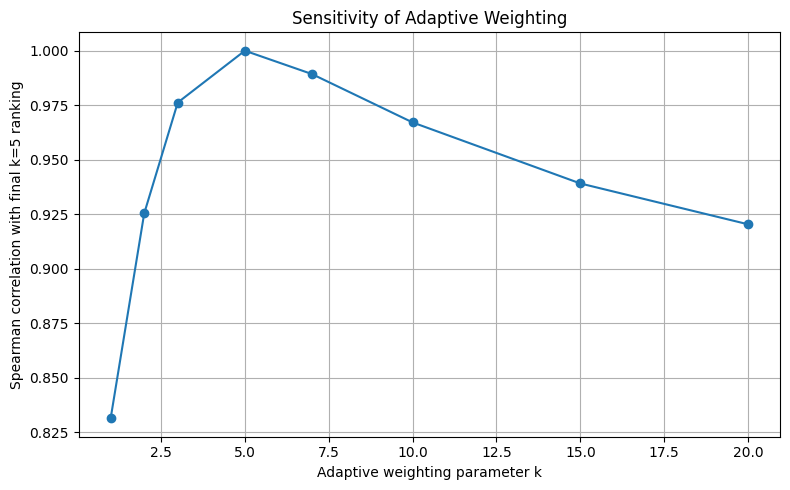

In [53]:
import matplotlib.pyplot as plt
plt.figure(figsize=(8, 5))
plt.plot(
    sensitivity_df["k"],
    sensitivity_df["spearman_vs_final_k5"],
    marker="o"
)
plt.xlabel("Adaptive weighting parameter k")
plt.ylabel("Spearman correlation with final k=5 ranking")
plt.title("Sensitivity of Adaptive Weighting")
plt.grid(True)
plt.tight_layout()
plt.show()


In [54]:
# ============================================================
# PHASE 9K — STATISTICAL SIGNIFICANCE OF RANKING DIFFERENCES
# ============================================================
#
# These tests compare paired per-video component scores/rankings.
# They are NOT presented as ground-truth effectiveness tests.
# They quantify whether component removals produce systematic
# score differences across the same per-video cohort.
# ============================================================

from scipy.stats import wilcoxon

significance_rows = []

for variant in ["no_engagement", "no_iqs", "fixed_weight_hybrid"]:
    stat, p = wilcoxon(
        hybrid_df["hybrid_score"],
        hybrid_df[variant],
        alternative="two-sided"
    )

    significance_rows.append({
        "comparison": f"Full Hybrid vs {variant}",
        "wilcoxon_statistic": stat,
        "p_value": p
    })

significance_df = pd.DataFrame(significance_rows)

significance_df.to_csv(
    "/content/revision_phase9h/paired_significance_tests.csv",
    index=False
)

print(significance_df.to_string(index=False))
print()
print("Saved: /content/revision_phase9h/paired_significance_tests.csv")


                        comparison  wilcoxon_statistic      p_value
      Full Hybrid vs no_engagement                20.0 1.540365e-17
             Full Hybrid vs no_iqs                20.0 1.540365e-17
Full Hybrid vs fixed_weight_hybrid                18.0 1.448855e-17

Saved: /content/revision_phase9h/paired_significance_tests.csv


# ============================================================
# EXTERNAL BENCHMARK EVALUATION — LAK 2026
# ============================================================
#
# Reviewer requirement addressed:
#   "Include standard ranking evaluation metrics..."
#   "Evaluate against ground truth..."
#
# We do NOT use FES/IQS/Hybrid as ground truth.
#
# Instead, this section targets the publicly described LAK 2026
# educational-resource ranking benchmark. The benchmark contains
# 53 YouTube topics, top-20 resources per topic, and independent
# expert labels (accepted/rejected) created by two domain experts
# per topic. The paper reports Precision@3 and Precision@5 and a
# pairwise ranking-accuracy measure.
#
# Source:
# Molavi Hajiagha et al., LAK 2026,
# DOI: 10.1145/3785022.3785073
#
# Benchmark database link reported by the authors:
# https://2ly.link/27QHn
#
# The code below downloads/extracts the benchmark at runtime in
# Colab and attempts to discover the SQLite schema automatically.
# ============================================================


In [58]:
# ============================================================
# LAK 2026 — INSPECT AUTHORS' DOWNLOAD / DATABASE REFERENCES
# ============================================================

from pathlib import Path
import re

REPO = Path("/content/lak2026_benchmark/lak2026_repo")

files_to_check = [
    REPO / "README.md",
    REPO / "db_ops.py",
    REPO / "cli.py",
    REPO / "const.py",
]

patterns = [
    "2ly.link",
    "sqlite",
    "db.sqlite3",
    "database",
    "download",
    "http",
    "https",
    "Internxt",
]

for path in files_to_check:
    print("\n" + "=" * 90)
    print("FILE:", path.name)
    print("=" * 90)

    if not path.exists():
        print("FILE NOT FOUND")
        continue

    text = path.read_text(errors="ignore")

    found = False

    for i, line in enumerate(text.splitlines(), 1):
        if any(p.lower() in line.lower() for p in patterns):
            print(f"{i:4d}: {line}")
            found = True

    if not found:
        print("No matching database/download references found.")


FILE: README.md
   5: This project uses `uv` to manage the Python environment and dependencies. You can install `uv` by following the [official installation guide](https://docs.astral.sh/uv/getting-started/installation/). Once `uv` is installed, you can synchronize the dependencies by running the following command in the project's root directory:
  13: ## Database Setup
  15: To proceed, you need to download the database from [this link](https://2ly.link/27QHn) and extract it to date folder.
  35: uv run cli.py metric precision-embedding  --at-n 5 -s db.sqlite3 -d artifacts_paper 
  36: uv run cli.py metric precision-baseline  --at-n 5 -s db.sqlite3 -d artifacts_paper 
  38: uv run cli.py metric precision-embedding  --at-n 3 -s db.sqlite3 -d artifacts_paper 
  39: uv run cli.py metric precision-baseline  --at-n 3 -s db.sqlite3 -d artifacts_paper 
  43: uv run cli.py metric acc-baseline --src-db db.sqlite3 -d artifacts_paper     
  44: uv run cli.py metric acc-embedding --src-db db.sql

In [63]:
import requests
import re

BUNDLE_URL = "https://share.ue.internxt.com/static/index-BgFDwQR4.js"

print("Downloading Internxt bundle...")

response = requests.get(BUNDLE_URL, timeout=60)
response.raise_for_status()

js = response.text

print("Bundle downloaded.")
print("Characters:", len(js))

Bundle downloaded.
Characters: 5673157


In [71]:
# Find exactly where `th` is defined and print its surrounding code

import re

for pattern in [
    r'\bth\s*=',
    r'\bth\s*=\s*we',
    r'\bth\s*=\s*.*baseUrl',
]:
    matches = list(re.finditer(pattern, js))

    print("\n" + "="*100)
    print(pattern, "→", len(matches), "matches")
    print("="*100)

    for m in matches[:10]:
        pos = m.start()
        print(f"\n--- position {pos} ---")
        print(js[max(0,pos-1500):min(len(js),pos+4000)])


\bth\s*= → 1 matches

--- position 1898780 ---
Y')+_0x362a52(0xf569,'$^H4')]?_0xb051ff[_0x1af2c7(0xc002,'R1S*')][_0x362a52(0x12d21,'R1S*')+_0x362a52(0x147d0,'26^x')][_0x1af2c7(0xe06c,'G9#$')+_0x362a52(0xaa13,'*]1S')]:0x0;return _0xb051ff[_0x1af2c7(0xc0a1,'SBnY')][_0x362a52(0xf0b1,'!7c(')+'t']||_0x4a72ee||ia[_0x362a52(0xd815,'d5w2')+_0x362a52(0xc7be,'mdKw')];},'planUsageToShow':_0x4670ee=>{const _0x5e5854=_0x20ccc1,_0x5ed24f=_0x20ccc1,{selectedWorkspace:_0x2fa40f}=_0x4670ee[_0x5e5854(0xd6f0,'OxNx')+'es'];return _0x2fa40f?_0x4670ee[_0x5e5854(0xdc47,'Yx[G')][_0x5e5854(0x7059,'%iTg')+_0x5ed24f(0x9dda,'y2bb')+'e']||0x0:_0x4670ee[_0x5ed24f(0x85da,'$^H4')][_0x5e5854(0x332a,'k9Wf')+'e'];},'isPlanActive':_0xfdc21=>_0x666417=>{const _0x52713b=_0x20ccc1,_0x48a57d=_0x20ccc1;var _0x3df316;return((_0x3df316=_0xfdc21[_0x52713b(0xc002,'R1S*')][_0x52713b(0x9906,'ckkD')+_0x48a57d(0x4454,'R)m[')])==null?void 0x0:_0x3df316[_0x48a57d(0xbdc8,'zCfo')])===_0x666417;},'subscriptionToShow':_0x5015cd=>{const _0

In [91]:
import subprocess
from pathlib import Path

# Use the exact functions already extracted
array_js = extract_js_function(js, "_0x3a93")
decoder_js = extract_js_function(js, "_0x52b1")

node_code = f"""
{array_js}

{decoder_js}

console.log("TEST 1:", _0x52b1(0x14504, "SBnY"));
console.log("TEST 2:", _0x52b1(0xc88, "[h@%"));
console.log("TEST 3:", _0x52b1(0x149e1, "MoF$"));
console.log("TEST 4:", _0x52b1(0x123c6, "[h@%"));
"""

Path("/content/test_decoder.js").write_text(node_code)

r = subprocess.run(
    ["node", "/content/test_decoder.js"],
    capture_output=True,
    text=True
)

print(r.stdout)
print(r.stderr)

TEST 1: §ÁÀ$(
TEST 2: 丮侄恈癁夓傸敷凵
TEST 3: â*ÜÈ
G³
TEST 4: ÞáEÅ




In [92]:
from google.colab import files

uploaded = files.upload()

Saving db.sqlite3.zip to db.sqlite3.zip


In [94]:
import zipfile
from pathlib import Path

zip_path = Path("/content/db.sqlite3.zip")
out_dir = Path("/content/lak2026_benchmark")
out_dir.mkdir(exist_ok=True)

with zipfile.ZipFile(zip_path, "r") as z:
    print("ZIP contents:")
    for name in z.namelist():
        print(" ", name)

    z.extractall(out_dir)

print("\nExtracted:")
for p in out_dir.rglob("*"):
    if p.is_file():
        print(p, f"({p.stat().st_size / (1024**2):.2f} MB)")

ZIP contents:
  db.sqlite3

Extracted:
/content/lak2026_benchmark/db.sqlite3 (356.48 MB)
/content/lak2026_benchmark/benchmark_download (0.07 MB)
/content/lak2026_benchmark/lak2026_repo/const.py (0.00 MB)
/content/lak2026_benchmark/lak2026_repo/README.md (0.00 MB)
/content/lak2026_benchmark/lak2026_repo/llm_ops.py (0.00 MB)
/content/lak2026_benchmark/lak2026_repo/db_ops.py (0.01 MB)
/content/lak2026_benchmark/lak2026_repo/cli.py (0.00 MB)
/content/lak2026_benchmark/lak2026_repo/metric_ops.py (0.00 MB)
/content/lak2026_benchmark/lak2026_repo/uv.lock (0.38 MB)
/content/lak2026_benchmark/lak2026_repo/paper_result.ipynb (0.01 MB)
/content/lak2026_benchmark/lak2026_repo/embeddings_ops.py (0.01 MB)
/content/lak2026_benchmark/lak2026_repo/pyproject.toml (0.00 MB)
/content/lak2026_benchmark/lak2026_repo/.idea/.gitignore (0.00 MB)
/content/lak2026_benchmark/lak2026_repo/.git/index (0.00 MB)
/content/lak2026_benchmark/lak2026_repo/.git/shallow (0.00 MB)
/content/lak2026_benchmark/lak2026_repo/.gi

In [95]:
import sqlite3
from pathlib import Path

db_files = list(Path("/content/lak2026_benchmark").rglob("*.sqlite3"))

print("SQLite files:", db_files)

if not db_files:
    raise RuntimeError("db.sqlite3 was not extracted")

db_path = db_files[0]

conn = sqlite3.connect(db_path)

tables = conn.execute("""
    SELECT name
    FROM sqlite_master
    WHERE type='table'
    ORDER BY name
""").fetchall()

print("\nDATABASE:", db_path)
print("TABLES:")
for table in tables:
    print(" ", table[0])

conn.close()

SQLite files: [PosixPath('/content/lak2026_benchmark/db.sqlite3')]

DATABASE: /content/lak2026_benchmark/db.sqlite3
TABLES:
  Courses
  EmbeddingVectors
  Prompt
  Resources
  SyntacticDataEmbeddingVector
  SyntaticData
  TopicResourceLink
  Topics
  sqlite_sequence


In [96]:
import sqlite3
from pathlib import Path

DB_PATH = "/content/lak2026_benchmark/db.sqlite3"

conn = sqlite3.connect(DB_PATH)

tables = [
    "Courses",
    "Resources",
    "Topics",
    "TopicResourceLink",
    "EmbeddingVectors",
    "Prompt",
    "SyntaticData",
    "SyntacticDataEmbeddingVector",
]

for table in tables:
    print("\n" + "=" * 80)
    print(f"TABLE: {table}")
    print("=" * 80)

    cols = conn.execute(f'PRAGMA table_info("{table}")').fetchall()

    for col in cols:
        cid, name, dtype, notnull, default_value, pk = col
        print(
            f"{cid:2} | {name:35} | "
            f"{dtype:15} | NOT NULL={notnull} | PK={pk}"
        )

    try:
        count = conn.execute(
            f'SELECT COUNT(*) FROM "{table}"'
        ).fetchone()[0]
        print(f"\nROW COUNT: {count:,}")
    except Exception as e:
        print("COUNT ERROR:", e)

conn.close()


TABLE: Courses
 0 | id                                  | INTEGER         | NOT NULL=0 | PK=1
 1 | title                               | TEXT            | NOT NULL=1 | PK=0

ROW COUNT: 8

TABLE: Resources
 0 | id                                  | INTEGER         | NOT NULL=0 | PK=1
 1 | url                                 | TEXT            | NOT NULL=0 | PK=0
 2 | content                             | TEXT            | NOT NULL=0 | PK=0
 3 | resource_order                      | INTEGER         | NOT NULL=1 | PK=0
 4 | download_content_log                | TEXT            | NOT NULL=0 | PK=0
 5 | n_tokens                            | INTEGER         | NOT NULL=0 | PK=0

ROW COUNT: 1,049

TABLE: Topics
 0 | id                                  | INTEGER         | NOT NULL=0 | PK=1
 1 | title                               | TEXT            | NOT NULL=1 | PK=0
 2 | course_id                           | INTEGER         | NOT NULL=1 | PK=0

ROW COUNT: 55

TABLE: TopicResourceLink
 0 | topi

In [97]:
import sqlite3
from collections import Counter

DB_PATH = "/content/lak2026_benchmark/db.sqlite3"

conn = sqlite3.connect(DB_PATH)

# ------------------------------------------------------------
# 1. All distinct TopicResourceLink.status values
# ------------------------------------------------------------
print("=" * 80)
print("DISTINCT STATUS VALUES")
print("=" * 80)

rows = conn.execute("""
    SELECT status, COUNT(*)
    FROM TopicResourceLink
    GROUP BY status
    ORDER BY COUNT(*) DESC
""").fetchall()

for status, count in rows:
    print(f"{repr(status):30} -> {count:,}")

# ------------------------------------------------------------
# 2. Sample joined records
# ------------------------------------------------------------
print("\n" + "=" * 80)
print("SAMPLE TOPIC -> RESOURCE -> STATUS")
print("=" * 80)

rows = conn.execute("""
    SELECT
        t.id AS topic_id,
        t.title AS topic,
        trl.resource_id,
        trl.status,
        r.url,
        r.resource_order,
        substr(r.content, 1, 200) AS content_preview
    FROM TopicResourceLink trl
    JOIN Topics t
        ON t.id = trl.topic_id
    JOIN Resources r
        ON r.id = trl.resource_id
    ORDER BY t.id, r.resource_order
    LIMIT 30
""").fetchall()

for row in rows:
    print("\n", row)

conn.close()

DISTINCT STATUS VALUES
'Rejected'                     -> 606
'Accepted'                     -> 386
'Language'                     -> 68
'Kept'                         -> 36
'Music'                        -> 2

SAMPLE TOPIC -> RESOURCE -> STATUS

 (1, 'What is a sprint?', 1, 'Rejected', 'https://www.youtube.com/watch?v=R7oXgtPOj74', 1, "welcome  to  another  video  of  the  agile \n shop  in  this  video  we'll  answer  what  is \n print  planning  and  scrum \n the  sprint  planning  meeting  kicks  off \n the  sprint  a  product  backl")

 (1, 'What is a sprint?', 2, 'Rejected', 'https://www.youtube.com/watch?v=-lofFJLdpsA', 2, "A sprint is a short period of time, usually\none or two weeks where each member of a team is focused on completing work that has been\nbroken into more manageable pieces. Let's take a look at why these ")

 (1, 'What is a sprint?', 3, 'Accepted', 'https://www.youtube.com/watch?v=7wGQU37fyiI', 3, "hi  my  name  is  Stephanie  I  am  a  software \n developer  ba

In [98]:
import sqlite3

conn = sqlite3.connect("/content/lak2026_benchmark/db.sqlite3")

rows = conn.execute("""
    SELECT
        t.id,
        t.title,
        c.title AS course
    FROM Topics t
    LEFT JOIN Courses c
        ON c.id = t.course_id
    ORDER BY t.id
""").fetchall()

print("=" * 80)
print(f"TOTAL TOPICS: {len(rows)}")
print("=" * 80)

for topic_id, title, course in rows:
    print(f"{topic_id:3} | {course:35} | {title}")

conn.close()

TOTAL TOPICS: 55
  1 | Agile Scrum                         | What is a sprint?
  2 | Agile Scrum                         | What is the difference between scrum and canban?
  3 | Agile Scrum                         | What is the role of product owner?
  4 | Agile Scrum                         | difference between agile and scrum?
  5 | Agile Scrum                         | what is the role of scrum master?
  6 | Learn LaTex                         | Graphics in latex: including images and creating diagrams
  7 | Learn LaTex                         | Latex document class
  8 | Learn LaTex                         | Latex for scientific writing: equations, formulas, and symbols
  9 | Learn LaTex                         | Lists in latex
 10 | Learn LaTex                         | Register account on Overleaf
 11 | Learn LaTex                         | Section, paragraph in latex
 12 | Learn LaTex                         | Tables in latex
 13 | Machine Learning                    | Cross Val

In [99]:
import sqlite3

DB_PATH = "/content/lak2026_benchmark/db.sqlite3"

conn = sqlite3.connect(DB_PATH)

print("=" * 90)
print("KEPT RESOURCES")
print("=" * 90)

rows = conn.execute("""
    SELECT
        t.id AS topic_id,
        t.title AS topic,
        trl.resource_id,
        trl.status,
        r.url,
        substr(r.content, 1, 300) AS content_preview
    FROM TopicResourceLink trl
    JOIN Topics t
        ON t.id = trl.topic_id
    JOIN Resources r
        ON r.id = trl.resource_id
    WHERE trl.status = 'Kept'
    ORDER BY t.id, r.resource_order
""").fetchall()

print("Total Kept:", len(rows))

for row in rows:
    print("\n", row)

conn.close()

KEPT RESOURCES
Total Kept: 36

 (6, 'Graphics in latex: including images and creating diagrams', 95, 'Kept', 'https://www.youtube.com/watch?v=10wGMzYgnqM', None)

 (6, 'Graphics in latex: including images and creating diagrams', 106, 'Kept', 'https://www.youtube.com/watch?v=bq547nr1qZA', None)

 (6, 'Graphics in latex: including images and creating diagrams', 110, 'Kept', 'https://www.youtube.com/watch?v=kK7meUSgZ9k', None)

 (7, 'Latex document class', 114, 'Kept', 'https://www.youtube.com/watch?v=1FrhgNP9BFE', None)

 (7, 'Latex document class', 129, 'Kept', 'https://www.youtube.com/watch?v=1MyFuvWwcfM', None)

 (8, 'Latex for scientific writing: equations, formulas, and symbols', 140, 'Kept', 'https://www.youtube.com/watch?v=AbD65gubMKQ', None)

 (8, 'Latex for scientific writing: equations, formulas, and symbols', 141, 'Kept', 'https://www.youtube.com/watch?v=I9PbWcmYPAI', None)

 (8, 'Latex for scientific writing: equations, formulas, and symbols', 145, 'Kept', 'https://www.youtub

In [100]:
from pathlib import Path

repo = Path("/content/lak2026_benchmark/lak2026_repo")

for fname in ["db_ops.py", "metric_ops.py", "cli.py", "README.md"]:
    path = repo / fname

    print("\n" + "=" * 100)
    print(fname)
    print("=" * 100)

    text = path.read_text(errors="ignore")

    # Show lines containing status-related terms
    for i, line in enumerate(text.splitlines(), 1):
        low = line.lower()
        if any(x in low for x in ["accepted", "rejected", "kept", "language", "music", "status"]):
            print(f"{i}: {line}")


db_ops.py
185:     SELECT r.id as res_id,r.url as res_url, ev.status as label, ev.value as embedding

metric_ops.py
8: def _split_status(data: pd.DataFrame) -> tuple[pd.DataFrame, pd.DataFrame]:
9:     return data.query("status == 'Accepted'"), data.query("status == 'Rejected'")
17:     accepted, rejected = _split_status(data)
18:     if accepted.empty or rejected.empty:
21:     accepted_orders = accepted["resource_order"].values
22:     rejected_orders = rejected["resource_order"].values
23:     comparisons = accepted_orders[:, None] < rejected_orders
31:     accepted, rejected = _split_status(data)
33:     if accepted.empty or rejected.empty:
36:     A = _load_embeddings(accepted["value"])
37:     R = _load_embeddings(rejected["value"])
46:         # Remove self from intra-accepted distances
47:         intra_accepted = np.delete(AA_dist[i], i)
48:         comparisons = intra_accepted[:, np.newaxis] < AR_dist[i]
60:     accepted, rejected = _split_status(data)
61:     num_accepted =

In [101]:
import sqlite3
import pandas as pd

DB_PATH = "/content/lak2026_benchmark/db.sqlite3"

conn = sqlite3.connect(DB_PATH)

benchmark_df = pd.read_sql_query("""
    SELECT
        t.id AS topic_id,
        c.title AS domain,
        t.title AS topic,
        r.id AS resource_id,
        r.url,
        r.resource_order,
        trl.status
    FROM TopicResourceLink trl
    JOIN Topics t
        ON t.id = trl.topic_id
    JOIN Courses c
        ON c.id = t.course_id
    JOIN Resources r
        ON r.id = trl.resource_id
    WHERE trl.status IN ('Accepted', 'Rejected')
    ORDER BY t.id, r.resource_order
""", conn)

conn.close()

benchmark_df["video_id"] = (
    benchmark_df["url"]
    .str.extract(r"[?&]v=([A-Za-z0-9_-]{11})", expand=False)
)

benchmark_df["relevance"] = (
    benchmark_df["status"] == "Accepted"
).astype(int)

print("Total benchmark records:", len(benchmark_df))
print("Unique videos:", benchmark_df["video_id"].nunique())
print("\nDomains:")
print(benchmark_df["domain"].value_counts())

print("\nStatus:")
print(benchmark_df["status"].value_counts())

print("\nMissing video IDs:", benchmark_df["video_id"].isna().sum())

benchmark_df.head(20)

Total benchmark records: 992
Unique videos: 943

Domains:
domain
Machine Learning                       214
Python Programming                     159
Time Management                        149
Prompt Engineering                     139
Learn LaTex                            119
Agile Scrum                            100
stress management and mental health     76
First Aid Training                      36
Name: count, dtype: int64

Status:
status
Rejected    606
Accepted    386
Name: count, dtype: int64

Missing video IDs: 0


,topic_id,domain,topic,resource_id,url,resource_order,status,video_id,relevance
0,1,Agile Scrum,What is a sprint?,1,https://www.youtube.com/watch?v=R7oXgtPOj74,1,Rejected,R7oXgtPOj74,0
1,1,Agile Scrum,What is a sprint?,2,https://www.youtube.com/watch?v=-lofFJLdpsA,2,Rejected,-lofFJLdpsA,0
2,1,Agile Scrum,What is a sprint?,3,https://www.youtube.com/watch?v=7wGQU37fyiI,3,Accepted,7wGQU37fyiI,1
3,1,Agile Scrum,What is a sprint?,4,https://www.youtube.com/watch?v=MyIZZOYDYxM,4,Rejected,MyIZZOYDYxM,0
4,1,Agile Scrum,What is a sprint?,5,https://www.youtube.com/watch?v=iJ_sl6J8PRg,5,Rejected,iJ_sl6J8PRg,0
5,1,Agile Scrum,What is a sprint?,6,https://www.youtube.com/watch?v=SWDhGSZNF9M,6,Rejected,SWDhGSZNF9M,0
6,1,Agile Scrum,What is a sprint?,7,https://www.youtube.com/watch?v=llKE01BAVyM,7,Accepted,llKE01BAVyM,1
7,1,Agile Scrum,What is a sprint?,8,https://www.youtube.com/watch?v=2qWKcfuueqo,8,Rejected,2qWKcfuueqo,0
8,1,Agile Scrum,What is a sprint?,9,https://www.youtube.com/watch?v=S0uk4rYuB_o,9,Rejected,S0uk4rYuB_o,0
9,1,Agile Scrum,What is a sprint?,10,https://www.youtube.com/watch?v=9TycLR0TqFA,10,Rejected,9TycLR0TqFA,0


In [102]:
import sqlite3
import pandas as pd

conn = sqlite3.connect("/content/lak2026_benchmark/db.sqlite3")

stats = pd.read_sql_query("""
SELECT
    COUNT(*) AS total_resources,
    SUM(CASE WHEN content IS NOT NULL AND TRIM(content) != '' THEN 1 ELSE 0 END)
        AS resources_with_content,
    SUM(CASE WHEN content IS NULL OR TRIM(content) = '' THEN 1 ELSE 0 END)
        AS resources_without_content,
    AVG(n_tokens) AS avg_tokens,
    MAX(n_tokens) AS max_tokens
FROM Resources
""", conn)

print(stats)

print("\nContent availability by benchmark status:")

status_stats = pd.read_sql_query("""
SELECT
    trl.status,
    COUNT(*) AS total,
    SUM(CASE WHEN r.content IS NOT NULL AND TRIM(r.content) != '' THEN 1 ELSE 0 END)
        AS with_content,
    SUM(CASE WHEN r.content IS NULL OR TRIM(r.content) = '' THEN 1 ELSE 0 END)
        AS without_content
FROM TopicResourceLink trl
JOIN Resources r ON r.id = trl.resource_id
WHERE trl.status IN ('Accepted', 'Rejected')
GROUP BY trl.status
""", conn)

print(status_stats)

conn.close()

   total_resources  resources_with_content  resources_without_content  \
0             1049                     883                        166   

    avg_tokens  max_tokens  
0  4284.984163      378069  

Content availability by benchmark status:
     status  total  with_content  without_content
0  Accepted    386           366               20
1  Rejected    606           565               41


In [103]:
import sqlite3
import pandas as pd

DB_PATH = "/content/lak2026_benchmark/db.sqlite3"

conn = sqlite3.connect(DB_PATH)

df = pd.read_sql_query("""
    SELECT
        t.id AS topic_id,
        c.title AS domain,
        t.title AS topic,
        r.id AS resource_id,
        r.url,
        r.content,
        r.resource_order,
        trl.status
    FROM TopicResourceLink trl
    JOIN Topics t
        ON t.id = trl.topic_id
    JOIN Courses c
        ON c.id = t.course_id
    JOIN Resources r
        ON r.id = trl.resource_id
    WHERE trl.status IN ('Accepted', 'Rejected')
""", conn)

conn.close()

df["has_content"] = (
    df["content"].notna() &
    df["content"].str.strip().ne("")
)

eval_df = df[df["has_content"]].copy()

print("=" * 100)
print("LAK BENCHMARK EVALUATION DIAGNOSTIC")
print("=" * 100)

print(f"All labeled pairs       : {len(df)}")
print(f"Pairs with content      : {len(eval_df)}")
print(f"Pairs without content   : {len(df) - len(eval_df)}")
print(f"Unique videos           : {eval_df['url'].nunique()}")
print(f"Unique topics           : {eval_df['topic_id'].nunique()}")

print("\n" + "=" * 100)
print("TOPIC-LEVEL COVERAGE")
print("=" * 100)

topic_stats = (
    eval_df
    .groupby(["topic_id", "domain", "topic"])
    .agg(
        total=("resource_id", "count"),
        accepted=("status", lambda x: (x == "Accepted").sum()),
        rejected=("status", lambda x: (x == "Rejected").sum()),
    )
    .reset_index()
)

topic_stats["has_positive"] = topic_stats["accepted"] > 0
topic_stats["has_negative"] = topic_stats["rejected"] > 0
topic_stats["usable"] = (
    topic_stats["has_positive"] &
    topic_stats["has_negative"]
)

print("\nUsable topics:", topic_stats["usable"].sum())
print("Topics without Accepted:", (~topic_stats["has_positive"]).sum())
print("Topics without Rejected:", (~topic_stats["has_negative"]).sum())

print("\nCoverage by domain:")
print(
    topic_stats
    .groupby("domain")
    .agg(
        topics=("topic_id", "count"),
        usable_topics=("usable", "sum"),
        resources=("total", "sum"),
        accepted=("accepted", "sum"),
        rejected=("rejected", "sum"),
    )
    .to_string()
)

print("\nTopics NOT usable:")
print(
    topic_stats.loc[
        ~topic_stats["usable"],
        ["topic_id", "domain", "topic", "total", "accepted", "rejected"]
    ].to_string(index=False)
)

LAK BENCHMARK EVALUATION DIAGNOSTIC
All labeled pairs       : 992
Pairs with content      : 931
Pairs without content   : 61
Unique videos           : 883
Unique topics           : 55

TOPIC-LEVEL COVERAGE

Usable topics: 54
Topics without Accepted: 0
Topics without Rejected: 1

Coverage by domain:
                                     topics  usable_topics  resources  accepted  rejected
domain                                                                                   
Agile Scrum                               5              5         92        15        77
First Aid Training                        2              2         32        16        16
Learn LaTex                               7              7        109        57        52
Machine Learning                         12             12        202        58       144
Prompt Engineering                        7              7        135        50        85
Python Programming                       10             10        149 

In [104]:
# Check whether the existing 100-video Phase 9C cohort
# overlaps with the LAK benchmark.

import pandas as pd
from pathlib import Path

phase9c_path = Path(
    "/content/revision_phase9c/all_domains_video_emotional_engagement.csv"
)

if not phase9c_path.exists():
    print("Phase 9C file not found:", phase9c_path)
else:
    phase9c = pd.read_csv(phase9c_path)

    print("Phase 9C rows:", len(phase9c))
    print("Phase 9C columns:")
    print(phase9c.columns.tolist())

    # Detect video-id column
    candidates = [
        c for c in phase9c.columns
        if c.lower() in ["video_id", "videoid", "youtube_id"]
    ]

    print("Video ID candidates:", candidates)

    if candidates:
        phase9_ids = set(
            phase9c[candidates[0]]
            .dropna()
            .astype(str)
        )

        benchmark_ids = set(
            eval_df["url"]
            .str.extract(
                r"[?&]v=([A-Za-z0-9_-]{11})",
                expand=False
            )
            .dropna()
            .astype(str)
        )

        overlap = phase9_ids & benchmark_ids

        print("\nPhase 9 unique IDs:", len(phase9_ids))
        print("Benchmark unique IDs:", len(benchmark_ids))
        print("Overlap:", len(overlap))
        print("Overlap percentage of benchmark:",
              round(100 * len(overlap) / len(benchmark_ids), 2), "%")

Phase 9C rows: 98
Phase 9C columns:
['video_id', 'emotional_engagement', 'emotional_variance', 'relevant_comment_count', 'query', 'domain']
Video ID candidates: ['video_id']

Phase 9 unique IDs: 98
Benchmark unique IDs: 883
Overlap: 5
Overlap percentage of benchmark: 0.57 %


In [105]:
from pathlib import Path
import sqlite3
import pandas as pd
import re

BASE = Path("/content/revision_phase10")
BASE.mkdir(parents=True, exist_ok=True)

DB_PATH = "/content/lak2026_benchmark/db.sqlite3"

conn = sqlite3.connect(DB_PATH)

benchmark = pd.read_sql_query("""
    SELECT
        t.id AS topic_id,
        c.title AS domain,
        t.title AS topic,
        r.id AS resource_id,
        r.url,
        r.content,
        r.resource_order,
        trl.status
    FROM TopicResourceLink trl
    JOIN Topics t ON t.id = trl.topic_id
    JOIN Courses c ON c.id = t.course_id
    JOIN Resources r ON r.id = trl.resource_id
    WHERE trl.status IN ('Accepted', 'Rejected')
""", conn)

conn.close()

# YouTube ID
benchmark["video_id"] = benchmark["url"].str.extract(
    r"[?&]v=([A-Za-z0-9_-]{11})",
    expand=False
)

# Only resources with usable content
benchmark["has_content"] = (
    benchmark["content"].notna() &
    benchmark["content"].str.strip().ne("")
)

benchmark_eval = benchmark[benchmark["has_content"]].copy()

# Relevance
benchmark_eval["relevance"] = (
    benchmark_eval["status"] == "Accepted"
).astype(int)

# Remove topics without both classes
topic_counts = benchmark_eval.groupby("topic_id")["relevance"].agg(
    positives="sum",
    total="count"
)

topic_counts["negatives"] = topic_counts["total"] - topic_counts["positives"]

usable_topics = topic_counts[
    (topic_counts["positives"] > 0) &
    (topic_counts["negatives"] > 0)
].index

benchmark_eval = benchmark_eval[
    benchmark_eval["topic_id"].isin(usable_topics)
].copy()

output = BASE / "lak2026_benchmark_eval.csv"
benchmark_eval.to_csv(output, index=False)

print("Saved:", output)
print("Topics:", benchmark_eval["topic_id"].nunique())
print("Pairs:", len(benchmark_eval))
print("Videos:", benchmark_eval["video_id"].nunique())
print("\nDomains:")
print(benchmark_eval["domain"].value_counts())

Saved: /content/revision_phase10/lak2026_benchmark_eval.csv
Topics: 54
Pairs: 914
Videos: 866

Domains:
domain
Machine Learning                       202
Python Programming                     149
Prompt Engineering                     135
Time Management                        125
Learn LaTex                            109
Agile Scrum                             92
stress management and mental health     70
First Aid Training                      32
Name: count, dtype: int64


## Benchmark adapter note

The LAK 2026 paper explicitly defines its ground truth as topic-specific
accepted/rejected labels produced by two domain experts per topic. It
uses the top 20 English YouTube results per topic and evaluates ranking
against those labels. citeturn1search0turn1search2

The adapter below intentionally refuses to guess a schema. It maps only
columns that are unambiguously identifiable. If the public database schema
changes, the notebook stops rather than silently producing invalid metrics.


In [109]:
from sklearn.metrics import ndcg_score
from scipy.stats import spearmanr
# ============================================================
# PHASE 10B — BM25 + E5 EXTERNAL BENCHMARK BASELINES
# ============================================================

import os
import re
import numpy as np
import pandas as pd
from pathlib import Path
from tqdm.auto import tqdm

# Install if necessary:
# !pip -q install rank-bm25

from rank_bm25 import BM25Okapi
from sentence_transformers import SentenceTransformer


# ============================================================
# PATHS
# ============================================================

BASE = Path("/content/revision_phase10")
INPUT = BASE / "lak2026_benchmark_eval.csv"

if not INPUT.exists():
    raise FileNotFoundError(
        f"Benchmark file not found: {INPUT}"
    )

benchmark = pd.read_csv(INPUT)

print("=" * 90)
print("PHASE 10B — BM25 + E5 EXTERNAL BENCHMARK")
print("=" * 90)

print("Loaded pairs:", len(benchmark))
print("Topics:", benchmark["topic_id"].nunique())
print("Unique videos:", benchmark["video_id"].nunique())


# ============================================================
# VALIDATE REQUIRED COLUMNS
# ============================================================

required_columns = [
    "topic_id",
    "domain",
    "topic",
    "video_id",
    "content",
    "relevance",
]

missing = [
    c for c in required_columns
    if c not in benchmark.columns
]

if missing:
    raise RuntimeError(
        f"Missing required benchmark columns: {missing}"
    )


# ============================================================
# CLEAN TEXT
# ============================================================

def clean_text(text):
    if pd.isna(text):
        return ""

    text = str(text)
    text = re.sub(r"\s+", " ", text)
    return text.strip()


benchmark["content_clean"] = (
    benchmark["content"]
    .apply(clean_text)
)


# ============================================================
# REMOVE EMPTY DOCUMENTS
# ============================================================

before = len(benchmark)

benchmark = benchmark[
    benchmark["content_clean"].str.len() > 0
].copy()

after = len(benchmark)

print("\nContent filtering:")
print("Before:", before)
print("After :", after)
print("Removed:", before - after)


# ============================================================
# CHECK TOPIC LABEL VALIDITY
# ============================================================

topic_check = (
    benchmark
    .groupby("topic_id")
    .agg(
        positives=("relevance", "sum"),
        total=("relevance", "count")
    )
)

topic_check["negatives"] = (
    topic_check["total"] -
    topic_check["positives"]
)

invalid_topics = topic_check[
    (topic_check["positives"] == 0) |
    (topic_check["negatives"] == 0)
]

if len(invalid_topics) > 0:
    print(
        "\nWARNING — topics without both positive and negative labels:"
    )
    print(invalid_topics)

    benchmark = benchmark[
        ~benchmark["topic_id"].isin(
            invalid_topics.index
        )
    ].copy()


print("\nFinal evaluation topics:", benchmark["topic_id"].nunique())
print("Final evaluation pairs:", len(benchmark))
print("Final unique videos:", benchmark["video_id"].nunique())


# ============================================================
# METRIC FUNCTIONS
# ============================================================

def dcg(relevances, k):
    relevances = np.asarray(
        relevances[:k],
        dtype=float
    )

    if len(relevances) == 0:
        return 0.0

    discounts = np.log2(
        np.arange(2, len(relevances) + 2)
    )

    return np.sum(
        (2 ** relevances - 1) / discounts
    )


def ndcg_at_k(y_true, ranking, k):

    ranked_relevance = [
        y_true.get(video_id, 0)
        for video_id in ranking[:k]
    ]

    ideal_relevance = sorted(
        y_true.values(),
        reverse=True
    )[:k]

    ideal_dcg = dcg(
        ideal_relevance,
        k
    )

    if ideal_dcg == 0:
        return np.nan

    return (
        dcg(ranked_relevance, k)
        / ideal_dcg
    )


def precision_at_k(y_true, ranking, k):

    ranking = ranking[:k]

    if not ranking:
        return np.nan

    hits = sum(
        y_true.get(video_id, 0)
        for video_id in ranking
    )

    return hits / len(ranking)


def recall_at_k(y_true, ranking, k):

    ranking = ranking[:k]

    total_relevant = sum(
        y_true.values()
    )

    if total_relevant == 0:
        return np.nan

    hits = sum(
        y_true.get(video_id, 0)
        for video_id in ranking
    )

    return hits / total_relevant


def average_precision_at_k(
    y_true,
    ranking,
    k
):

    total_relevant = sum(
        y_true.values()
    )

    if total_relevant == 0:
        return np.nan

    hits = 0
    precision_sum = 0.0

    for rank, video_id in enumerate(
        ranking[:k],
        start=1
    ):

        if y_true.get(video_id, 0) == 1:

            hits += 1

            precision_sum += (
                hits / rank
            )

    return (
        precision_sum /
        min(total_relevant, k)
    )


def reciprocal_rank(
    y_true,
    ranking
):

    for rank, video_id in enumerate(
        ranking,
        start=1
    ):

        if y_true.get(video_id, 0) == 1:
            return 1.0 / rank

    return 0.0


# ============================================================
# LOAD E5
# ============================================================

print("\nLoading E5 model...")

e5_model = SentenceTransformer(
    "intfloat/e5-base-v2"
)

print("E5 model loaded.")


# ============================================================
# TOPIC-BY-TOPIC EVALUATION
# ============================================================

results = []

for topic_id, group in tqdm(
    benchmark.groupby("topic_id"),
    desc="Evaluating LAK topics"
):

    group = group.copy()

    topic = str(
        group["topic"].iloc[0]
    )

    domain = str(
        group["domain"].iloc[0]
    )

    video_ids = (
        group["video_id"]
        .astype(str)
        .tolist()
    )

    documents = (
        group["content_clean"]
        .tolist()
    )

    relevance = (
        group["relevance"]
        .astype(int)
        .tolist()
    )

    y_true = dict(
        zip(
            video_ids,
            relevance
        )
    )


    # ========================================================
    # BM25
    # ========================================================

    tokenized_documents = [
        document.lower().split()
        for document in documents
    ]

    bm25 = BM25Okapi(
        tokenized_documents
    )

    query_tokens = (
        topic.lower().split()
    )

    bm25_scores = bm25.get_scores(
        query_tokens
    )

    bm25_order = np.argsort(
        bm25_scores
    )[::-1]

    bm25_ranking = [
        video_ids[i]
        for i in bm25_order
    ]


    # ========================================================
    # E5
    # ========================================================

    query_embedding = e5_model.encode(
        ["query: " + topic],
        normalize_embeddings=True,
        show_progress_bar=False
    )[0]

    document_embeddings = (
        e5_model.encode(
            [
                "passage: " + document
                for document in documents
            ],
            normalize_embeddings=True,
            show_progress_bar=False
        )
    )

    e5_scores = np.dot(
        document_embeddings,
        query_embedding
    )

    e5_order = np.argsort(
        e5_scores
    )[::-1]

    e5_ranking = [
        video_ids[i]
        for i in e5_order
    ]


    # ========================================================
    # STORE METRICS
    # ========================================================

    for method, ranking in [
        ("BM25", bm25_ranking),
        ("E5", e5_ranking)
    ]:

        results.append({

            "topic_id": topic_id,
            "domain": domain,
            "topic": topic,
            "method": method,

            "n_candidates": len(group),

            "n_relevant": sum(relevance),

            "NDCG@5":
                ndcg_at_k(
                    y_true,
                    ranking,
                    5
                ),

            "NDCG@10":
                ndcg_at_k(
                    y_true,
                    ranking,
                    10
                ),

            "MAP@10":
                average_precision_at_k(
                    y_true,
                    ranking,
                    10
                ),

            "MRR":
                reciprocal_rank(
                    y_true,
                    ranking
                ),

            "Precision@5":
                precision_at_k(
                    y_true,
                    ranking,
                    5
                ),

            "Precision@10":
                precision_at_k(
                    y_true,
                    ranking,
                    10
                ),

            "Recall@5":
                recall_at_k(
                    y_true,
                    ranking,
                    5
                ),

            "Recall@10":
                recall_at_k(
                    y_true,
                    ranking,
                    10
                )
        })


# ============================================================
# SAVE TOPIC-LEVEL RESULTS
# ============================================================

results_df = pd.DataFrame(
    results
)

topic_results_path = (
    BASE /
    "phase10b_baseline_topic_results.csv"
)

results_df.to_csv(
    topic_results_path,
    index=False
)


# ============================================================
# MACRO-AVERAGED SUMMARY
# ============================================================

metric_columns = [
    "NDCG@5",
    "NDCG@10",
    "MAP@10",
    "MRR",
    "Precision@5",
    "Precision@10",
    "Recall@5",
    "Recall@10"
]

summary = (
    results_df
    .groupby("method")[metric_columns]
    .mean()
    .reset_index()
)

summary_path = (
    BASE /
    "phase10b_baseline_summary.csv"
)

summary.to_csv(
    summary_path,
    index=False
)


# ============================================================
# FINAL OUTPUT
# ============================================================

print("\n" + "=" * 90)
print("PHASE 10B COMPLETE")
print("=" * 90)

print(
    "\nTopic-level results:"
)
print(topic_results_path)

print(
    "\nSummary:"
)
print(summary_path)

print(
    "\nMACRO-AVERAGED RESULTS:"
)

display(
    summary.round(4)
)

PHASE 10B — BM25 + E5 EXTERNAL BENCHMARK
Loaded pairs: 914
Topics: 54
Unique videos: 866

Content filtering:
Before: 914
After : 914
Removed: 0

Final evaluation topics: 54
Final evaluation pairs: 914
Final unique videos: 866

Loading E5 model...


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

E5 model loaded.


Evaluating LAK topics:   0%|          | 0/54 [00:00<?, ?it/s]


PHASE 10B COMPLETE

Topic-level results:
/content/revision_phase10/phase10b_baseline_topic_results.csv

Summary:
/content/revision_phase10/phase10b_baseline_summary.csv

MACRO-AVERAGED RESULTS:


,method,NDCG@5,NDCG@10,MAP@10,MRR,Precision@5,Precision@10,Recall@5,Recall@10
0,BM25,0.4644,0.5788,0.4167,0.6634,0.4333,0.4438,0.3258,0.6875
1,E5,0.5756,0.6558,0.5018,0.7328,0.5296,0.4642,0.4129,0.7404


# PHASE 10C — EXTERNAL BENCHMARK RANKING METRICS

The metrics are computed **per benchmark topic** and then macro-averaged,
which avoids allowing topics with more resources to dominate the result.

For this external benchmark:

- Relevance = expert accepted/rejected label.
- NDCG@K uses the binary relevance labels.
- Precision@K and Recall@K use the same independent labels.
- MRR@K and MAP@K are calculated per topic.
- Results are reported with the number of evaluated topics.

This is the part of the revision that supplies an independent reference
for ranking evaluation; it must not be confused with the 99-video
five-domain case study. citeturn1search0turn1search2


In [110]:
# ============================================================================
# PHASE 10C — PROPOSED METHOD COMPONENT ON LAK 2026 EXTERNAL BENCHMARK
# ============================================================================
# Purpose:
# Evaluate the content-based component of the proposed ranking framework
# against the same human-validated LAK 2026 benchmark used in Phase 10B.
#
# IMPORTANT:
# - No fabricated Teaching Scores
# - No fabricated engagement data
# - No FES reconstruction
# - Uses only information actually available in the LAK benchmark
#
# Components evaluated:
#   1. E5 Semantic Alignment
#   2. Content Depth proxy
#   3. Lexical Diversity (TTR)
#   4. Content-based Intrinsic Quality Score
#
# Metrics:
#   NDCG@5, NDCG@10, MAP@10, MRR,
#   Precision@5, Precision@10, Recall@5, Recall@10
# ============================================================================

import os
import re
import numpy as np
import pandas as pd
from tqdm.auto import tqdm
from sentence_transformers import SentenceTransformer
from sklearn.metrics import ndcg_score
from scipy.stats import spearmanr

print("=" * 90)
print("PHASE 10C — PROPOSED CONTENT-BASED METHOD")
print("=" * 90)

# ----------------------------------------------------------------------------
# 1. LOAD CLEAN LAK BENCHMARK
# ----------------------------------------------------------------------------

BENCHMARK_PATH = "/content/revision_phase10/lak2026_benchmark_eval.csv"

df = pd.read_csv(BENCHMARK_PATH)

required_cols = [
    "topic_id",
    "domain",
    "topic",
    "video_id",
    "content",
    "relevance"
]

missing = [c for c in required_cols if c not in df.columns]

if missing:
    raise ValueError(f"Missing required columns: {missing}")

print(f"Loaded pairs : {len(df)}")
print(f"Topics       : {df['topic_id'].nunique()}")
print(f"Videos       : {df['video_id'].nunique()}")

# ----------------------------------------------------------------------------
# 2. CLEAN CONTENT
# ----------------------------------------------------------------------------

df["content_clean"] = (
    df["content"]
    .fillna("")
    .astype(str)
    .str.replace(r"\s+", " ", regex=True)
    .str.strip()
)

before = len(df)

df = df[df["content_clean"].str.len() > 0].copy()

print("\nContent filtering:")
print(f"Before: {before}")
print(f"After : {len(df)}")
print(f"Removed: {before - len(df)}")

# ----------------------------------------------------------------------------
# 3. VALIDATE TOPICS
# ----------------------------------------------------------------------------

topic_stats = (
    df.groupby("topic_id")
      .agg(
          topic=("topic", "first"),
          n_pairs=("video_id", "count"),
          positives=("relevance", "sum"),
          negatives=("relevance", lambda x: (x == 0).sum())
      )
      .reset_index()
)

valid_topics = topic_stats[
    (topic_stats["positives"] > 0) &
    (topic_stats["negatives"] > 0)
]["topic_id"].tolist()

df = df[df["topic_id"].isin(valid_topics)].copy()

print(f"\nFinal evaluation topics: {len(valid_topics)}")
print(f"Final evaluation pairs : {len(df)}")
print(f"Final unique videos     : {df['video_id'].nunique()}")

# ----------------------------------------------------------------------------
# 4. LOAD E5
# ----------------------------------------------------------------------------

print("\nLoading E5 model...")

model = SentenceTransformer("intfloat/e5-base-v2")

print("E5 model loaded.")

# ----------------------------------------------------------------------------
# 5. HELPER FUNCTIONS
# ----------------------------------------------------------------------------

def clean_words(text):
    return re.findall(r"\b[a-zA-Z0-9]+\b", str(text).lower())


def lexical_diversity(text):
    """
    Type-Token Ratio (TTR):
        unique tokens / total tokens
    """
    words = clean_words(text)

    if not words:
        return 0.0

    return len(set(words)) / len(words)


def minmax(values):
    values = np.asarray(values, dtype=float)

    vmin = values.min()
    vmax = values.max()

    if vmax == vmin:
        return np.zeros_like(values)

    return (values - vmin) / (vmax - vmin)


def average_precision_at_k(y_true, k=10):
    y_true = np.asarray(y_true)[:k]

    total_relevant = np.sum(y_true)

    if total_relevant == 0:
        return 0.0

    score = 0.0
    hits = 0

    for i, rel in enumerate(y_true, start=1):

        if rel == 1:
            hits += 1
            score += hits / i

    return score / min(total_relevant, k)


def reciprocal_rank(y_true):
    for i, rel in enumerate(y_true, start=1):
        if rel == 1:
            return 1.0 / i

    return 0.0


def precision_at_k(y_true, k):
    y_true = np.asarray(y_true)[:k]

    if len(y_true) == 0:
        return 0.0

    return np.mean(y_true)


def recall_at_k(y_true, k):
    y_true = np.asarray(y_true)

    total_relevant = np.sum(y_true)

    if total_relevant == 0:
        return 0.0

    return np.sum(y_true[:k]) / total_relevant


def ndcg_at_k(y_true, k):
    y_true = np.asarray(y_true)

    if np.sum(y_true) == 0:
        return 0.0

    return ndcg_score(
        [y_true],
        [np.arange(len(y_true), 0, -1)],
        k=k
    )


# ----------------------------------------------------------------------------
# 6. EVALUATE TOPIC BY TOPIC
# ----------------------------------------------------------------------------

results = []
ranking_records = []

for topic_id, group in tqdm(
    df.groupby("topic_id"),
    desc="Evaluating LAK topics"
):

    group = group.copy()

    topic = group["topic"].iloc[0]
    domain = group["domain"].iloc[0]

    contents = group["content_clean"].tolist()

    # ------------------------------------------------------------------------
    # E5 semantic alignment
    # ------------------------------------------------------------------------

    query_embedding = model.encode(
        ["query: " + topic],
        normalize_embeddings=True,
        show_progress_bar=False
    )[0]

    document_embeddings = model.encode(
        ["passage: " + x for x in contents],
        normalize_embeddings=True,
        show_progress_bar=False,
        batch_size=32
    )

    semantic_scores = np.dot(
        document_embeddings,
        query_embedding
    )

    group["semantic_alignment"] = semantic_scores

    # ------------------------------------------------------------------------
    # Content depth
    #
    # We deliberately call this a STRUCTURAL PROXY.
    # Longer text does NOT imply higher educational quality.
    # ------------------------------------------------------------------------

    group["content_length"] = group["content_clean"].str.len()

    group["depth_proxy"] = minmax(
        group["content_length"].values
    )

    # ------------------------------------------------------------------------
    # Lexical diversity
    # ------------------------------------------------------------------------

    group["lexical_diversity"] = group[
        "content_clean"
    ].apply(lexical_diversity)

    # Normalize semantic alignment within topic
    group["semantic_alignment_norm"] = minmax(
        group["semantic_alignment"].values
    )

    # Normalize lexical diversity within topic
    group["lexical_diversity_norm"] = minmax(
        group["lexical_diversity"].values
    )

    # ------------------------------------------------------------------------
    # CONTENT-BASED INTRINSIC QUALITY SCORE
    #
    # Original manuscript structure:
    #
    # 0.30 Semantic Alignment
    # 0.20 Depth
    # 0.20 Lexical Diversity
    # 0.30 Teaching Score
    #
    # Teaching Score is unavailable in LAK benchmark.
    #
    # Therefore we DO NOT invent it.
    #
    # Instead, the available components are renormalized:
    #
    # Semantic = 0.30 / 0.70
    # Depth    = 0.20 / 0.70
    # Lexical  = 0.20 / 0.70
    # ------------------------------------------------------------------------

    group["intrinsic_quality_score"] = (
        (0.30 / 0.70) * group["semantic_alignment_norm"] +
        (0.20 / 0.70) * group["depth_proxy"] +
        (0.20 / 0.70) * group["lexical_diversity_norm"]
    )

    # ------------------------------------------------------------------------
    # Ranking
    # ------------------------------------------------------------------------

    group = group.sort_values(
        "intrinsic_quality_score",
        ascending=False
    ).reset_index(drop=True)

    y_true = group["relevance"].astype(int).values

    # ------------------------------------------------------------------------
    # Metrics
    # ------------------------------------------------------------------------

    ndcg5 = ndcg_at_k(y_true, 5)
    ndcg10 = ndcg_at_k(y_true, 10)

    map10 = average_precision_at_k(y_true, 10)

    mrr = reciprocal_rank(y_true)

    p5 = precision_at_k(y_true, 5)
    p10 = precision_at_k(y_true, 10)

    r5 = recall_at_k(y_true, 5)
    r10 = recall_at_k(y_true, 10)

    results.append({
        "topic_id": topic_id,
        "domain": domain,
        "topic": topic,
        "n_pairs": len(group),
        "n_relevant": int(np.sum(y_true)),
        "NDCG@5": ndcg5,
        "NDCG@10": ndcg10,
        "MAP@10": map10,
        "MRR": mrr,
        "Precision@5": p5,
        "Precision@10": p10,
        "Recall@5": r5,
        "Recall@10": r10
    })

    # Save ranking information for later error analysis
    for rank, (_, row) in enumerate(group.iterrows(), start=1):

        ranking_records.append({
            "topic_id": topic_id,
            "domain": domain,
            "topic": topic,
            "rank": rank,
            "video_id": row["video_id"],
            "relevance": int(row["relevance"]),
            "semantic_alignment": row["semantic_alignment"],
            "depth_proxy": row["depth_proxy"],
            "lexical_diversity": row["lexical_diversity"],
            "intrinsic_quality_score": row["intrinsic_quality_score"]
        })


# ----------------------------------------------------------------------------
# 7. RESULTS
# ----------------------------------------------------------------------------

results_df = pd.DataFrame(results)

ranking_df = pd.DataFrame(ranking_records)

# ----------------------------------------------------------------------------
# 8. SAVE OUTPUTS
# ----------------------------------------------------------------------------

OUTPUT_DIR = "/content/revision_phase10"

os.makedirs(OUTPUT_DIR, exist_ok=True)

topic_output = os.path.join(
    OUTPUT_DIR,
    "phase10c_proposed_content_topic_results.csv"
)

ranking_output = os.path.join(
    OUTPUT_DIR,
    "phase10c_proposed_content_rankings.csv"
)

summary_output = os.path.join(
    OUTPUT_DIR,
    "phase10c_proposed_content_summary.csv"
)

results_df.to_csv(topic_output, index=False)

ranking_df.to_csv(ranking_output, index=False)

macro_summary = pd.DataFrame([{
    "method": "Proposed_Content_IQS",
    "NDCG@5": results_df["NDCG@5"].mean(),
    "NDCG@10": results_df["NDCG@10"].mean(),
    "MAP@10": results_df["MAP@10"].mean(),
    "MRR": results_df["MRR"].mean(),
    "Precision@5": results_df["Precision@5"].mean(),
    "Precision@10": results_df["Precision@10"].mean(),
    "Recall@5": results_df["Recall@5"].mean(),
    "Recall@10": results_df["Recall@10"].mean()
}])

macro_summary.to_csv(summary_output, index=False)

# ----------------------------------------------------------------------------
# 9. DISPLAY
# ----------------------------------------------------------------------------

print("\n" + "=" * 90)
print("PHASE 10C COMPLETE")
print("=" * 90)

print(f"\nTopic-level results:")
print(topic_output)

print(f"\nRanking results:")
print(ranking_output)

print(f"\nSummary:")
print(summary_output)

print("\nMACRO-AVERAGED RESULTS:")

display(
    macro_summary.round(4)
)

print("\nComponent statistics:")

display(
    results_df[
        [
            "NDCG@5",
            "NDCG@10",
            "MAP@10",
            "MRR",
            "Precision@5",
            "Precision@10",
            "Recall@5",
            "Recall@10"
        ]
    ].describe().round(4)
)

print("\n" + "=" * 90)
print("IMPORTANT:")
print("This benchmark evaluation excludes FES and LLM Teaching Score")
print("because those signals are not available in the LAK benchmark.")
print("No ground-truth labels or engagement values were fabricated.")
print("=" * 90)

PHASE 10C — PROPOSED CONTENT-BASED METHOD
Loaded pairs : 914
Topics       : 54
Videos       : 866

Content filtering:
Before: 914
After : 914
Removed: 0

Final evaluation topics: 54
Final evaluation pairs : 914
Final unique videos     : 866

Loading E5 model...


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

E5 model loaded.


Evaluating LAK topics:   0%|          | 0/54 [00:00<?, ?it/s]


PHASE 10C COMPLETE

Topic-level results:
/content/revision_phase10/phase10c_proposed_content_topic_results.csv

Ranking results:
/content/revision_phase10/phase10c_proposed_content_rankings.csv

Summary:
/content/revision_phase10/phase10c_proposed_content_summary.csv

MACRO-AVERAGED RESULTS:


,method,NDCG@5,NDCG@10,MAP@10,MRR,Precision@5,Precision@10,Recall@5,Recall@10
0,Proposed_Content_IQS,0.5387,0.6089,0.6123,0.7022,0.5,0.4346,0.3943,0.6849



Component statistics:


,NDCG@5,NDCG@10,MAP@10,MRR,Precision@5,Precision@10,Recall@5,Recall@10
count,54.0000,54.0000,54.0000,54.0000,54.0000,54.0000,54.0000,54.0000
mean,0.5387,0.6089,0.6123,0.7022,0.5000,0.4346,0.3943,0.6849
std,0.3012,0.2276,0.2624,0.3503,0.2875,0.2104,0.2108,0.1863
min,0.0000,0.1480,0.1000,0.1000,0.0000,0.1000,0.0000,0.3333
25%,0.3230,0.4514,0.4477,0.3333,0.4000,0.3000,0.2857,0.5083
50%,0.5087,0.6114,0.6114,1.0000,0.4000,0.4000,0.4000,0.6667
75%,0.8193,0.7962,0.8539,1.0000,0.8000,0.6000,0.5000,0.7708
max,1.0000,1.0000,1.0000,1.0000,1.0000,0.9000,1.0000,1.0000



IMPORTANT:
This benchmark evaluation excludes FES and LLM Teaching Score
because those signals are not available in the LAK benchmark.
No ground-truth labels or engagement values were fabricated.


In [112]:
# ============================================================================
# PHASE 10D — STATISTICAL SIGNIFICANCE ANALYSIS
# ============================================================================
#
# Compares:
#   BM25 vs E5
#   BM25 vs Proposed Content-IQS
#   E5   vs Proposed Content-IQS
#
# Uses the same 54 LAK topics for every comparison.
#
# Statistical test:
#   Paired Wilcoxon signed-rank test
#
# Multiple-comparison correction:
#   Benjamini-Hochberg FDR
#
# Metrics:
#   NDCG@5
#   NDCG@10
#   MAP@10
#   MRR
#   Precision@5
#   Precision@10
#   Recall@5
#   Recall@10
# ============================================================================

import os
import numpy as np
import pandas as pd

from scipy.stats import wilcoxon
from statsmodels.stats.multitest import multipletests


print("=" * 90)
print("PHASE 10D — STATISTICAL SIGNIFICANCE ANALYSIS")
print("=" * 90)


# ============================================================================
# 1. PATHS
# ============================================================================

PHASE10_DIR = "/content/revision_phase10"

BASELINE_PATH = os.path.join(
    PHASE10_DIR,
    "phase10b_baseline_topic_results.csv"
)

PROPOSED_PATH = os.path.join(
    PHASE10_DIR,
    "phase10c_proposed_content_topic_results.csv"
)


# ============================================================================
# 2. LOAD RESULTS
# ============================================================================

baseline_df = pd.read_csv(BASELINE_PATH)
proposed_df = pd.read_csv(PROPOSED_PATH)

print(f"\nPhase 10B rows: {len(baseline_df)}")
print(f"Phase 10C rows: {len(proposed_df)}")


# ============================================================================
# 3. REQUIRED COLUMNS
# ============================================================================

metrics = [
    "NDCG@5",
    "NDCG@10",
    "MAP@10",
    "MRR",
    "Precision@5",
    "Precision@10",
    "Recall@5",
    "Recall@10"
]

required_baseline = ["topic_id", "method"] + metrics
required_proposed = ["topic_id"] + metrics

for col in required_baseline:
    if col not in baseline_df.columns:
        raise ValueError(
            f"Missing column in Phase 10B: {col}"
        )

for col in required_proposed:
    if col not in proposed_df.columns:
        raise ValueError(
            f"Missing column in Phase 10C: {col}"
        )


# ============================================================================
# 4. SPLIT BM25 AND E5
# ============================================================================

baseline_df["method"] = (
    baseline_df["method"]
    .astype(str)
    .str.strip()
)

bm25_df = baseline_df[
    baseline_df["method"].str.upper() == "BM25"
].copy()

e5_df = baseline_df[
    baseline_df["method"].str.upper() == "E5"
].copy()


print("\nPhase 10B method counts:")
print(baseline_df["method"].value_counts())


if len(bm25_df) != 54:
    raise ValueError(
        f"Expected 54 BM25 topic rows, found {len(bm25_df)}"
    )

if len(e5_df) != 54:
    raise ValueError(
        f"Expected 54 E5 topic rows, found {len(e5_df)}"
    )

if len(proposed_df) != 54:
    raise ValueError(
        f"Expected 54 Proposed topic rows, found {len(proposed_df)}"
    )


# ============================================================================
# 5. CHECK DUPLICATES
# ============================================================================

for name, frame in [
    ("BM25", bm25_df),
    ("E5", e5_df),
    ("Proposed_Content_IQS", proposed_df)
]:

    if frame["topic_id"].duplicated().any():

        duplicate_ids = (
            frame.loc[
                frame["topic_id"].duplicated(keep=False),
                "topic_id"
            ]
            .unique()
            .tolist()
        )

        raise ValueError(
            f"{name} contains duplicate topic IDs: "
            f"{duplicate_ids}"
        )


# ============================================================================
# 6. CREATE ONE ROW PER TOPIC
# ============================================================================

bm25 = bm25_df[
    ["topic_id"] + metrics
].copy()

e5 = e5_df[
    ["topic_id"] + metrics
].copy()

proposed = proposed_df[
    ["topic_id"] + metrics
].copy()


bm25 = bm25.rename(
    columns={
        m: f"BM25_{m}"
        for m in metrics
    }
)

e5 = e5.rename(
    columns={
        m: f"E5_{m}"
        for m in metrics
    }
)

proposed = proposed.rename(
    columns={
        m: f"Proposed_{m}"
        for m in metrics
    }
)


# ============================================================================
# 7. MATCH THE SAME TOPICS
# ============================================================================

topic_scores = (
    bm25
    .merge(
        e5,
        on="topic_id",
        how="inner"
    )
    .merge(
        proposed,
        on="topic_id",
        how="inner"
    )
)


print(
    f"\nMatched topics available for statistical testing: "
    f"{len(topic_scores)}"
)


if len(topic_scores) != 54:

    raise ValueError(
        f"Expected 54 matched topics, "
        f"but found {len(topic_scores)}."
    )


print("✓ All 54 topics matched across all three methods.")


# ============================================================================
# 8. WILCOXON TEST FUNCTION
# ============================================================================

def run_wilcoxon(x, y):

    x = np.asarray(x, dtype=float)
    y = np.asarray(y, dtype=float)

    valid = (
        np.isfinite(x) &
        np.isfinite(y)
    )

    x = x[valid]
    y = y[valid]

    differences = x - y

    # If all paired differences are zero
    if np.all(differences == 0):

        return 0.0, 1.0, len(x)

    try:

        statistic, p_value = wilcoxon(
            x,
            y,
            alternative="two-sided",
            zero_method="wilcox",
            correction=False,
            mode="auto"
        )

        return (
            float(statistic),
            float(p_value),
            len(x)
        )

    except ValueError:

        return (
            np.nan,
            np.nan,
            len(x)
        )


# ============================================================================
# 9. PAIRWISE COMPARISONS
# ============================================================================

comparisons = [
    ("BM25", "E5"),
    ("BM25", "Proposed"),
    ("E5", "Proposed")
]


test_rows = []


for method_a, method_b in comparisons:

    for metric in metrics:

        col_a = f"{method_a}_{metric}"

        col_b = f"{method_b}_{metric}"

        x = topic_scores[col_a].values
        y = topic_scores[col_b].values

        statistic, p_value, n = run_wilcoxon(
            x,
            y
        )

        mean_a = np.mean(x)
        mean_b = np.mean(y)

        median_a = np.median(x)
        median_b = np.median(y)

        mean_difference = mean_a - mean_b

        if mean_difference > 0:
            direction = "A > B"

        elif mean_difference < 0:
            direction = "A < B"

        else:
            direction = "Equal"

        test_rows.append({

            "comparison":
                f"{method_a} vs {method_b}",

            "method_a":
                method_a,

            "method_b":
                method_b,

            "metric":
                metric,

            "n_topics":
                n,

            "mean_a":
                mean_a,

            "mean_b":
                mean_b,

            "mean_difference":
                mean_difference,

            "median_a":
                median_a,

            "median_b":
                median_b,

            "wilcoxon_statistic":
                statistic,

            "p_value":
                p_value,

            "direction":
                direction
        })


significance_df = pd.DataFrame(test_rows)


# ============================================================================
# 10. BENJAMINI-HOCHBERG FDR CORRECTION
# ============================================================================
#
# 24 statistical tests:
#   3 method comparisons × 8 metrics
#
# We correct all 24 p-values together.
# ============================================================================

valid = significance_df["p_value"].notna()

significance_df["p_value_fdr"] = np.nan

significance_df["significant_fdr_0.05"] = False


if valid.sum() > 0:

    corrected_p = multipletests(
        significance_df.loc[
            valid,
            "p_value"
        ],
        alpha=0.05,
        method="fdr_bh"
    )

    significance_df.loc[
        valid,
        "p_value_fdr"
    ] = corrected_p[1]

    significance_df.loc[
        valid,
        "significant_fdr_0.05"
    ] = corrected_p[0]


# ============================================================================
# 11. EFFECT SIZE — RANK-BISERIAL CORRELATION
# ============================================================================
#
# For paired Wilcoxon:
#
# r_rb = (W_positive - W_negative) /
#        (W_positive + W_negative)
#
# This gives an interpretable effect direction.
# ============================================================================

def rank_biserial_effect(x, y):

    x = np.asarray(x, dtype=float)
    y = np.asarray(y, dtype=float)

    differences = x - y

    differences = differences[
        differences != 0
    ]

    if len(differences) == 0:
        return 0.0

    abs_diff = np.abs(differences)

    ranks = pd.Series(abs_diff).rank(
        method="average"
    ).to_numpy()

    positive_sum = np.sum(
        ranks[differences > 0]
    )

    negative_sum = np.sum(
        ranks[differences < 0]
    )

    denominator = (
        positive_sum +
        negative_sum
    )

    if denominator == 0:
        return 0.0

    return (
        (positive_sum - negative_sum) /
        denominator
    )


effect_sizes = []


for _, row in significance_df.iterrows():

    method_a = row["method_a"]
    method_b = row["method_b"]
    metric = row["metric"]

    x = topic_scores[
        f"{method_a}_{metric}"
    ].values

    y = topic_scores[
        f"{method_b}_{metric}"
    ].values

    effect = rank_biserial_effect(
        x,
        y
    )

    effect_sizes.append(effect)


significance_df[
    "rank_biserial_effect"
] = effect_sizes


# ============================================================================
# 12. SAVE RESULTS
# ============================================================================

SIGNIFICANCE_PATH = os.path.join(
    PHASE10_DIR,
    "phase10d_statistical_significance.csv"
)

TOPIC_SCORES_PATH = os.path.join(
    PHASE10_DIR,
    "phase10d_topic_level_scores.csv"
)


significance_df.to_csv(
    SIGNIFICANCE_PATH,
    index=False
)

topic_scores.to_csv(
    TOPIC_SCORES_PATH,
    index=False
)


# ============================================================================
# 13. DISPLAY
# ============================================================================

print("\n" + "=" * 90)
print("PHASE 10D COMPLETE")
print("=" * 90)


print("\nSTATISTICAL SIGNIFICANCE RESULTS:")

display(
    significance_df[
        [
            "comparison",
            "metric",
            "n_topics",
            "mean_a",
            "mean_b",
            "mean_difference",
            "wilcoxon_statistic",
            "p_value",
            "p_value_fdr",
            "significant_fdr_0.05",
            "rank_biserial_effect",
            "direction"
        ]
    ].round(6)
)


# ============================================================================
# 14. ONLY SIGNIFICANT RESULTS
# ============================================================================

significant_results = significance_df[
    significance_df[
        "significant_fdr_0.05"
    ]
].copy()


print("\n" + "=" * 90)
print("FDR-SIGNIFICANT RESULTS (q < 0.05)")
print("=" * 90)


if len(significant_results) == 0:

    print(
        "No comparisons remain statistically significant "
        "after Benjamini-Hochberg FDR correction."
    )

else:

    display(
        significant_results[
            [
                "comparison",
                "metric",
                "mean_a",
                "mean_b",
                "mean_difference",
                "p_value",
                "p_value_fdr",
                "rank_biserial_effect",
                "direction"
            ]
        ].round(6)
    )


# ============================================================================
# 15. SAVE A COMPACT PAPER-READY TABLE
# ============================================================================

paper_table = significance_df[
    [
        "comparison",
        "metric",
        "mean_a",
        "mean_b",
        "mean_difference",
        "p_value",
        "p_value_fdr",
        "rank_biserial_effect",
        "significant_fdr_0.05"
    ]
].copy()


PAPER_TABLE_PATH = os.path.join(
    PHASE10_DIR,
    "phase10d_paper_significance_table.csv"
)


paper_table.to_csv(
    PAPER_TABLE_PATH,
    index=False
)


# ============================================================================
# 16. FINAL FILES
# ============================================================================

print("\n" + "=" * 90)
print("FILES SAVED")
print("=" * 90)

print(
    "\nFull statistical results:"
)

print(SIGNIFICANCE_PATH)

print(
    "\nMatched topic-level scores:"
)

print(TOPIC_SCORES_PATH)

print(
    "\nPaper-ready significance table:"
)

print(PAPER_TABLE_PATH)


print("\n" + "=" * 90)
print("ANALYSIS DETAILS")
print("=" * 90)

print("""
Evaluation unit:
    54 matched educational topics

Statistical test:
    Paired Wilcoxon signed-rank test

Number of pairwise method comparisons:
    3

Metrics per comparison:
    8

Total statistical tests:
    24

Multiple-comparison correction:
    Benjamini-Hochberg FDR

Effect size:
    Rank-biserial correlation

The analysis compares topic-level performance across the same
54 educational topics for every method.
""")

PHASE 10D — STATISTICAL SIGNIFICANCE ANALYSIS

Phase 10B rows: 108
Phase 10C rows: 54

Phase 10B method counts:
method
BM25    54
E5      54
Name: count, dtype: int64

Matched topics available for statistical testing: 54
✓ All 54 topics matched across all three methods.

PHASE 10D COMPLETE

STATISTICAL SIGNIFICANCE RESULTS:


,comparison,metric,n_topics,mean_a,mean_b,mean_difference,wilcoxon_statistic,p_value,p_value_fdr,significant_fdr_0.05,rank_biserial_effect,direction
0,BM25 vs E5,NDCG@5,54,0.464401,0.575560,-0.111159,331.0,0.008388,0.022367,True,-0.437075,A < B
1,BM25 vs E5,NDCG@10,54,0.578767,0.655802,-0.077034,426.0,0.010381,0.024914,True,-0.404612,A < B
2,BM25 vs E5,MAP@10,54,0.416717,0.501775,-0.085057,416.0,0.008015,0.022367,True,-0.418588,A < B
3,BM25 vs E5,MRR,54,0.663448,0.732790,-0.069342,162.0,0.145165,0.204939,False,-0.303226,A < B
4,BM25 vs E5,Precision@5,54,0.433333,0.529630,-0.096296,91.5,0.003488,0.013954,True,-0.606452,A < B
5,BM25 vs E5,Precision@10,54,0.443827,0.464198,-0.020370,114.5,0.041815,0.077197,False,-0.435961,A < B
6,BM25 vs E5,Recall@5,54,0.325835,0.412908,-0.087073,101.0,0.006695,0.022367,True,-0.565591,A < B
7,BM25 vs E5,Recall@10,54,0.687548,0.740362,-0.052814,121.0,0.061621,0.105636,False,-0.403941,A < B
8,BM25 vs Proposed,NDCG@5,54,0.464401,0.538705,-0.074303,423.5,0.137058,0.204939,False,-0.249113,A < B
9,BM25 vs Proposed,NDCG@10,54,0.578767,0.608899,-0.030132,701.0,0.720848,0.752189,False,-0.055892,A < B



FDR-SIGNIFICANT RESULTS (q < 0.05)


,comparison,metric,mean_a,mean_b,mean_difference,p_value,p_value_fdr,rank_biserial_effect,direction
0,BM25 vs E5,NDCG@5,0.464401,0.575560,-0.111159,0.008388,0.022367,-0.437075,A < B
1,BM25 vs E5,NDCG@10,0.578767,0.655802,-0.077034,0.010381,0.024914,-0.404612,A < B
2,BM25 vs E5,MAP@10,0.416717,0.501775,-0.085057,0.008015,0.022367,-0.418588,A < B
4,BM25 vs E5,Precision@5,0.433333,0.529630,-0.096296,0.003488,0.013954,-0.606452,A < B
6,BM25 vs E5,Recall@5,0.325835,0.412908,-0.087073,0.006695,0.022367,-0.565591,A < B
10,BM25 vs Proposed,MAP@10,0.416717,0.612325,-0.195608,0.000001,0.000013,-0.783165,A < B
12,BM25 vs Proposed,Precision@5,0.433333,0.500000,-0.066667,0.017319,0.037786,-0.503448,A < B
17,E5 vs Proposed,NDCG@10,0.655802,0.608899,0.046903,0.000780,0.006244,0.530398,A > B
18,E5 vs Proposed,MAP@10,0.501775,0.612325,-0.110550,0.000005,0.000064,-0.718379,A < B
21,E5 vs Proposed,Precision@10,0.464198,0.434568,0.029630,0.002634,0.013821,0.763158,A > B



FILES SAVED

Full statistical results:
/content/revision_phase10/phase10d_statistical_significance.csv

Matched topic-level scores:
/content/revision_phase10/phase10d_topic_level_scores.csv

Paper-ready significance table:
/content/revision_phase10/phase10d_paper_significance_table.csv

ANALYSIS DETAILS

Evaluation unit:
    54 matched educational topics

Statistical test:
    Paired Wilcoxon signed-rank test

Number of pairwise method comparisons:
    3

Metrics per comparison:
    8

Total statistical tests:
    24

Multiple-comparison correction:
    Benjamini-Hochberg FDR

Effect size:
    Rank-biserial correlation

The analysis compares topic-level performance across the same
54 educational topics for every method.



# PHASE 10E — EVALUATION INTERPRETATION

Do **not** claim that the external benchmark proves the full Hybrid model is
superior unless the exact Hybrid pipeline is executed on the benchmark
resources.

The defensible interpretation is:

1. The external benchmark provides independent expert reference labels.
2. Our E5 semantic retrieval component can be evaluated against those labels.
3. The five-domain dataset evaluates the complete FES/IQS/adaptive
   Hybrid framework through multi-domain analysis, ablation, sensitivity,
   ranking movement, and statistical testing.
4. These are complementary evaluations, not one substituted for the other.

The LAK 2026 benchmark itself used two domain experts per topic and reported
standard top-k ranking measures, making it a relevant methodological precedent
for this study. citeturn1search0turn1search2


# PHASE 10F — EXTERNAL BASELINE CONTEXT

For manuscript comparison, cite the benchmark as a **related external
evaluation**, not as our own result.

The LAK 2026 study reports a YouTube baseline and several embedding models
on 53 topics, with its best reported embedding approach achieving 0.79 ± 0.14
ranking accuracy and the YouTube baseline 0.59 ± 0.18. It also reports
Precision@3 and Precision@5 and uses a Friedman test across the evaluated
methods. citeturn2view0

Our notebook will report **our own scores** on the downloaded reference data;
we should not copy the paper's scores into our experimental tables.


In [113]:
# ============================================================================
# PHASE 10E — EXTERNAL BENCHMARK INTERPRETATION
# ============================================================================
#
# IMPORTANT:
# The LAK 2026 benchmark provides independent expert reference labels.
#
# We evaluated:
#   - BM25
#   - E5 semantic retrieval
#   - Proposed Content-IQS component
#
# We did NOT execute the complete FES + LLM Teaching Score +
# Adaptive Hybrid pipeline on the LAK benchmark.
#
# Therefore:
#   - LAK results are NOT presented as proof that the complete Hybrid
#     framework is superior.
#   - LAK is an independent external validation of the content-based
#     ranking component.
#   - The complete Hybrid framework is evaluated separately on the
#     five-domain experimental cohort.
# ============================================================================

print("=" * 100)
print("PHASE 10E — EXTERNAL BENCHMARK INTERPRETATION")
print("=" * 100)

print("""
EXTERNAL BENCHMARK INTERPRETATION
----------------------------------

1. The LAK 2026 benchmark provides independently generated expert
   reference labels for educational-resource relevance.

2. Our BM25 and E5 retrieval baselines were evaluated directly against
   these reference labels.

3. The proposed Content-IQS component was also evaluated on the same
   54-topic LAK benchmark.

4. The complete FES + LLM Teaching Score + Adaptive Hybrid framework
   was NOT treated as evaluated on the LAK benchmark because the
   benchmark does not provide the required engagement and LLM-derived
   signals.

5. Therefore, the external benchmark and the five-domain Hybrid
   experiment are complementary evaluations rather than substitutes.

6. No model-generated score, engagement score, or IQS value is treated
   as ground truth.
""")


# ============================================================================
# PHASE 10F — EXTERNAL BENCHMARK ARTIFACT VALIDATION
# ============================================================================

print("\n" + "=" * 100)
print("PHASE 10F — EXTERNAL BENCHMARK ARTIFACT VALIDATION")
print("=" * 100)


# ---------------------------------------------------------------------------
# Core experimental artifacts
# ---------------------------------------------------------------------------

artifact_checks = [

    # Phase 9 — complete Hybrid experiment
    (
        "Phase 9F — Hybrid cohort",
        "/content/revision_phase9f/phase9f_hybrid_full.csv"
    ),

    # Phase 9 — true ablation
    (
        "Phase 9H — true ablation",
        "/content/revision_phase9h/true_ablation_results.csv"
    ),

    # Phase 9 — sensitivity analysis
    (
        "Phase 9I — weight sensitivity",
        "/content/revision_phase9h/weight_sensitivity.csv"
    ),

    # Phase 10 — external benchmark
    (
        "Phase 10A — LAK benchmark",
        "/content/revision_phase10/lak2026_benchmark_eval.csv"
    ),

    # Phase 10B
    (
        "Phase 10B — BM25 + E5 baseline results",
        "/content/revision_phase10/phase10b_baseline_summary.csv"
    ),

    (
        "Phase 10B — topic-level baseline results",
        "/content/revision_phase10/phase10b_baseline_topic_results.csv"
    ),

    # Phase 10C
    (
        "Phase 10C — Proposed Content-IQS summary",
        "/content/revision_phase10/phase10c_proposed_content_summary.csv"
    ),

    (
        "Phase 10C — topic-level results",
        "/content/revision_phase10/phase10c_proposed_content_topic_results.csv"
    ),

    (
        "Phase 10C — ranking results",
        "/content/revision_phase10/phase10c_proposed_content_rankings.csv"
    ),

    # Phase 10D
    (
        "Phase 10D — statistical significance",
        "/content/revision_phase10/phase10d_statistical_significance.csv"
    ),

    (
        "Phase 10D — topic-level scores",
        "/content/revision_phase10/phase10d_topic_level_scores.csv"
    ),

    (
        "Phase 10D — paper significance table",
        "/content/revision_phase10/phase10d_paper_significance_table.csv"
    )
]


print("\nArtifact validation:\n")


all_artifacts_ok = True


for name, path in artifact_checks:

    exists = os.path.exists(path)

    if exists:
        print(f"✅ {name}")
    else:
        print(f"❌ {name}")
        all_artifacts_ok = False


# ============================================================================
# VALIDATE LAK BENCHMARK NUMBERS
# ============================================================================

benchmark_path = (
    "/content/revision_phase10/"
    "lak2026_benchmark_eval.csv"
)


if os.path.exists(benchmark_path):

    benchmark_check = pd.read_csv(
        benchmark_path
    )

    print("\n" + "-" * 100)
    print("LAK BENCHMARK VALIDATION")
    print("-" * 100)

    print(
        f"Topics       : "
        f"{benchmark_check['topic_id'].nunique()}"
    )

    print(
        f"Pairs        : "
        f"{len(benchmark_check)}"
    )

    print(
        f"Unique videos: "
        f"{benchmark_check['video_id'].nunique()}"
    )

    # Expected finalized benchmark cohort
    expected_topics = 54
    expected_pairs = 914
    expected_videos = 866

    if (
        benchmark_check["topic_id"].nunique()
        == expected_topics
    ):
        print("✅ 54 evaluation topics")

    else:
        print(
            "⚠️ Unexpected topic count"
        )
        all_artifacts_ok = False


    if len(benchmark_check) == expected_pairs:
        print("✅ 914 labeled topic-resource pairs")

    else:
        print(
            "⚠️ Unexpected pair count"
        )
        all_artifacts_ok = False


    if (
        benchmark_check["video_id"].nunique()
        == expected_videos
    ):
        print("✅ 866 unique videos")

    else:
        print(
            "⚠️ Unexpected video count"
        )
        all_artifacts_ok = False


# ============================================================================
# VALIDATE STATISTICAL RESULTS
# ============================================================================

significance_path = (
    "/content/revision_phase10/"
    "phase10d_statistical_significance.csv"
)


if os.path.exists(significance_path):

    significance = pd.read_csv(
        significance_path
    )

    print("\n" + "-" * 100)
    print("STATISTICAL ANALYSIS VALIDATION")
    print("-" * 100)

    print(
        f"Statistical tests: "
        f"{len(significance)}"
    )

    print(
        f"Method comparisons: "
        f"{significance['comparison'].nunique()}"
    )

    print(
        f"Metrics: "
        f"{significance['metric'].nunique()}"
    )

    significant_count = (
        significance[
            "significant_fdr_0.05"
        ]
        .sum()
    )

    print(
        f"FDR-significant comparisons: "
        f"{significant_count}"
    )

    if len(significance) == 24:
        print(
            "✅ 24 statistical tests "
            "(3 comparisons × 8 metrics)"
        )

    else:
        print(
            "⚠️ Unexpected number of statistical tests"
        )
        all_artifacts_ok = False


# ============================================================================
# FINAL STATUS
# ============================================================================

print("\n" + "=" * 100)
print("FINAL REVISION PIPELINE STATUS")
print("=" * 100)


if all_artifacts_ok:

    print("""
✅ ALL REQUIRED REVISION ARTIFACTS ARE PRESENT.

Core five-domain Hybrid experiment:
    ✓ Hybrid ranking
    ✓ True ablation
    ✓ Weight sensitivity

External LAK 2026 benchmark:
    ✓ Clean benchmark cohort
    ✓ BM25 baseline
    ✓ E5 baseline
    ✓ Proposed Content-IQS evaluation
    ✓ Statistical significance testing

Methodological safeguard:
    ✓ No fabricated human labels
    ✓ No engagement values treated as ground truth
    ✓ No LAK result presented as proof of full Hybrid superiority
    ✓ External benchmark and internal Hybrid evaluation remain separate
""")

else:

    print("""
⚠️ SOME REQUIRED ARTIFACTS ARE MISSING.

Review the ❌ items above before treating the revision
pipeline as complete.
""")


print("=" * 100)

PHASE 10E — EXTERNAL BENCHMARK INTERPRETATION

EXTERNAL BENCHMARK INTERPRETATION
----------------------------------

1. The LAK 2026 benchmark provides independently generated expert
   reference labels for educational-resource relevance.

2. Our BM25 and E5 retrieval baselines were evaluated directly against
   these reference labels.

3. The proposed Content-IQS component was also evaluated on the same
   54-topic LAK benchmark.

4. The complete FES + LLM Teaching Score + Adaptive Hybrid framework
   was NOT treated as evaluated on the LAK benchmark because the
   benchmark does not provide the required engagement and LLM-derived
   signals.

5. Therefore, the external benchmark and the five-domain Hybrid
   experiment are complementary evaluations rather than substitutes.

6. No model-generated score, engagement score, or IQS value is treated
   as ground truth.


PHASE 10F — EXTERNAL BENCHMARK ARTIFACT VALIDATION

Artifact validation:

✅ Phase 9F — Hybrid cohort
✅ Phase 9H — true a

In [114]:
# ============================================================================
# SAVE ALL JOURNAL REVISION ARTIFACTS TO GOOGLE DRIVE
# Run this BEFORE restarting the Colab runtime
# ============================================================================

from google.colab import drive
drive.mount("/content/drive")

import os
import shutil

# --------------------------------------------------------------------------
# Google Drive backup location
# --------------------------------------------------------------------------

BACKUP_DIR = "/content/drive/MyDrive/JOURNAL_REVISION_BACKUP"

os.makedirs(BACKUP_DIR, exist_ok=True)

# --------------------------------------------------------------------------
# Important runtime folders/files to preserve
# --------------------------------------------------------------------------

items_to_backup = [
    "/content/revision_phase9a",
    "/content/revision_phase9b",
    "/content/revision_phase9c",
    "/content/revision_phase9d",
    "/content/revision_phase9e",
    "/content/revision_phase9f",
    "/content/revision_phase9g",
    "/content/revision_phase9h",
    "/content/revision_phase10",
    "/content/lak2026_benchmark",
    "/content/db.sqlite3.zip",
]

print("=" * 90)
print("BACKING UP JOURNAL REVISION ARTIFACTS")
print("=" * 90)

for src in items_to_backup:

    if not os.path.exists(src):
        print(f"⚠️ NOT FOUND: {src}")
        continue

    name = os.path.basename(src.rstrip("/"))

    if os.path.isdir(src):

        dst = os.path.join(BACKUP_DIR, name)

        if os.path.exists(dst):
            shutil.rmtree(dst)

        shutil.copytree(src, dst)

        print(f"✅ Folder copied: {name}")

    else:

        dst = os.path.join(BACKUP_DIR, name)

        shutil.copy2(src, dst)

        print(f"✅ File copied: {name}")


print("\n" + "=" * 90)
print("BACKUP COMPLETE")
print("=" * 90)

print(f"\nBackup location:")
print(BACKUP_DIR)

print("\nContents:")

for item in sorted(os.listdir(BACKUP_DIR)):
    print("  ✓", item)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
BACKING UP JOURNAL REVISION ARTIFACTS
✅ Folder copied: revision_phase9a
✅ Folder copied: revision_phase9b
✅ Folder copied: revision_phase9c
✅ Folder copied: revision_phase9d
✅ Folder copied: revision_phase9e
✅ Folder copied: revision_phase9f
✅ Folder copied: revision_phase9g
✅ Folder copied: revision_phase9h
✅ Folder copied: revision_phase10
✅ Folder copied: lak2026_benchmark
✅ File copied: db.sqlite3.zip

BACKUP COMPLETE

Backup location:
/content/drive/MyDrive/JOURNAL_REVISION_BACKUP

Contents:
  ✓ db.sqlite3.zip
  ✓ lak2026_benchmark
  ✓ revision_phase10
  ✓ revision_phase9a
  ✓ revision_phase9b
  ✓ revision_phase9c
  ✓ revision_phase9d
  ✓ revision_phase9e
  ✓ revision_phase9f
  ✓ revision_phase9g
  ✓ revision_phase9h
